# Proyecto C-MAPSS (v2): predicción de la vida útil remanente de motores turbofán

**Objetivo:** predecir cuántos ciclos de vuelo le quedan a un motor turbofán antes de fallar (RUL, *Remaining Useful Life*) a partir de las lecturas de sus sensores, con los datos C-MAPSS de NASA (subconjuntos FD001–FD004) [[1]](#ref1).

### Problemática
- **Seguridad aérea:** una falla de motor en vuelo pone en riesgo vidas, y el mantenimiento por calendario no la anticipa.
- **Pérdidas económicas:** las paradas no programadas (AOG, *aircraft on ground*) y las piezas cambiadas antes de tiempo disparan los costos. Por ejemplo, en 2023 Volaris reportó una pérdida neta de 39 millones de dólares y 200 despidos por problemas con sus motores [[11]](#ref11).
- Estimar el agotamiento de la vida útil con los datos de los sensores permite intervenir **antes** de la falla.

### Preguntas de investigación

| Pregunta | Criterio de respuesta | Dónde se responde |
|:--|:--|:--|
| **P1 · Desempeño predictivo:** ¿un modelo con ventanas deslizantes supera a los notebooks reportados en Kaggle? | Superar los resultados reportados en los notebooks públicos de Kaggle en el test oficial de los 4 subconjuntos. | 9.6 y 10.1 |
| **P2 · Atributos influyentes:** ¿qué sensores anticipan mejor la degradación del motor? | Identificar un grupo de sensores que se mantenga relevante de forma consistente y sea coherente con la degradación física del motor. | 4.5, 4.6 b), 9.10 y 10.2 |
| **P3 · Condiciones de operación:** ¿tomar en cuenta las condiciones de operación mejora la predicción de la vida útil? | Mejor desempeño en los subconjuntos con varias condiciones de operación (FD002 y FD004) al incorporarlas en el preprocesamiento. | 4.6 y 10.3 |

### Estructura del notebook

| Sección | Etapa | Qué se hace |
|:--|:--|:--|
| 1. Configuración y carga | Datos | Se leen los archivos de NASA y se unen los 4 subconjuntos. |
| 2. RUL, motor y condición | Datos | Se crea un identificador único por motor, se calcula el RUL y se etiqueta la condición de vuelo de cada ciclo. |
| 3. EDA esencial | Análisis exploratorio | Se revisa la calidad de los datos, cuánto viven los motores, cómo es test y cuántos ciclos están en la zona sana. |
| 4. Sensores y normalización | Análisis exploratorio y preprocesamiento | Se descartan los sensores que no cambian y se normaliza cada sensor por condición de vuelo. |
| 5. Ventanas deslizantes | Preprocesamiento | Cada ciclo se resume con los últimos 70 ciclos del motor. |
| 6. Validación por motor | Modelado | Se definen las métricas y una validación que imita la evaluación en test; línea base. |
| 7. Comparación de ventanas | Modelado | Se elige la longitud de la ventana con validación. |
| 8. Comparación de modelos | Modelado | Se comparan 6 modelos y la línea base con la misma validación. |
| 9. LightGBM: ajuste y evaluación final | Modelado y evaluación | Se ajusta el mejor modelo, se evalúa una sola vez en test, se analizan sus errores y se prueba Chronos-2. |
| 10. Preguntas de investigación | Evaluación | Se responde cada pregunta con su criterio. |
| 11. Conclusiones | Conclusiones | Resultados, limitaciones y trabajo futuro. |
| Referencias y declaración de IA | — | Fuentes citadas y uso de IA generativa. |

Cada paso sigue la misma estructura: **qué se hace y por qué**, **qué hace el código** e **interpretación** del resultado.

**Reproducibilidad:** todas las rutas son relativas a la carpeta `Proyecto/`, las semillas están fijas (`random_state=42` en los modelos, semillas 0–2 en los pliegues y `seed=42` en Optuna) y las versiones de las librerías se imprimen en 1.1 b) y están en `requirements.txt`. Las 17 figuras se guardan en `Images/`. La sección 9.11 usa PyTorch; con GPU tarda ≈ 3 minutos y sin GPU funciona igual, pero más lento.

---
## 1. Configuración y carga de los datos
Se preparan las herramientas y se leen los archivos de NASA. Cada subconjunto viene en tres archivos:
- `train_FD00X.txt`: motores que operan **hasta fallar**.
- `test_FD00X.txt`: motores **cortados antes de fallar**.
- `RUL_FD00X.txt`: el RUL real del último ciclo de cada motor de test.

Pasos:
1. **1.1** Importar librerías.
2. **1.2** Definir los nombres de los sensores, las columnas y los subconjuntos.
3. **1.3** Escribir una función para leer un archivo.
4. **1.4** Cargar los 4 subconjuntos en una tabla de train y otra de test.

### 1.1 Importar librerías
Se importan NumPy (cálculos numéricos), pandas (tablas), Matplotlib (gráficas) y `Path` (rutas de archivos).

**¿Qué hace el código?**
- Además de importar, quita los bordes superior y derecho de todas las gráficas del notebook.
- Crea la carpeta `Images/` y la función `guardar_figura(nombre)`, que guarda la figura actual como PNG. Cada gráfica del notebook la llama justo antes de mostrarse, así que las 17 figuras quedan en `Images/` con un nombre numerado (`Figura 01 - …png`).

In [1]:
# Librerías base: cálculo numérico, tablas, gráficas y rutas
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
from pathlib import Path

# Estilo de las gráficas: sin bordes superior y derecho
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

# Carpeta donde se guardan las figuras del notebook
carpeta_imagenes = Path("Images")
carpeta_imagenes.mkdir(exist_ok=True)

def guardar_figura(nombre):
    """Guarda la figura actual en Images/ como PNG."""
    plt.savefig(carpeta_imagenes / f"{nombre}.png", dpi=150, bbox_inches="tight")

#### 1.1 b) Versiones de Python y de las librerías
Para que el notebook se pueda reproducir, se imprimen las versiones con las que se ejecutó. Son las mismas de `requirements.txt`.

**¿Qué hace el código?** `importlib.metadata.version` lee la versión instalada de cada librería sin importarla, y `platform.python_version()` la de Python.

In [2]:
import platform
from importlib.metadata import version

# Versión de Python y de cada librería que usa el notebook
print("Python", platform.python_version())
for libreria in ["numpy", "pandas", "matplotlib", "scikit-learn", "xgboost", "lightgbm",
                 "optuna", "torch", "chronos-forecasting"]:
    print(f"{libreria:<20} {version(libreria)}")

Python 3.14.10
numpy                2.5.4
pandas               3.1.0
matplotlib           3.11.2
scikit-learn         1.9.1
xgboost              3.4.1
lightgbm             4.7.0
optuna               5.0.0
torch                2.15.0+cu132
chronos-forecasting  2.3.2


### 1.2 Constantes del proyecto
Los archivos de NASA no traen encabezados, así que se definen los nombres de las columnas: número de motor, ciclo, 3 ajustes de operación y 21 sensores.

**¿Qué hace el código?**
- `Sensores`: los 21 sensores, en el orden en que vienen en los archivos.
- `Columnas`: las 26 columnas de cada archivo (motor, ciclo, 3 ajustes de operación y 21 sensores).
- `Subsets`: los 4 subconjuntos.
- `carpeta`: la carpeta donde están los archivos.

In [3]:
# 1. Nombres de los 21 sensores, en el orden de los archivos de NASA
Sensores = ["T2", "T24", "T30", "T50", "P2", "P15", "P30", "Nf", "Nc", "epr", "Ps30", "phi",
            "NRf", "NRc", "BPR", "farB", "htBleed", "Nf_dmd", "PCNfR_dmd", "W31", "W32"]
# 2. Columnas de cada archivo: motor, ciclo, 3 ajustes de operación y 21 sensores
Columnas = ["engine", "cycle", "op_setting_1", "op_setting_2", "op_setting_3"] + Sensores
# 3. Los cuatro subconjuntos del dataset
Subsets = ["FD001", "FD002", "FD003", "FD004"]

# 4. Ruta relativa a la carpeta de los datos
carpeta = Path("CMAPSSData")

# Verificación
print(len(Sensores), "sensores")
print(len(Columnas), "columnas")

21 sensores
26 columnas


##### Interpretación:
Se tienen 21 sensores y 26 columnas en total, que es el formato de los archivos de C-MAPSS.

### 1.3 Función para leer un archivo

**¿Qué hace el código?**
- `pd.read_csv(..., sep=r"\s+", header=None)` lee el archivo separado por espacios y sin encabezados.
- `dropna(axis=1, how="all")` elimina las columnas vacías que aparecen por los espacios al final de cada línea.
- `df.columns = Columnas` les pone nombre a las columnas.
- Se prueba con `train_FD001.txt`.

In [4]:
def leer_txt(nombre):
    """Lee un archivo de C-MAPSS separado por espacios y le pone nombres a las columnas."""
    # Separador: uno o más espacios; el archivo no trae encabezado
    df = pd.read_csv(carpeta / nombre, sep=r"\s+", header=None)
    # Quita las 2 columnas vacías que dejan los espacios al final de cada línea
    df = df.dropna(axis=1, how="all")
    df.columns = Columnas
    return df

# Prueba con un archivo
ejemplo = leer_txt("train_FD001.txt")
print(ejemplo.shape)
ejemplo.head()

(20631, 26)


,engine,cycle,op_setting_1,op_setting_2,op_setting_3,T2,T24,T30,T50,P2,...,phi,NRf,NRc,BPR,farB,htBleed,Nf_dmd,PCNfR_dmd,W31,W32
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


##### Interpretación:
`train_FD001.txt` tiene **20 631 filas y 26 columnas**: cada fila es un ciclo de vuelo de un motor. Las primeras filas son los ciclos 1 a 5 del motor 1. Algunos sensores, como `T2` (518.67) y `P2` (14.62), no cambian entre ciclos; en la sección 4 se revisa cuáles sirven.

### 1.4 Cargar los cuatro subconjuntos juntos
Se leen los cuatro archivos de un tipo (`train` o `test`), se agrega una columna `subset` para saber de dónde viene cada fila y se unen en una sola tabla. Tener todo junto permite escribir el código una sola vez en lugar de repetirlo por cada subconjunto.

**¿Qué hace el código?**
- `cargar(tipo)` lee los 4 archivos de ese tipo, inserta la columna `subset` al inicio y los une con `pd.concat`.
- `value_counts()` cuenta cuántas filas (ciclos) tiene cada subconjunto en train.

In [5]:
def cargar(tipo):
    """tipo es un 'train' o 'test'. Devuelve una tabla con los cuatro subconjuntos."""
    partes = []
    for fd in Subsets:
        df = leer_txt(f"{tipo}_{fd}.txt")
        # Columna con el subconjunto de origen
        df.insert(0, "subset", fd)
        partes.append(df)
    return pd.concat(partes, ignore_index=True)

# Train y test de los cuatro subconjuntos
train = cargar("train")
test = cargar("test")
print("train:", train.shape)
print("test:", test.shape)

# Filas por subconjunto
train["subset"].value_counts()

train: (160359, 27)
test: (104897, 27)


subset
FD004    61249
FD002    53759
FD003    24720
FD001    20631
Name: count, dtype: int64

##### Interpretación:
- **Train tiene 160 359 ciclos y test 104 897**, con 27 columnas (las 26 originales más `subset`).
- FD004 (61 249) y FD002 (53 759) tienen más ciclos que FD001 (20 631) y FD003 (24 720) porque tienen más motores (249 y 260 contra 100).

---
## 2. RUL, identificador del motor y condición de operación
Se agregan las columnas que se usan en todo el proyecto:
- `engine_id`: un nombre único para cada motor.
- `RUL`: los ciclos que le quedan a cada motor en cada ciclo de train (la variable que se quiere predecir), y `RUL_final` en test.
- `condicion`: la condición de vuelo de cada ciclo.

Pasos:
1. **2.1** Identificador único de cada motor.
2. **2.2** RUL de train.
3. **2.3** RUL de test.
4. **2.4** Condición de operación.
   - **2.4 b)** Gráfica de las 6 condiciones de operación.
5. **2.5** Guardar los datos procesados.

### 2.1 Un identificador único para cada motor
Cada archivo numera sus motores desde 1. En la tabla combinada hay un motor 1 en FD001, FD002, FD003 y FD004, y son motores distintos. Si se agrupara solo por `engine`, se mezclarían como si fueran uno solo.

Por eso se crea `engine_id`, que une el subconjunto y el número: por ejemplo, el motor 15 de FD002 es `FD002_15`.

**¿Qué hace el código?** Inserta la columna `engine_id` en train y en test (en la segunda posición) y cuenta cuántos motores distintos hay.

In [6]:
# El número de motor se repite entre subconjuntos: se le antepone el subconjunto (FD001_1, FD002_1…)
for df in (train, test):
    df.insert(1, "engine_id", df["subset"] + "_" + df["engine"].astype(str))

# Verificación: motores únicos
print("Motores en train:", train["engine_id"].nunique())
print("Motores en test:", test["engine_id"].nunique())

Motores en train: 709
Motores en test: 707


##### Interpretación:
Hay **709 motores en train** (100 + 260 + 100 + 249) y **707 en test** (100 + 259 + 100 + 248). Contando solo con `engine` saldrían a lo más 260, porque los números se repiten entre subconjuntos.

### 2.2 El RUL de train
En train, cada motor opera hasta fallar, así que su último ciclo es el de la falla:

$$RUL = \text{último ciclo del motor} - \text{ciclo actual}$$

Es la **variable objetivo**: lo que el modelo aprende a predecir.

**¿Qué hace el código?** `groupby("engine_id")["cycle"].transform("max")` pone en cada fila el último ciclo de su motor; al restarle el ciclo actual se obtiene el RUL.

In [7]:
# RUL = último ciclo del motor − ciclo actual (en train todos los motores llegan a la falla)
ultimo_ciclo = train.groupby("engine_id")["cycle"].transform("max")
train["RUL"] = ultimo_ciclo - train["cycle"]

# Primeras filas
train[["engine_id", "cycle", "RUL"]].head()

,engine_id,cycle,RUL
0,FD001_1,1,191
1,FD001_1,2,190
2,FD001_1,3,189
3,FD001_1,4,188
4,FD001_1,5,187


##### Interpretación:
El motor `FD001_1` tiene RUL 191 en su ciclo 1, así que su último ciclo es el 192 (RUL 0). El RUL baja de uno en uno en cada ciclo hasta llegar a 0 en la falla.

### 2.3 El RUL de test
En test, los motores se cortan antes de fallar y el RUL real solo se conoce en su **último ciclo observado**. Viene en `RUL_FD00X.txt`, una línea por motor y en orden: la línea 1 es el motor 1, la línea 2 el motor 2, etc.

**¿Qué hace el código?**
- Lee cada `RUL_FD00X.txt` y arma una tabla con `subset`, `engine` (1, 2, 3, …) y `RUL_final`.
- `test.merge(...)` pega `RUL_final` a cada fila de test según su subconjunto y número de motor.
- Cuenta cuántas filas quedaron sin `RUL_final`.

In [8]:
# 1. Leer el RUL real del último ciclo de cada motor de test (una línea por motor)
partes = []
for fd in Subsets:
    rul = pd.read_csv(carpeta / f"RUL_{fd}.txt", sep=r"\s+", header=None).iloc[:, 0]
    partes.append(pd.DataFrame({
        "subset": fd,
        "engine": np.arange(1, len(rul) + 1),
        "RUL_final": rul.to_numpy(),
    }))
# 2. Unir los cuatro subconjuntos
rul_test = pd.concat(partes, ignore_index=True)

# 3. Agregar RUL_final a cada fila de test según su subconjunto y motor
test = test.merge(rul_test, on=["subset", "engine"], how="left")

# Verificación: ningún motor sin RUL_final
print(test.shape)
print("Filas sin RUL_final:", test["RUL_final"].isna().sum())

(104897, 29)
Filas sin RUL_final: 0


##### Interpretación:
Test conserva sus 104 897 filas y ahora tiene 29 columnas. **Ninguna fila quedó sin `RUL_final`**: cada motor de test encontró su RUL. `RUL_final` es el mismo en todas las filas de un motor y corresponde a su último ciclo observado; solo se usa para evaluar, nunca para entrenar.

### 2.4 La condición de operación
En cada ciclo el motor vuela en una de 6 condiciones, definidas por la altitud (`op_setting_1`, en miles de pies), el número de Mach (`op_setting_2`) y el acelerador (`op_setting_3`). Los valores traen ruido en los decimales, así que se redondean y se unen en una etiqueta. Por ejemplo:

| `op_setting_1` | `op_setting_2` | `op_setting_3` |
|---|---|---|
| 42 | 0.84 | 100 |

queda como `42_0.84_100`.

**¿Qué hace el código?**
- `asignar_condicion(df)` redondea los tres ajustes, los convierte a texto y los une con `_` (`.add(0)` convierte `-0.0` en `0.0`, para que no haya dos etiquetas para la misma condición).
- Se aplica a train y a test.
- Se cuentan las condiciones de train y se comprueba que test no tenga condiciones nuevas.

In [9]:
def asignar_condicion(df):
    # Redondear quita el ruido de los decimales; .add(0) convierte -0.0 en 0.0
    altitud = df["op_setting_1"].round(2).astype(int).astype(str)
    mach = df["op_setting_2"].round(2).add(0).astype(str)
    acelerador = df["op_setting_3"].astype(int).astype(str)
    # Etiqueta única, por ejemplo 42_0.84_100
    return altitud + "_" + mach + "_" + acelerador

# Condición de cada ciclo en train y test
train["condicion"] = asignar_condicion(train)
test["condicion"] = asignar_condicion(test)

# Verificación: test no debe tener condiciones que train no tenga
print("Condiciones en train:", train["condicion"].nunique())
print("Test usa solo condiciones de train?", set(test["condicion"]) <= set(train["condicion"]))

Condiciones en train: 6
Test usa solo condiciones de train? True


##### Interpretación:
- Hay **6 condiciones** en train: FD001 y FD003 vuelan siempre a nivel del mar (`0_0.0_100`), y FD002 y FD004 en las 6.
- Test usa solo condiciones que existen en train (`True`). Es necesario porque test se normaliza con las estadísticas de train (sección 4): si test tuviera una condición que train no tiene, no habría con qué normalizarla.

#### 2.4 b) Las 6 condiciones de operación en FD002
**¿Qué hace el código?**
- `resumen_cond` calcula, para cada condición de FD002, su altitud, Mach y acelerador, y qué porcentaje de los ciclos de train vuela en ella.
- Izquierda: un punto por ciclo de train en el plano Mach contra altitud, con un color por condición, y una etiqueta con el % de ciclos y el acelerador.
- Derecha: la altitud de cada vuelo del motor FD002_1, para ver cómo cambia de condición de un vuelo a otro.

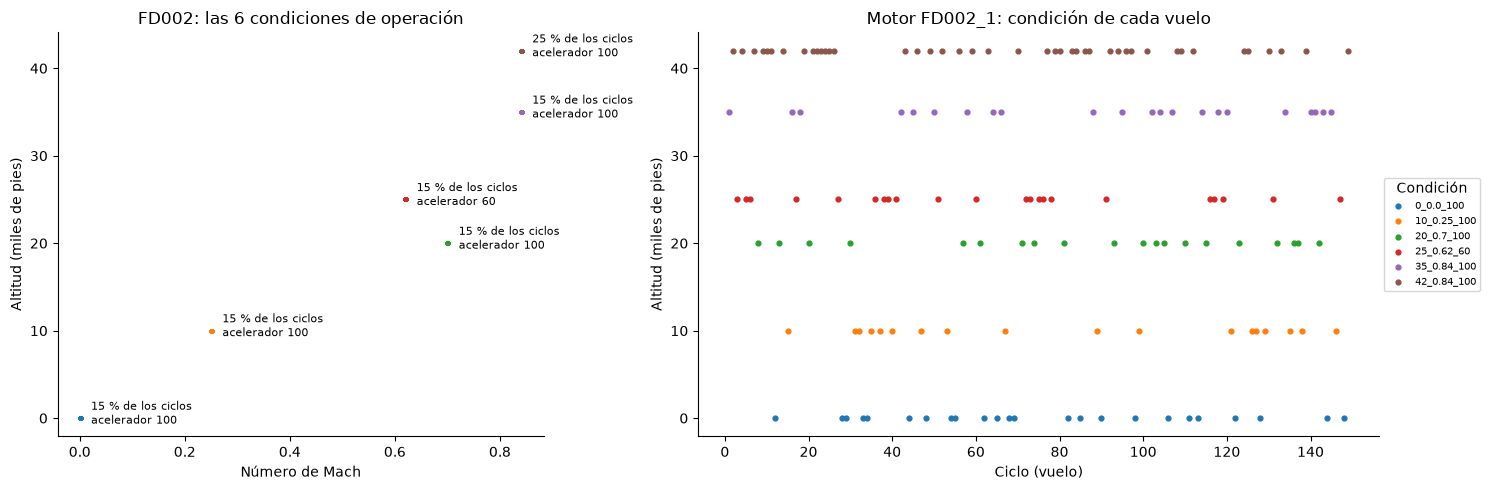

In [10]:
# 1. Resumen de cada condición de FD002: altitud, Mach, acelerador y % de ciclos
fd = "FD002"
tr = train[train["subset"] == fd]
resumen_cond = tr.groupby("condicion").agg(
    altitud=("op_setting_1", "mean"),
    mach=("op_setting_2", "mean"),
    acelerador=("op_setting_3", "mean"),
    ciclos=("cycle", "size"),
)
resumen_cond["%"] = 100 * resumen_cond["ciclos"] / resumen_cond["ciclos"].sum()
# 2. Ciclos del motor FD002_1
motor = tr[tr["engine_id"] == "FD002_1"]

# 3. Izquierda: mapa de las 6 condiciones; derecha: condición de cada vuelo de FD002_1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.4]})
for cond, grupo in tr.groupby("condicion"):
    ax1.scatter(grupo["op_setting_2"], grupo["op_setting_1"], s=4, alpha=0.3)
for cond, fila in resumen_cond.iterrows():
    ax1.annotate(f"{fila['%']:.0f} % de los ciclos\nacelerador {fila['acelerador']:.0f}",
                 (fila["mach"], fila["altitud"]), textcoords="offset points", xytext=(8, -4), fontsize=8)
ax1.set(xlabel="Número de Mach", ylabel="Altitud (miles de pies)", title=f"{fd}: las 6 condiciones de operación")

for cond, grupo in motor.groupby("condicion"):
    ax2.scatter(grupo["cycle"], grupo["op_setting_1"], s=12, label=cond)
ax2.set(xlabel="Ciclo (vuelo)", ylabel="Altitud (miles de pies)", title="Motor FD002_1: condición de cada vuelo")
ax2.legend(title="Condición", fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
guardar_figura("Figura 01 - Condiciones de operación en FD002")
plt.show()

##### Interpretación:
- **Las 6 condiciones son puntos bien separados**, desde nivel del mar (altitud 0, Mach 0) hasta crucero (42 000 pies, Mach 0.84). Solo una usa el acelerador al 60 % (25 000 pies); las demás van al 100 %.
- **Los ciclos se reparten casi por igual:** ≈ 15 % en cada condición, excepto la de 42 000 pies, que tiene el 25 %.
- **El motor FD002_1 cambia de condición en cada vuelo, sin ningún patrón:** en sus 149 vuelos pasa por las 6 condiciones (43 a 42 000 pies, 24 a nivel del mar…). Como cada condición cambia mucho la lectura de los sensores, sin normalizar los sensores saltan entre franjas de un vuelo a otro (ver 4.6). Por eso FD002 y FD004 necesitan la normalización por condición.

### 2.5 Guardar los datos procesados
Se guardan `train` y `test`, ya con `engine_id`, `RUL` y `condicion`, en la carpeta `CMAPSS-v2`. Así no hay que repetir la carga y la preparación cada vez que se abre el notebook.

**¿Qué hace el código?** `mkdir(exist_ok=True)` crea la carpeta si no existe y `to_csv` guarda cada tabla sin la columna del índice.

In [11]:
# Guardar train y test con RUL, engine_id y condición (CSV intermedios)
salida = carpeta / "CMAPSS-v2"
salida.mkdir(exist_ok=True)

train.to_csv(salida / "train_todos.csv", index=False)
test.to_csv(salida / "test_todos.csv", index=False)
print("Guardado en", salida)

Guardado en CMAPSSData\CMAPSS-v2


##### Interpretación:
Quedan guardados `train_todos.csv` y `test_todos.csv` en `CMAPSSData/CMAPSS-v2`.

---
## 3. EDA esencial
Antes de preparar los datos para los modelos se responden cuatro preguntas que guían las decisiones de las siguientes secciones:

1. **3.1** ¿Los datos están limpios?
2. **3.2** ¿Cuánto viven los motores?
3. **3.3** ¿Cómo son los motores de test?
4. **3.4** ¿Cuántos ciclos están en la zona sana y cuántos en la de desgaste? Esto justifica el recorte del RUL a 130.

### 3.1 ¿Los datos están limpios?
Se cuentan los valores faltantes y las filas repetidas para un mismo motor y ciclo. Si hubiera alguno, habría que limpiarlos antes de calcular ventanas o entrenar modelos.

**¿Qué hace el código?** Para train y test, `isna().sum().sum()` cuenta todos los valores faltantes de la tabla y `duplicated(["engine_id", "cycle"])` cuenta las filas que repiten motor y ciclo.

In [12]:
# Valores faltantes en toda la tabla y filas repetidas de un mismo motor y ciclo
for nombre, df in [("train", train), ("test", test)]:
    nulos = df.isna().sum().sum()
    duplicados = df.duplicated(["engine_id", "cycle"]).sum()
    print(f"{nombre}: nulos = {nulos}, duplicados (motor, ciclo) = {duplicados}")

train: nulos = 0, duplicados (motor, ciclo) = 0
test: nulos = 0, duplicados (motor, ciclo) = 0


##### Interpretación:
No hay valores faltantes ni filas duplicadas en train ni en test: no hace falta limpiar nada.

### 3.2 ¿Cuánto viven los motores?
La vida de cada motor es su último ciclo en train. Se resume por subconjunto y se grafica en histogramas, junto con los ciclos que se observan de cada motor de test. Esto muestra qué tan variables son las vidas y da una referencia para el recorte del RUL y el tamaño de las ventanas.

**¿Qué hace el código?**
- `vida`: último ciclo de cada motor de train (cuánto vivió). `observados`: último ciclo de cada motor de test (cuántos ciclos se le alcanzaron a ver).
- `describe()` resume la vida por subconjunto: número de motores, media, desviación, mínimo, cuartiles y máximo.
- Se dibuja un histograma por subconjunto con intervalos de 20 ciclos: barras moradas = vida en train; línea naranja = ciclos observados en test; línea negra punteada = mediana de la vida en train. Arriba a la derecha aparecen el mínimo y el máximo.

        count   mean   std    min    25%    50%    75%    max
subset                                                       
FD001   100.0  206.3  46.3  128.0  177.0  199.0  229.2  362.0
FD002   260.0  206.8  46.8  128.0  174.0  199.0  230.2  378.0
FD003   100.0  247.2  86.5  145.0  189.8  220.5  279.8  525.0
FD004   249.0  246.0  73.1  128.0  190.0  234.0  290.0  543.0


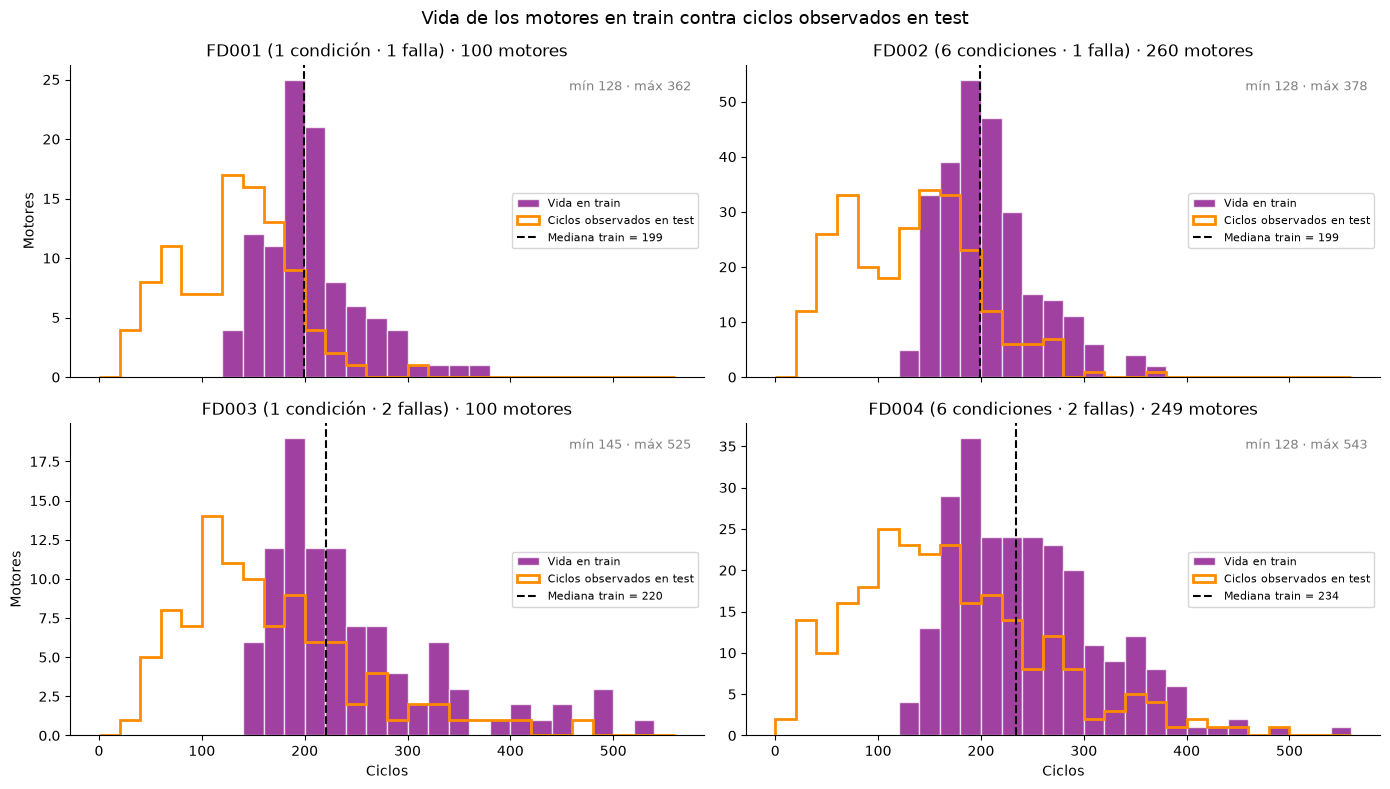

In [13]:
# 1. Vida de cada motor de train y ciclos observados de cada motor de test
vida = train.groupby(["subset", "engine_id"])["cycle"].max()
observados = test.groupby(["subset", "engine_id"])["cycle"].max()
print(vida.groupby("subset").describe().round(1))

# 2. Barras de 20 ciclos y descripción de cada subconjunto
bordes = np.arange(0, vida.max() + 20, 20)
descripcion = {"FD001": "1 condición · 1 falla", "FD002": "6 condiciones · 1 falla",
               "FD003": "1 condición · 2 fallas", "FD004": "6 condiciones · 2 fallas"}

# 3. Un panel por subconjunto: vida en train (barras) contra ciclos observados en test (línea)
fig, ejes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, fd in zip(ejes.flat, Subsets):
    v = vida[fd]
    ax.hist(v, bins=bordes, color="purple", alpha=0.75, edgecolor="white", label="Vida en train")
    ax.hist(observados[fd], bins=bordes, histtype="step", color="darkorange", lw=2,
            label="Ciclos observados en test")
    ax.axvline(v.median(), color="black", ls="--", lw=1.5, label=f"Mediana train = {v.median():.0f}")
    ax.set_title(f"{fd} ({descripcion[fd]}) · {len(v)} motores")
    ax.text(0.98, 0.95, f"mín {v.min()} · máx {v.max()}", transform=ax.transAxes,
            ha="right", va="top", fontsize=9, color="gray")
    ax.legend(fontsize=8, loc="center right")
for ax in ejes[1]:
    ax.set_xlabel("Ciclos")
for ax in ejes[:, 0]:
    ax.set_ylabel("Motores")
fig.suptitle("Vida de los motores en train contra ciclos observados en test", fontsize=13)
plt.tight_layout()
guardar_figura("Figura 02 - Vida de los motores en train y ciclos observados en test")
plt.show()


##### Interpretación:
- En FD001 y FD002 los motores viven entre 128 y 362–378 ciclos, con mediana de 199. En FD003 y FD004, que tienen dos modos de falla, viven más (mediana de 220.5 y 234) y algunos llegan a 525–543 ciclos.
- La media (206–247) es mayor que la mediana porque unos pocos motores con vidas muy largas la jalan hacia arriba (cola larga a la derecha del histograma).
- La línea naranja queda a la izquierda de las barras moradas: de los motores de test se observan **menos ciclos** que la vida completa de train, porque están cortados antes de fallar.
- Ningún motor vive menos de 128 ciclos, así que un recorte del RUL cercano a 130 y ventanas de decenas de ciclos son razonables.

### 3.3 ¿Cómo es test?
Para cada motor de test se obtienen los ciclos observados y su RUL real. Las series de test están **cortadas antes de la falla**, algunas muy cortas. El modelo tendrá que predecir con historias incompletas, y la validación debe imitar esa situación.

**¿Qué hace el código?** Agrupa test por motor, toma su último ciclo observado y su `RUL_final`, y resume ambos por subconjunto con el mínimo, la mediana y el máximo.

In [14]:
# Una fila por motor de test: ciclos observados y RUL real al final
ultimo_test = (test.groupby(["subset", "engine_id"])
               .agg(ciclos_observados=("cycle", "max"),
                    RUL_final=("RUL_final", "first"))
                    .reset_index())
# Mínimo, mediana y máximo por subconjunto
ultimo_test.groupby("subset")[["ciclos_observados", "RUL_final"]].agg(["min", "median", "max"]).round(1)

ciclos_observados             RUL_final            
                     min median  max       min median  max
subset                                                    
FD001                 31  133.5  303         7   86.0  145
FD002                 21  132.0  367         6   80.0  194
FD003                 38  148.0  475         6   77.5  145
FD004                 19  153.5  486         6   88.0  195

##### Interpretación:
- Algunos motores de test se observan muy pocos ciclos (**19 a 38 como mínimo**); la mediana es de 132 a 153.5 ciclos. Con una ventana de 70 ciclos, los motores más cortos tendrán la ventana incompleta (se revisa en 5.4).
- El RUL real de test va de 6–7 **hasta 145** en FD001 y FD003, y **hasta 194–195** en FD002 y FD004, con mediana de 77.5 a 88. Estos rangos definen qué ciclos se evalúan en la validación (6.3).

### 3.4 ¿Cuántos ciclos están en la zona sana y cuántos en la de desgaste?
Cada motor de train pasa por dos etapas:

- **Zona sana (RUL > 130):** el motor casi no se ha desgastado y sus sensores se ven iguales ciclo tras ciclo. Sirve para enseñar al modelo cómo se ve un motor sano, pero **no contiene información sobre cuántos ciclos le quedan**.
- **Zona de desgaste (RUL ≤ 130):** los sensores empiezan a cambiar. Aquí está **la información valiosa** para predecir el RUL.

Se calcula qué porcentaje de los ciclos de train cae en cada zona.

**¿Qué hace el código?** `np.where` etiqueta cada ciclo según su RUL, `pd.crosstab` cuenta los ciclos por subconjunto y zona, se agrega la fila `Todos` y se convierte cada fila a porcentaje.

In [15]:
# Zona de cada ciclo de train según el recorte de 130
zona = np.where(train["RUL"] > 130, "Sana (RUL > 130)", "Desgaste (RUL ≤ 130)")
# Ciclos por zona y subconjunto, más el total
conteo = pd.crosstab(train["subset"], zona)
conteo.loc["Todos"] = conteo.sum()

# Porcentaje de ciclos en cada zona
porcentaje = 100 * conteo.div(conteo.sum(axis=1), axis=0)
porcentaje.round(1)

col_0,Desgaste (RUL ≤ 130),Sana (RUL > 130)
subset,,
FD001,63.5,36.5
FD002,63.3,36.7
FD003,53.0,47.0
FD004,53.3,46.7
Todos,57.9,42.1


##### Interpretación:
- El **58 %** de los ciclos (≈ 93 000) está en la zona de desgaste: es la información valiosa para predecir el RUL, y es suficiente para entrenar.
- El **42 %** (≈ 67 000) está en la zona sana. Es casi la mitad de los datos, y en ella los sensores no permiten distinguir un RUL de otro. Si se le pidiera al modelo el RUL exacto ahí, casi la mitad del entrenamiento serían preguntas sin respuesta posible.
- Por eso se **recorta el RUL a 130**: los ciclos sanos se conservan, pero su respuesta pasa a ser 130 ("le queda bastante"), y el modelo concentra su precisión en la zona de desgaste.
- FD003 y FD004 tienen más ciclos sanos (≈ 47 %) porque sus motores viven más (sección 3.2).

---
## 4. Sensores útiles y normalización por condición
En FD002 y FD004 el motor vuela en 6 condiciones distintas, y cada condición cambia mucho el valor de los sensores. Por ejemplo, T50 vale ≈ 1409 a nivel del mar y ≈ 1050 a 25 000 pies. Este salto es mucho mayor que el cambio que produce el desgaste. Si no se corrige, el modelo confunde "cambio de altitud" con "se está degradando".

La solución es normalizar cada sensor **dentro de su condición**: se le resta la media y se divide entre la desviación estándar de esa condición. Así, un valor de 0 significa "normal para esta condición", y el desgaste aparece como un alejamiento del 0.

Pasos:
1. **4.1** Elegir los sensores que sirven.
   - **4.1 b)** Los 21 sensores de un motor a lo largo de su vida.
2. **4.2** Escribir las funciones para normalizar.
3. **4.3** Normalizar cada subconjunto.
4. **4.4** Verificar la normalización.
5. **4.5** Ver en qué momento de la vida del motor aparece el desgaste.
6. **4.6** Comparar un motor antes y después de normalizar.
   - **4.6 b)** Los sensores útiles de un motor ya normalizados.

### 4.1 ¿Qué sensores sirven?
Un sensor que no cambia dentro de una condición no aporta información sobre el desgaste: **siempre marca lo mismo**, y además al normalizarlo habría que dividir entre una desviación de 0. Para cada subconjunto se conservan solo los sensores cuya desviación estándar es mayor que 0.001 en **todas** sus condiciones.

**¿Qué hace el código?**
- `groupby("condicion")[Sensores].std()` calcula la desviación de cada sensor en cada condición, y `.min()` se queda con la más pequeña.
- Se conservan los sensores cuyo mínimo es mayor que 0.001, y se imprimen los descartados.

In [16]:
def sensores_del_subset(tr):
    """Sensores que varian dentro de todas las condiciones de este subconjunto."""
    # Desviación de cada sensor dentro de cada condición; se toma la más pequeña
    desv_minima = tr.groupby("condicion")[Sensores].std().min()
    # Se conserva el sensor si varía en todas las condiciones (umbral 0.001)
    return [s for s in Sensores if desv_minima[s] > 1e-3]

# Sensores útiles de cada subconjunto, calculados solo con train
sensores_por_subset = {}
for fd in Subsets:
    tr = train[train["subset"] == fd]
    sensores_por_subset[fd] = sensores_del_subset(tr)
    descartados = [s for s in Sensores if s not in sensores_por_subset[fd]]
    print(f"{fd}: {len(sensores_por_subset[fd])} sensores utiles, descartados: {descartados}")

FD001: 15 sensores utiles, descartados: ['T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd']
FD002: 15 sensores utiles, descartados: ['T2', 'P2', 'epr', 'farB', 'Nf_dmd', 'PCNfR_dmd']
FD003: 16 sensores utiles, descartados: ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd']
FD004: 16 sensores utiles, descartados: ['T2', 'P2', 'farB', 'Nf_dmd', 'PCNfR_dmd']


##### Interpretación:
- FD001 y FD002 conservan **15 sensores**; se descartan T2, P2, epr, farB, Nf_dmd y PCNfR_dmd, que no varían dentro de cada condición: sus cambios solo reflejan la condición de vuelo, no el desgaste.
- FD003 y FD004 conservan **16**: en ellos `epr` sí varía, porque responde al segundo modo de falla (desgaste del fan).

#### 4.1 b) Los 21 sensores a lo largo de la vida de un motor
Para ver el criterio de 4.1, se grafican los 21 sensores del motor FD001_1 (sin normalizar) desde su primer ciclo hasta la falla. Se usa FD001 porque tiene una sola condición de vuelo, así que los cambios que se ven solo pueden venir del desgaste o del ruido.

**¿Qué hace el código?** Dibuja una gráfica por sensor (3 filas × 7 columnas). Los sensores útiles van en morado y los descartados en gris, con su estado en el título.

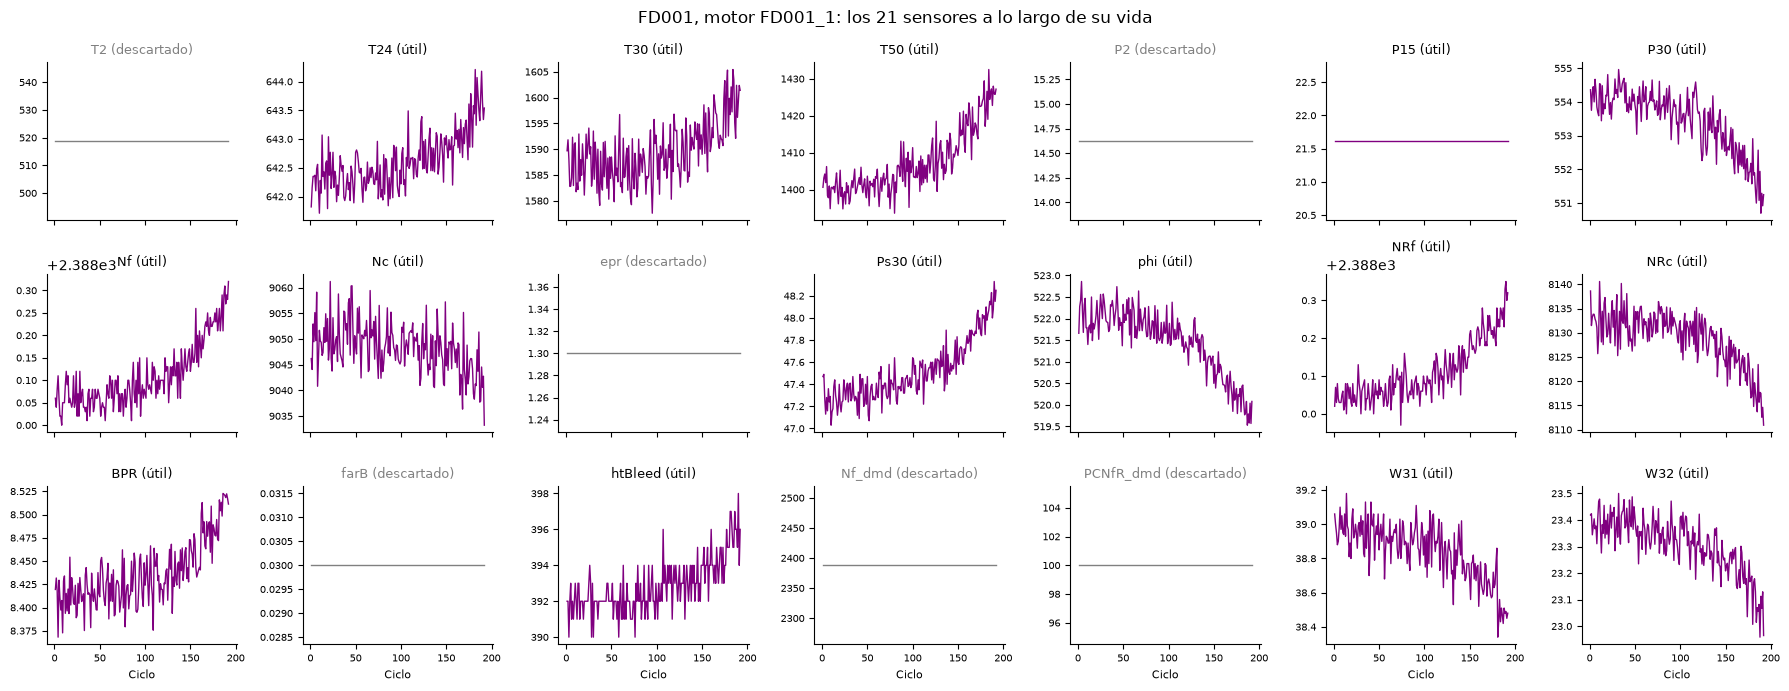

In [17]:
# Motor FD001_1 sin normalizar y sensores útiles de FD001
fd = "FD001"
motor = train[train["engine_id"] == "FD001_1"]
utiles = sensores_por_subset[fd]

# Un panel por sensor: útil en morado, descartado en gris
fig, ejes = plt.subplots(3, 7, figsize=(18, 7), sharex=True)
for ax, s in zip(ejes.flat, Sensores):
    util = s in utiles
    ax.plot(motor["cycle"], motor[s], color="purple" if util else "gray", lw=1)
    ax.set_title(f"{s} ({'útil' if util else 'descartado'})", fontsize=9,
                 color="black" if util else "gray")
    ax.tick_params(labelsize=7)
for ax in ejes[-1]:
    ax.set_xlabel("Ciclo", fontsize=8)
fig.suptitle(f"{fd}, motor FD001_1: los 21 sensores a lo largo de su vida", fontsize=12)
plt.tight_layout()
guardar_figura("Figura 03 - Los 21 sensores del motor FD001_1 sin normalizar")
plt.show()

##### Interpretación:
- **Los 6 sensores descartados son líneas planas:** T2, P2, epr, farB, Nf_dmd y PCNfR_dmd marcan el mismo valor en los 192 ciclos del motor. No pueden aportar información sobre el desgaste.
- **Los sensores útiles muestran la degradación:** Ps30, T50, T24, T30, BPR, htBleed, Nf y NRf suben al acercarse la falla, mientras que P30, phi, W31, W32, Nc y NRc bajan. Por eso se conservan 15 sensores en FD001.
- **P15 es un caso límite:** el criterio lo conserva, pero en este motor es plano. En FD001 solo toma dos valores (21.60 y 21.61), apenas por encima del umbral de 0.001, así que aporta muy poca información. Se mantiene porque el criterio es el mismo para todos los subconjuntos.
- En FD002 y FD004 esta gráfica sin normalizar no serviría: los saltos entre las 6 condiciones de vuelo esconderían todo (ver 4.6). Por eso el criterio de 4.1 mide la variación **dentro** de cada condición.

### 4.2 Funciones para normalizar
Se separa en dos pasos, como los escaladores de scikit-learn:

- **Ajustar:** se calculan la media y la desviación estándar de cada sensor en cada condición, **solo con train**.
- **Aplicar:** se usan esas mismas estadísticas para transformar train y test.

Si se calcularan con test, el modelo tendría información de los motores que se quieren evaluar (fuga de datos).

$$z = \frac{x - \text{media}_{\text{condición}}}{\text{desviación}_{\text{condición}}}$$

**¿Qué hace el código?**
- `ajustar_normalizador` devuelve una tabla con una fila por condición y la media y desviación de cada sensor.
- `normalizar` busca, para cada fila, la media y la desviación de su condición (`map`), resta y divide. `replace(0, np.nan)` y `fillna(0)` evitan dividir entre 0.

In [18]:
def ajustar_normalizador(tr, sensores):
    """Media y desviacion de cada sensor por condicion, calculadas solo con train."""
    return tr.groupby("condicion")[sensores].agg(["mean","std"])

def normalizar(df, estadisticas, sensores):
    """Resta la media y divide entre la desviacion de la condicion de cada fila."""
    # Copia para no modificar la tabla original
    salida = df.copy()
    for s in sensores:
        # Media y desviación de la condición de cada fila
        media = df["condicion"].map(estadisticas[(s, "mean")])
        desv = df["condicion"].map(estadisticas[(s, "std")]).replace(0, np.nan)
        # z-score; si la desviación es 0, el valor queda en 0
        salida[s] = ((df[s] - media) / desv).fillna(0)
    return salida

### 4.3 Normalizar cada subconjunto
Cada subconjunto se normaliza con sus propias estadísticas de train, porque son motores y modos de falla distintos. Luego se vuelven a unir en `train_n` y `test_n`. Las columnas que no son sensores, como `RUL`, `cycle` y `condicion`, se mantienen igual.

**¿Qué hace el código?** Para cada subconjunto ajusta el normalizador con su train y lo aplica a su train y a su test; al final une las partes y cuenta los valores faltantes.

In [19]:
# Normalizar cada subconjunto con sus propias estadísticas
partes_train, partes_test = [], []
for fd in Subsets:
    tr = train[train["subset"] == fd]
    te = test[test["subset"] == fd]
    sensores = sensores_por_subset[fd]
    # Estadísticas solo de train, aplicadas a train y a test (sin fuga de datos)
    estadisticas = ajustar_normalizador(tr, sensores)
    partes_train.append(normalizar(tr, estadisticas, sensores))
    partes_test.append(normalizar(te, estadisticas, sensores))

# Unir los subconjuntos normalizados
train_n = pd.concat(partes_train)
test_n = pd.concat(partes_test)
# Verificación
print("train_n:", train_n.shape, "| test_n:", test_n.shape)
print("Nulos:", train_n.isna().sum().sum(), test_n.isna().sum().sum())

train_n: (160359, 30) | test_n: (104897, 30)
Nulos: 0 0


##### Interpretación:
`train_n` y `test_n` conservan todas las filas y no tienen valores faltantes: todas las condiciones de test tenían estadísticas de train.

### 4.4 Verificación
Se revisa que la normalización haya funcionado, con el sensor T50 como ejemplo.

- **En train:** como cada condición se normalizó con su propia media y desviación, el resultado debe ser **media 0 y desviación 1** en cada condición.
- **En test:** no se espera media 0 ni desviación 1, porque test se normalizó con las estadísticas de train y no con las suyas. Compararlo muestra en qué se diferencian los motores de test de los de train.

**¿Qué hace el código?** Imprime la media y la desviación de T50 normalizado en cada condición de FD002 (train) y en cada subconjunto de test.

In [20]:
# En train, cada condición debe quedar con media ≈ 0 y desviación ≈ 1
print("Train, FD002, T50 por condicion:")
print(train_n[train_n["subset"] == "FD002"].groupby("condicion")["T50"].agg(["mean", "std"]).round(3))

# Test usa las estadísticas de train, así que su media no es exactamente 0
print("\nTest, T50 por subconjunto:")
print(test_n.groupby("subset")["T50"].agg(["mean", "std"]).round(3))

Train, FD002, T50 por condicion:
             mean  std
condicion             
0_0.0_100     0.0  1.0
10_0.25_100  -0.0  1.0
20_0.7_100   -0.0  1.0
25_0.62_60   -0.0  1.0
35_0.84_100  -0.0  1.0
42_0.84_100  -0.0  1.0

Test, T50 por subconjunto:
         mean    std
subset              
FD001  -0.466  0.743
FD002  -0.330  0.804
FD003  -0.399  0.732
FD004  -0.438  0.791


##### Interpretación:
- En train, T50 tiene **media 0 y desviación 1 en las 6 condiciones**: la normalización quedó bien hecha.
- En test, la media es **negativa** (−0.33 a −0.47) y la desviación **menor que 1** (0.73 a 0.80). Los motores de test están cortados antes de fallar: les faltan los últimos ciclos, en los que T50 sube por el desgaste. Por eso sus lecturas quedan, en promedio, un poco por debajo de lo normal de train y varían menos.

### 4.5 Perfil de los sensores según el RUL
Se promedian Ps30, T50 y htBleed normalizados de todos los motores de FD001 para cada valor de RUL, de 300 a 0. La gráfica muestra en qué momento de la vida del motor los sensores empiezan a reflejar el desgaste, y justifica el recorte del RUL.

**¿Qué hace el código?**
- Filtra FD001 con RUL ≤ 300 y calcula el promedio de cada sensor para cada RUL (`groupby("RUL").mean()`).
- Suaviza cada curva con una media móvil de 5 valores.
- Marca el recorte (línea gris) y la zona sana (fondo verde). El eje X está invertido: la falla (RUL 0) queda a la derecha.

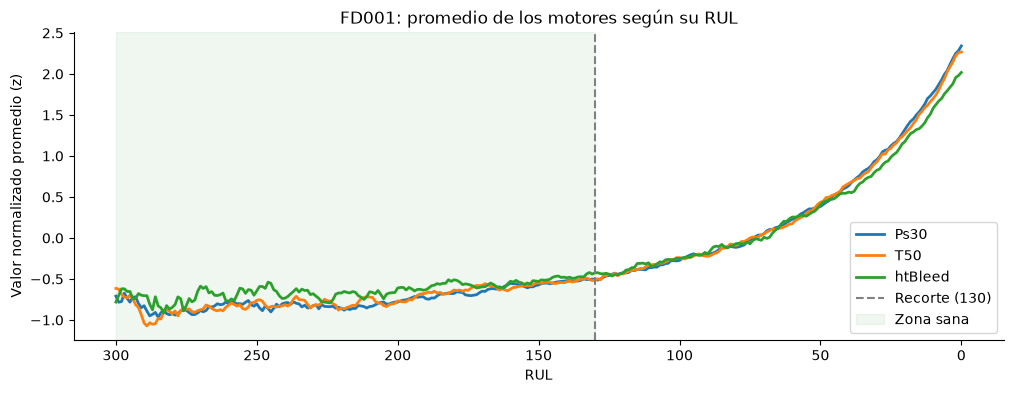

In [21]:
# Ciclos de FD001 con RUL de hasta 300
fd = "FD001"
datos_fd = train_n[(train_n["subset"] == fd) & (train_n["RUL"] <= 300)]
# Promedio de todos los motores para cada valor de RUL
perfil = datos_fd.groupby("RUL")[["Ps30", "T50", "htBleed"]].mean()

fig, ax = plt.subplots(figsize=(12, 4))
# Curvas suavizadas con una media móvil de 5 valores de RUL
for s in perfil.columns: # type: ignore
    ax.plot(perfil.index, perfil[s].rolling(5, center=True, min_periods=1).mean(), lw=2, label=s)
# Línea del recorte y zona sana
ax.axvline(RUL_TOPE if "RUL_TOPE" in globals() else 130, color="gray", ls="--", label="Recorte (130)") # type: ignore
ax.axvspan(300, 130, color="green", alpha=0.06, label="Zona sana")
ax.set(xlabel="RUL", ylabel="Valor normalizado promedio (z)",
       title=f"{fd}: promedio de los motores según su RUL")
# El RUL disminuye hacia la derecha, como avanza la vida del motor
ax.invert_xaxis()
ax.legend()
guardar_figura("Figura 04 - Perfil de los sensores según el RUL en FD001")
plt.show()

##### Interpretación:
- **Arriba de RUL ≈ 130 las curvas cambian muy poco:** Ps30 pasa de ≈ −1.1 (RUL 300) a ≈ −0.6 (RUL 130), apenas 0.5 en 170 ciclos.
- **Por debajo de 130 suben cada vez más rápido:** Ps30 pasa de ≈ −0.4 (RUL 110) a ≈ 0.4 (RUL 50) y ≈ 2.4 (RUL 0), casi 3 unidades en 130 ciclos.
- Es la forma de "codo" que justifica recortar el RUL a 130: arriba de ese punto los sensores casi no distinguen un motor de otro.

### 4.6 Antes y después de normalizar
Se grafica el motor FD002_1 con los cuatro sensores más correlacionados con el RUL (Ps30, T50, BPR y htBleed). Se usa FD002 porque tiene 6 condiciones de operación y un solo modo de falla, así que el efecto de la normalización se ve con claridad.

**¿Qué hace el código?**
- `motor` y `motor_n` son los ciclos de FD002_1 sin normalizar y normalizados.
- Columna izquierda: un punto por ciclo, con un color por condición de vuelo.
- Columna derecha: los mismos ciclos normalizados (gris) y una media móvil de 20 ciclos (morada) que suaviza el ruido.

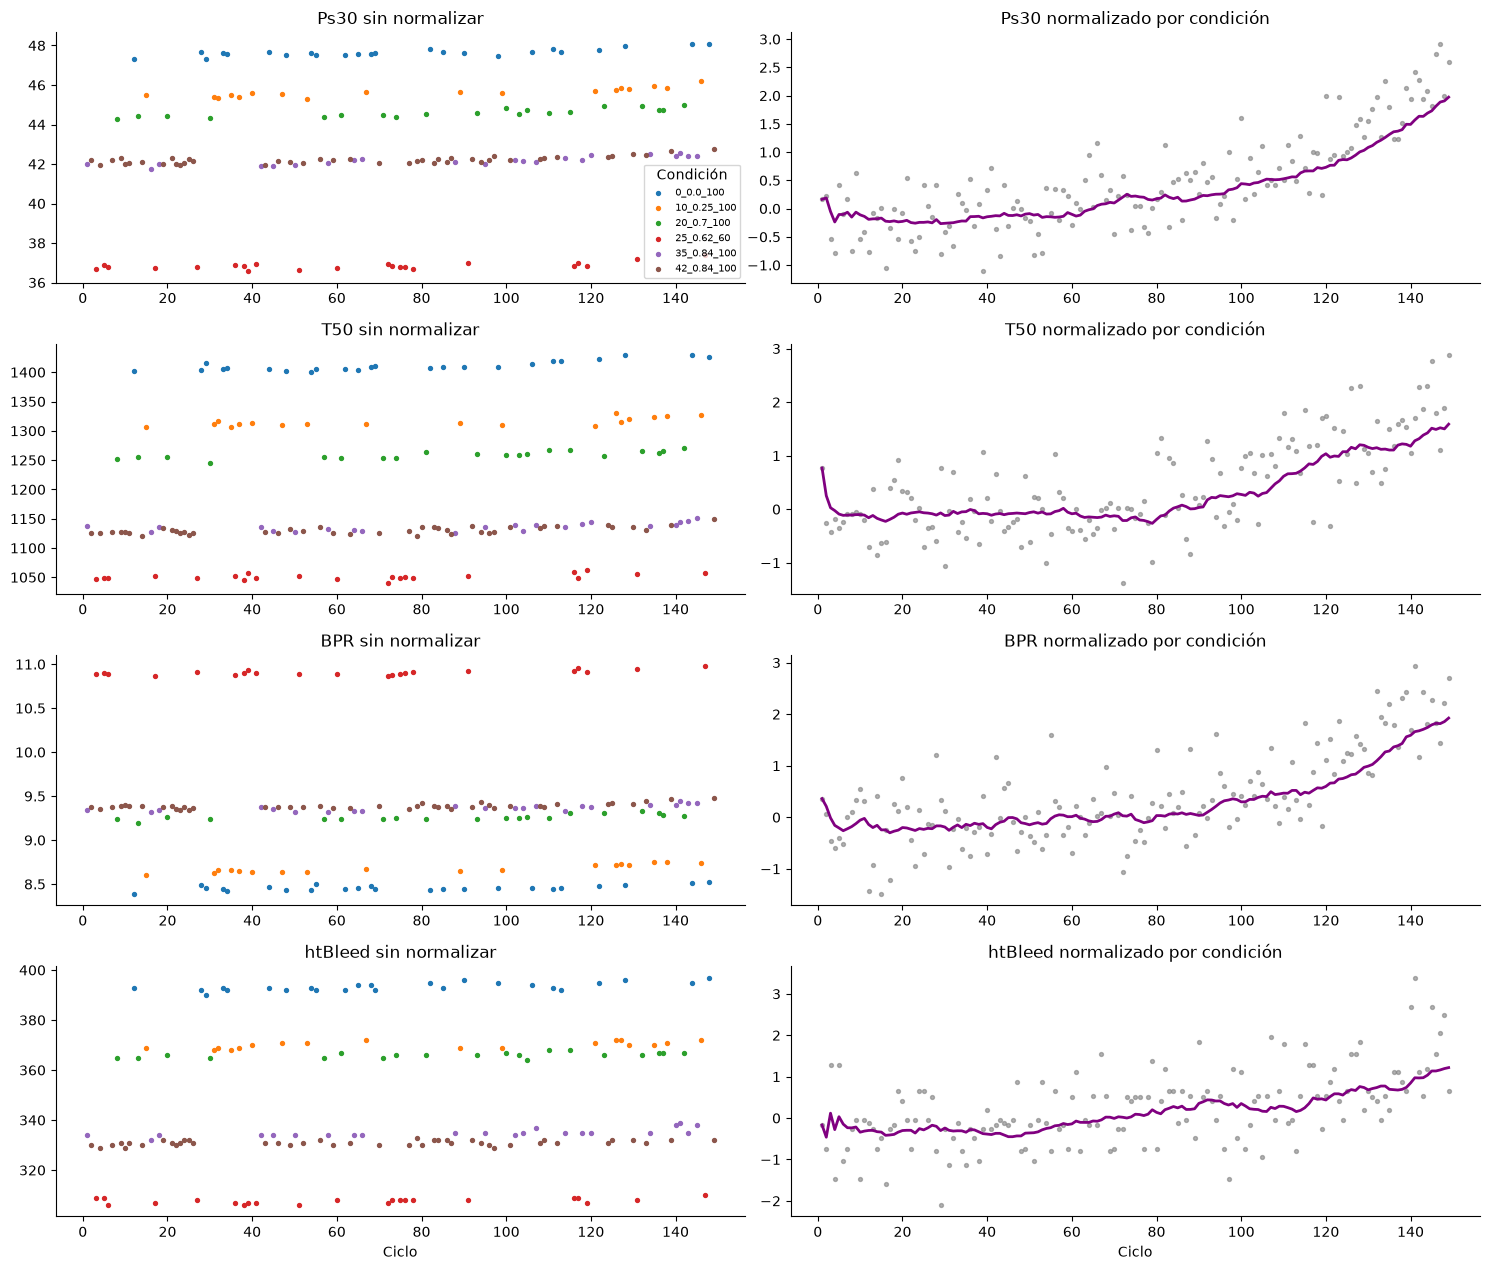

In [22]:
# Motor FD002_1 sin normalizar y normalizado
motor = train[train["engine_id"] == "FD002_1"]
motor_n = train_n[train_n["engine_id"] == "FD002_1"]
sensores_grafica = ["Ps30", "T50", "BPR", "htBleed"]

# Una fila por sensor: izquierda sin normalizar, derecha normalizado
fig, ejes = plt.subplots(len(sensores_grafica), 2, figsize=(15, 3.2 * len(sensores_grafica)))
for fila, s in zip(ejes, sensores_grafica):
    ax1, ax2 = fila
    # Izquierda: un color por condición de vuelo
    for cond, grupo in motor.groupby("condicion"): # type: ignore
        ax1.scatter(grupo["cycle"], grupo[s], s=8, label=cond)
    ax1.set_title(f"{s} sin normalizar")

    # Derecha: ciclos normalizados y media móvil de 20 ciclos
    ax2.scatter(motor_n["cycle"], motor_n[s], s=8, color="gray", alpha=0.6)
    ax2.plot(motor_n["cycle"], motor_n[s].rolling(20, min_periods=1).mean(), color="purple", lw=2)
    ax2.set_title(f"{s} normalizado por condición")

ejes[0, 0].legend(title="Condición", fontsize=7)
for ax in ejes[-1]:
    ax.set_xlabel("Ciclo")
plt.tight_layout()
guardar_figura("Figura 05 - Motor FD002_1 antes y después de normalizar")
plt.show()


##### Interpretación:
- **Izquierda (sin normalizar):** los puntos forman 6 franjas, una por condición; por ejemplo, T50 ≈ 1400 a nivel del mar y ≈ 1050 a 25 000 pies con el acelerador al 60 %. El motor salta de franja en franja según la condición de cada vuelo, y el desgaste, que solo sube un poco dentro de cada franja, queda escondido.
- **Derecha (normalizado por condición):** las franjas desaparecen y todos los ciclos quedan alrededor de 0. La línea morada está plana hasta el ciclo 80–100 (motor sano) y luego sube hasta ≈ 2 cerca del ciclo 149, donde el motor falla.
- Los cuatro sensores muestran el mismo patrón. En BPR la franja más alta sin normalizar es la de 25 000 pies, al revés que en los otros sensores, pero al normalizar cada condición se compara consigo misma y también aparece la subida final.

#### 4.6 b) Los sensores útiles normalizados a lo largo de la vida de un motor
Es la misma gráfica de 4.1 b) (motor FD001_1), pero con los 15 sensores útiles **después de normalizar**. En 4.1 b) cada sensor tenía sus propias unidades (T50 en grados Rankine, Ps30 en psia, phi en una razón de flujo), así que no se podían comparar entre sí. Ahora todos están en la misma escala (desviaciones respecto a lo normal de su condición), con un eje vertical común.

**¿Qué hace el código?**
- `motor_n` son los ciclos normalizados del motor elegido (`motor_id`).
- Por cada sensor útil dibuja los ciclos (puntos grises) y una media móvil de 20 ciclos que suaviza el ruido.
- `cambio` compara la media móvil al final de la vida con la de los primeros 20 ciclos. Si sube más de 0.3, la línea es roja; si baja más de 0.3, azul; si no, gris (sin tendencia).
- `sharey=True` pone todos los sensores en la misma escala vertical, para comparar cuánto se mueve cada uno.
- Para ver un motor con 6 condiciones de vuelo, cambia `motor_id` a `"FD002_1"`.

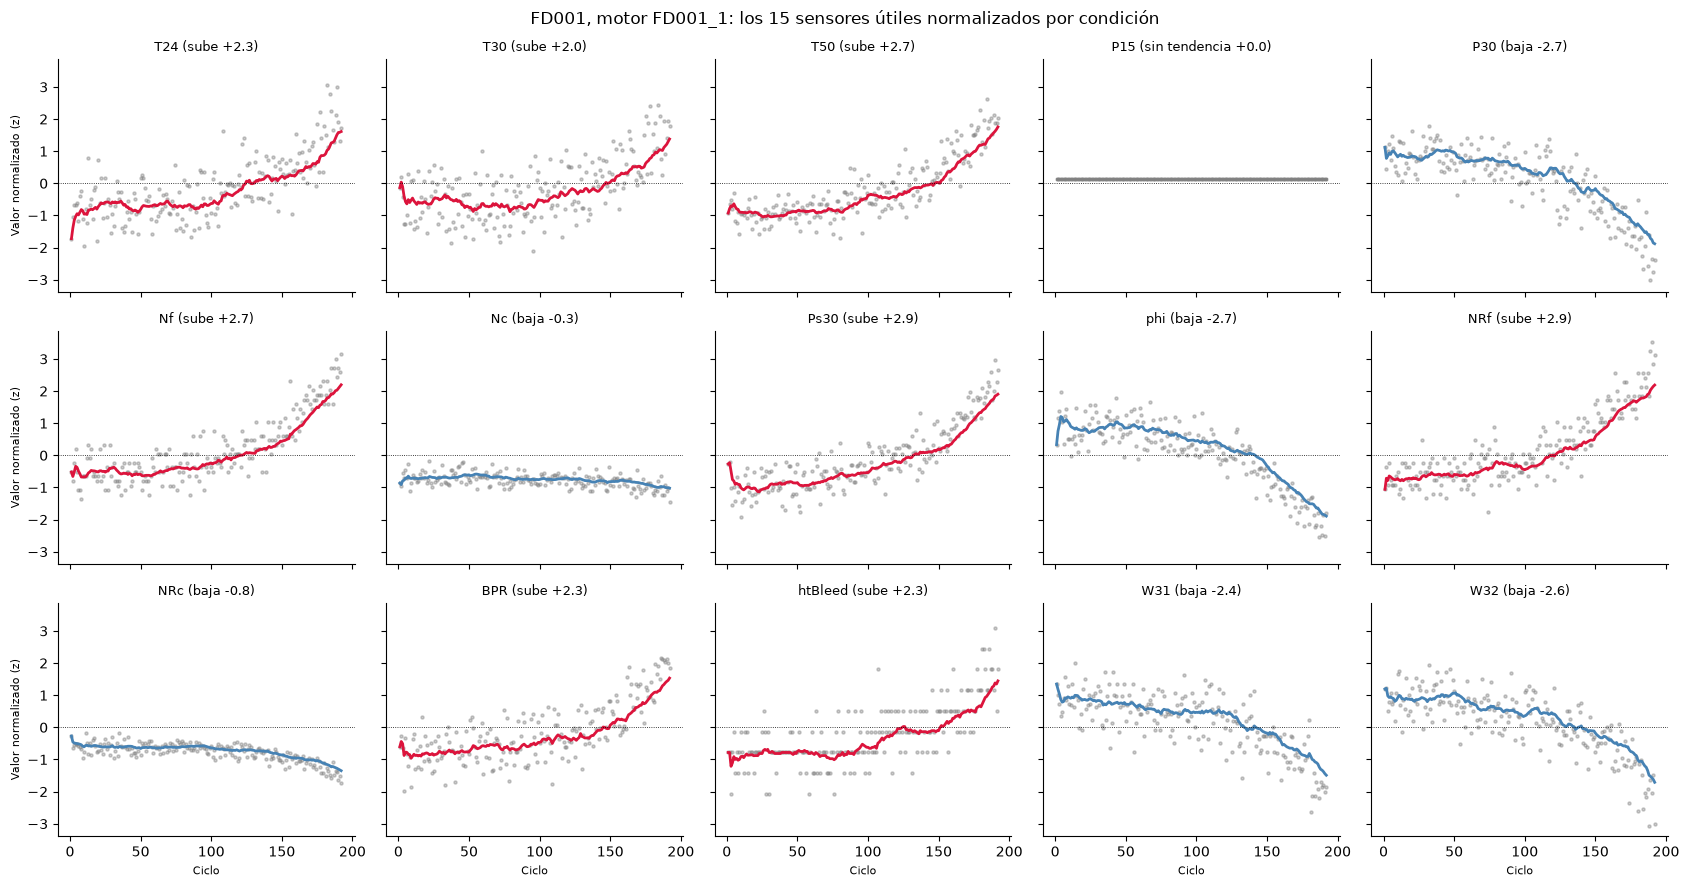

In [23]:
# Motor a graficar y sus sensores útiles
motor_id = "FD001_1"
fd = motor_id.split("_")[0]
utiles = sensores_por_subset[fd]
motor_n = train_n[train_n["engine_id"] == motor_id]

# Cuadrícula de 5 columnas con la misma escala vertical
filas = int(np.ceil(len(utiles) / 5))
fig, ejes = plt.subplots(filas, 5, figsize=(17, 3 * filas), sharex=True, sharey=True)
for ax, s in zip(ejes.flat, utiles):
    # Media móvil de 20 ciclos y cambio entre el inicio y el final de la vida
    suave = motor_n[s].rolling(20, min_periods=1).mean()
    cambio = suave.iloc[-1] - suave.iloc[19]
    # Rojo si sube, azul si baja, gris si cambia menos de 0.3
    if cambio > 0.3:
        color, texto = "crimson", "sube"
    elif cambio < -0.3:
        color, texto = "steelblue", "baja"
    else:
        color, texto = "gray", "sin tendencia"
    ax.scatter(motor_n["cycle"], motor_n[s], s=5, color="gray", alpha=0.4)
    ax.plot(motor_n["cycle"], suave, color=color, lw=2)
    ax.axhline(0, color="black", lw=0.6, ls=":")
    ax.set_title(f"{s} ({texto} {cambio:+.1f})", fontsize=9)

# Ocultar los paneles vacíos
for ax in ejes.flat[len(utiles):]:
    ax.axis("off")
for ax in ejes[-1]:
    ax.set_xlabel("Ciclo", fontsize=8)
for ax in ejes[:, 0]:
    ax.set_ylabel("Valor normalizado (z)", fontsize=8)
fig.suptitle(f"{fd}, motor {motor_id}: los {len(utiles)} sensores útiles normalizados por condición", fontsize=12)
plt.tight_layout()
guardar_figura("Figura 06 - Sensores útiles normalizados del motor FD001_1")
plt.show()

##### Interpretación:
- **Todos los sensores quedan en la misma escala** (entre ≈ −3 y +3), así que ahora sí se puede comparar cuánto se mueve cada uno. Al inicio de la vida casi todos están cerca de su valor normal, y al final se alejan 2–3 desviaciones.
- **8 sensores suben con el desgaste:** Ps30 y NRf (+2.9), T50 y Nf (+2.7), T24, BPR y htBleed (+2.3) y T30 (+2.0). Las temperaturas suben porque el motor gastado necesita más combustible para dar el mismo empuje.
- **6 sensores bajan:** P30 y phi (−2.7), W32 (−2.6) y W31 (−2.4) bajan con fuerza; NRc (−0.8) y Nc (−0.3) casi no cambian, así que aportan poca señal.
- **P15 queda plano** (sin tendencia), igual que en 4.1 b): pasa el criterio de 4.1 por muy poco y en este motor no aporta información.
- **Las curvas son casi planas durante la primera mitad de la vida y se aceleran en los últimos ≈ 50–80 ciclos.** Es el mismo "codo" de 4.5 que justifica el recorte del RUL.
- **Los puntos grises tienen un ruido de ≈ ±1 alrededor de la línea**: en un solo ciclo, la tendencia casi no se distingue del ruido, y solo aparece al promediar varios ciclos. Es la razón de usar ventanas en la sección 5.

---
## 5. Ventanas deslizantes
Un solo ciclo dice poco sobre el estado del motor: las lecturas tienen mucho ruido, y un valor alto puede ser solo ruido. Pero los **últimos ciclos juntos** sí muestran si el motor se está degradando: si el sensor sube, si está inestable, qué tan rápido cambia.

Para cada ciclo de cada motor se toma una **ventana** con sus últimos 70 ciclos y se resume cada sensor en 6 estadísticas:

| Estadística | Qué captura |
|:--|:--|
| `_ult` | Valor del ciclo actual |
| `_media` | Nivel del sensor en la ventana, con menos ruido |
| `_desv` | Qué tan inestable está el sensor |
| `_min`, `_max` | Rango dentro de la ventana |
| `_pend` | **Tendencia**: cuánto cambia por ciclo |

La ventana "se desliza": en el ciclo 100 resume los ciclos 31 a 100; en el 101, los ciclos 32 a 101. Solo mira hacia atrás, así que usa únicamente información disponible al momento de predecir.

Pasos:
1. **5.1** Parámetros (ventana y recorte del RUL).
2. **5.2** Función que calcula las características.
3. **5.3** Conjuntos de entrenamiento y prueba.
4. **5.4** Verificación.
5. **5.5** Qué aporta la ventana en un motor.
6. **5.6** Qué estadísticas tienen más señal.

### 5.1 Parámetros
- `VENTANA = 70`: se usa una ventana de 70 ciclos como valor inicial; en la sección 7 se compara contra 1, 10, 30, 50 y 100 con validación.
- `RUL_TOPE = 130`: el RUL de train se recorta a 130 (secciones 3.4 y 4.5), porque en la zona sana los sensores no permiten distinguir un RUL de otro.

In [24]:
# Ciclos que resume cada ventana (se compara en la sección 7)
VENTANA = 70
# Recorte del RUL de entrenamiento (sección 3.4)
RUL_TOPE = 130

### 5.2 Función de características
Las estadísticas se calculan con `groupby("engine_id").rolling(...)`, para que una ventana **nunca mezcle ciclos de dos motores distintos**.

La pendiente es la de una recta ajustada por mínimos cuadrados a los puntos (ciclo, sensor) de la ventana. Ajustar una recta en cada una de las 160 000 ventanas sería muy lento, así que se usa la fórmula equivalente con promedios móviles:

$$\text{pendiente} = \frac{\overline{t\,x} - \bar{t}\,\bar{x}}{\overline{t^2} - \bar{t}^{\,2}} = \frac{\text{covarianza}(t, x)}{\text{varianza}(t)}$$

donde $t$ es el ciclo, $x$ el sensor y la barra significa "promedio dentro de la ventana".

**¿Qué hace el código?**
1. Ordena las filas por motor y ciclo.
2. Crea columnas auxiliares $t$, $t^2$ y $t \cdot x$ para la pendiente.
3. Calcula los promedios móviles de los sensores y de las auxiliares dentro de cada motor. `min_periods=1` permite ventanas incompletas al inicio de cada motor: se usan los ciclos disponibles.
4. Calcula la desviación, el mínimo y el máximo con la misma ventana (`fillna(0)` para la desviación del primer ciclo, que tiene un solo punto).
5. Arma la tabla `X` con `cycle` y 6 columnas por sensor. La pendiente vale 0 cuando la ventana tiene un solo ciclo.

In [25]:
def caracteristicas_ventana(df, sensores, ventana=VENTANA):
    """Resume los últimos 'ventana' ciclos de cada motor en 6 estadísticas por sensor."""
    # Ordenar por motor y ciclo para que la ventana siga el tiempo
    df = df.sort_values(["engine_id", "cycle"])
    t = df["cycle"].astype(float)

    # Columnas auxiliares para la pendiente: t, t² y t·x
    aux = df[["engine_id"] + sensores].copy()
    aux["t"] = t
    aux["t2"] = t ** 2
    for s in sensores:
        aux[f"tx_{s}"] = t * df[s]

    # Promedios móviles de los sensores y de las auxiliares
    medias_aux = (aux.groupby("engine_id").rolling(ventana, min_periods=1).mean()
                  .reset_index(level=0, drop=True))

    # Desviación, mínimo y máximo de cada sensor en la ventana
    vent = df.groupby("engine_id")[sensores].rolling(ventana, min_periods=1)
    desv = vent.std().reset_index(level=0, drop=True).fillna(0)
    minimos = vent.min().reset_index(level=0, drop=True)
    maximos = vent.max().reset_index(level=0, drop=True)

    # Varianza del tiempo dentro de la ventana
    var_t = medias_aux["t2"] - medias_aux["t"] ** 2

    # Tabla de salida: ciclo + 6 estadísticas por sensor
    X = pd.DataFrame(index=df.index)
    X["cycle"] = df["cycle"]
    for s in sensores:
        X[f"{s}_ult"] = df[s]
        X[f"{s}_media"] = medias_aux[s]
        X[f"{s}_desv"] = desv[s]
        X[f"{s}_min"] = minimos[s]
        X[f"{s}_max"] = maximos[s]
        # Pendiente = covarianza(t, x) / varianza(t)
        cov_tx = medias_aux[f"tx_{s}"] - medias_aux["t"] * medias_aux[s]
        X[f"{s}_pend"] = (cov_tx / var_t).where(var_t > 1e-9, 0.0)
    return X


### 5.3 Conjuntos de entrenamiento y prueba
Para cada subconjunto se calculan las ventanas de train y de test con los datos normalizados de la sección 4. En **test solo se conserva la última ventana de cada motor**, porque el RUL real solo se conoce en el último ciclo observado (sección 2.3).

`datos[fd]` guarda:
- `X_train`: una fila por ciclo de cada motor, con sus características.
- `y_train`: RUL recortado a 130, que es el objetivo de entrenamiento. `y_train_real` conserva el RUL sin recortar.
- `grupos`: el `engine_id` de cada fila, para que la validación separe por motor.
- `X_test`, `y_test`: una fila por motor de test y su RUL real **sin recortar**.
- `motores_test`: el `engine_id` de cada motor de test.

**¿Qué hace el código?** Para cada subconjunto calcula las características de train y de test, usa `idxmax` para encontrar la fila del último ciclo de cada motor de test, y guarda todo en el diccionario `datos`.

In [26]:
# Características de ventana de train y test para cada subconjunto
datos = {}
for fd in Subsets:
    tr = train_n[train_n["subset"] == fd]
    te = test_n[test_n["subset"] == fd]
    sensores = sensores_por_subset[fd]

    X_train = caracteristicas_ventana(tr, sensores)
    X_test_todo = caracteristicas_ventana(te, sensores)
    # En test solo se evalúa el último ciclo observado de cada motor
    ultimo_ciclo = te.groupby("engine_id")["cycle"].idxmax()
    X_test = X_test_todo.loc[ultimo_ciclo]

    # Todo lo que usan las secciones siguientes: características, RUL recortado y real, motores
    datos[fd] = {
        "sensores": sensores,
        "X_train": X_train,
        "y_train": tr.loc[X_train.index, "RUL"].clip(upper=RUL_TOPE),
        "y_train_real": tr.loc[X_train.index, "RUL"],
        "grupos": tr.loc[X_train.index, "engine_id"],
        "X_test": X_test,
        "y_test": te.loc[X_test.index, "RUL_final"],
        "motores_test": te.loc[X_test.index, "engine_id"],
    }
    print(f"{fd}: X_train {X_train.shape}, X_test {X_test.shape}")

FD001: X_train (20631, 91), X_test (100, 91)
FD002: X_train (53759, 91), X_test (259, 91)
FD003: X_train (24720, 97), X_test (100, 97)
FD004: X_train (61249, 97), X_test (248, 97)


##### Interpretación:
- FD001 tiene 20 631 filas de train y 100 de test (una por motor), con **91 columnas**: 15 sensores × 6 estadísticas + `cycle`. FD003 y FD004 tienen **97** (16 sensores).
- Train conserva todas sus filas, porque la ventana se calcula para cada ciclo.

### 5.4 Verificación
Se revisa que las características estén completas: sin faltantes, sin columnas constantes, una fila de test por motor, y cuántos motores de test tienen menos ciclos que la ventana.

**¿Qué hace el código?** Arma una tabla con una columna por subconjunto y una fila por cada revisión.

In [27]:
# Ciclos observados de cada motor de test
ciclos_test = test.groupby(["subset", "engine_id"])["cycle"].max()

# Resumen por subconjunto: tamaños, motores cortos, faltantes y columnas constantes
verificacion = pd.DataFrame({
    fd: {
        "Sensores": len(d["sensores"]),
        "Características": d["X_train"].shape[1],
        "Filas train": len(d["X_train"]),
        "Motores train": d["grupos"].nunique(),
        "Filas test (1 por motor)": len(d["X_test"]),
        f"Motores test con < {VENTANA} ciclos": int((ciclos_test[fd] < VENTANA).sum()),
        "Valores faltantes": int(d["X_train"].isna().sum().sum() + d["X_test"].isna().sum().sum()),
        "Columnas constantes": int((d["X_train"].std() == 0).sum()),
    }
    for fd, d in datos.items()
})
verificacion

,FD001,FD002,FD003,FD004
Sensores,15,15,16,16
Características,91,91,97,97
Filas train,20631,53759,24720,61249
Motores train,100,260,100,249
Filas test (1 por motor),100,259,100,248
Motores test con < 70 ciclos,14,50,10,36
Valores faltantes,0,0,0,0
Columnas constantes,0,0,0,0


##### Interpretación:
- Todo cuadra: una fila de test por motor (100, 259, 100 y 248), sin valores faltantes ni columnas constantes.
- 14, 50, 10 y 36 motores de test tienen menos de 70 ciclos. Su ventana se calcula con los ciclos que hay (`min_periods=1`), igual que en los primeros ciclos de cada motor de train, así que el modelo también aprende con ventanas incompletas.

### 5.5 ¿Qué aporta la ventana?
Se grafica Ps30, el sensor más correlacionado con el RUL, en el motor FD001_1. El eje X es el RUL invertido: avanza hacia la falla de izquierda a derecha.

**¿Qué hace el código?**
- Selecciona las filas del motor FD001_1.
- Izquierda: Ps30 del ciclo actual (gris), media de la ventana (morada) y banda entre el mínimo y el máximo de la ventana.
- Derecha: pendiente de Ps30 en la ventana, con una línea gris en 0.

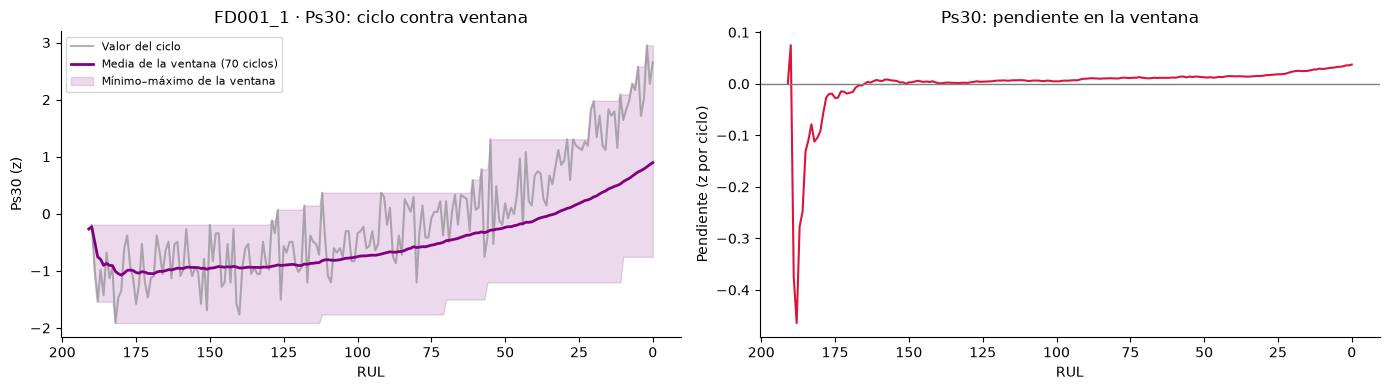

In [28]:
# Motor FD001_1: características de su ventana y su RUL real
d = datos["FD001"]
motor = d["grupos"] == "FD001_1"
X_m, y_m = d["X_train"][motor], d["y_train_real"][motor]

# Izquierda: valor del ciclo contra media y rango de la ventana; derecha: pendiente
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(y_m, X_m["Ps30_ult"], color="gray", alpha=0.6, label="Valor del ciclo")
ax1.plot(y_m, X_m["Ps30_media"], color="purple", lw=2, label=f"Media de la ventana ({VENTANA} ciclos)")
ax1.fill_between(y_m, X_m["Ps30_min"], X_m["Ps30_max"], color="purple", alpha=0.15, label="Mínimo–máximo de la ventana")
ax1.set(xlabel="RUL", ylabel="Ps30 (z)", title="FD001_1 · Ps30: ciclo contra ventana")
ax1.invert_xaxis()
ax1.legend(fontsize=8)

ax2.plot(y_m, X_m["Ps30_pend"], color="crimson")
ax2.axhline(0, color="gray", lw=1)
ax2.set(xlabel="RUL", ylabel="Pendiente (z por ciclo)", title="Ps30: pendiente en la ventana")
ax2.invert_xaxis()
plt.tight_layout()
guardar_figura("Figura 07 - Qué aporta la ventana en Ps30")
plt.show()


##### Interpretación:
- **Izquierda:** el valor de cada ciclo (gris) es muy ruidoso. La media de la ventana (morada) sigue la tendencia de degradación con mucho menos ruido, aunque con algo de retraso, porque incluye ciclos anteriores.
- **Derecha:** la pendiente es ≈ 0 mientras el motor está sano y se vuelve positiva al acercarse la falla, señal de que la degradación se **acelera**. En los primeros ciclos es inestable, porque se calcula con muy pocos puntos.

### 5.6 ¿Qué características tienen más señal?
Se calcula la correlación (en valor absoluto) de cada característica con el RUL recortado, y se promedia por tipo de estadística.

**¿Qué hace el código?** `corrwith` calcula la correlación de cada columna de `X_train` con `y_train`; `correlacion_por_tipo` promedia las columnas que terminan igual (`_ult`, `_media`, …) en cada subconjunto.

In [29]:
# Correlación absoluta promedio de cada tipo de estadística con el RUL recortado
def correlacion_por_tipo(d):
    corr = d["X_train"].corrwith(d["y_train"]).abs()
    return {tipo: corr[[f"{s}_{tipo}" for s in d["sensores"]]].mean()
            for tipo in ["ult", "media", "desv", "min", "max", "pend"]}

# Una columna por subconjunto
pd.DataFrame({fd: correlacion_por_tipo(d) for fd, d in datos.items()}).round(3)

,FD001,FD002,FD003,FD004
ult,0.621,0.544,0.473,0.433
media,0.573,0.610,0.438,0.414
desv,0.551,0.378,0.453,0.401
min,0.424,0.381,0.313,0.267
max,0.548,0.532,0.525,0.504
pend,0.113,0.083,0.138,0.093


##### Interpretación:
- **Último valor, media y máximo** son las estadísticas con más señal (correlación ≈ 0.4–0.6).
- En **FD002 la media (0.610) supera al último valor (0.544)**: con 6 condiciones de vuelo las lecturas son más ruidosas, y promediar la ventana limpia ese ruido.
- La **pendiente** tiene poca correlación por sí sola (≈ 0.1), porque solo cambia cerca de la falla (ver gráfica 5.5). Aun así puede ayudar al modelo combinada con las demás.


---
## 6. Validación por motor
Los motores de test solo se usan **una vez, al final** (sección 9), para la evaluación oficial. Para tomar decisiones (qué ventana, qué modelo, qué hiperparámetros) hay que estimar el error con los datos de train: eso es la **validación**.

La regla: el error siempre se mide con **motores que el modelo no usó para entrenar**, igual que pasará con los motores de test.

Pasos:
1. **6.1** Métricas de error.
   - **6.1 b)** Gráfica de la multa del score NASA.
2. **6.2** Experimento: por qué separar por motor y no por filas.
3. **6.3** Función de validación que imita la evaluación en test.
4. **6.4** Primera prueba de la validación y piso de error.

### 6.1 Métricas de error
- **RMSE:** el error típico en ciclos. Un RMSE de 15 significa que el modelo se equivoca, en promedio, unos 15 ciclos.
- **Score NASA** (Saxena et al., 2008, ec. 11): una "multa" por cada error, que se suma sobre todos los motores. Castiga más el error **tarde** (decir que al motor le queda más vida de la real) que el **temprano**, porque un aviso tardío puede causar una falla en vuelo. La multa crece muy rápido con el tamaño del error. Entre más bajo, mejor.

Con d = RUL predicho − RUL real:
- si d < 0 (temprano), la multa es $e^{-d/13} - 1$;
- si d ≥ 0 (tarde), la multa es $e^{d/10} - 1$.

**¿Qué hace el código?**
- `rmse` calcula la raíz del promedio de los errores al cuadrado.
- `score_nasa` calcula d para cada motor, aplica la fórmula que corresponda con `np.where` y suma las multas.
- Se prueba con un motor al que le quedan 50 ciclos y predicciones de 40, 60, 30 y 70.

In [30]:
def rmse(y_real, y_pred):
    """Error tipico en ciclos."""
    return float(np.sqrt(np.mean((np.asarray(y_real) - np.asarray(y_pred)) ** 2)))

def score_nasa(y_real, y_pred):
    """Multa de NASA: castiga mas predecir tarde (d > 0) que temprano (d < 0)"""
    d = np.asarray(y_pred) - np.asarray(y_real)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

# Prueba: motor con 50 ciclos restantes y predicciones de 40, 60, 30 y 70
print("10 ciclos temprano:", round(score_nasa([50], [40]), 2))
print("10 ciclos tarde: ", round(score_nasa([50], [60]), 2))
print("20 ciclos temprano:", round(score_nasa([50], [30]), 2))
print("20 ciclos tarde: ", round(score_nasa([50], [70]), 2))

10 ciclos temprano: 1.16
10 ciclos tarde:  1.72
20 ciclos temprano: 3.66
20 ciclos tarde:  6.39


##### Interpretación:
Con el mismo tamaño de error, equivocarse **tarde** cuesta más (1.72 contra 1.16). Al duplicar el error, la multa casi se **cuadruplica** (de 1.72 a 6.39): un solo error grande pesa más que varios pequeños.

#### 6.1 b) La multa del score NASA según el error
**¿Qué hace el código?** Calcula la multa de un motor para errores entre −40 y +40 ciclos, con la misma fórmula de `score_nasa`. Dibuja en azul el lado temprano y en rojo el tardío, y marca los ejemplos de ±10 y ±20 ciclos.

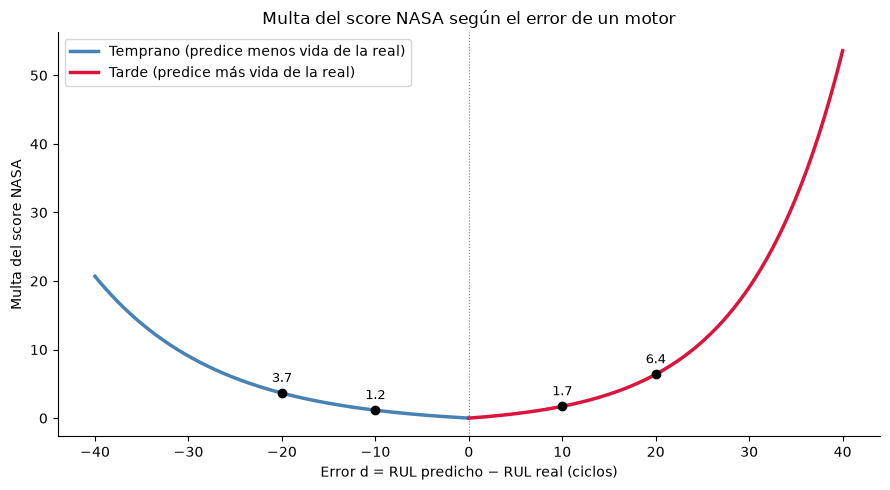

In [31]:
# Errores de −40 a 0 (temprano) y de 0 a 40 (tarde)
temprano = np.linspace(-40, 0, 200)
tarde = np.linspace(0, 40, 200)

# Curva de la multa a cada lado del 0
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(temprano, np.exp(-temprano / 13) - 1, color="steelblue", lw=2.5,
        label="Temprano (predice menos vida de la real)")
ax.plot(tarde, np.exp(tarde / 10) - 1, color="crimson", lw=2.5,
        label="Tarde (predice más vida de la real)")
# Ejemplos de ±10 y ±20 ciclos
for d in [-20, -10, 10, 20]:
    multa = score_nasa([0], [d])
    ax.plot(d, multa, "o", color="black")
    ax.annotate(f"{multa:.1f}", (d, multa), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.axvline(0, color="gray", lw=0.8, ls=":")
ax.set(xlabel="Error d = RUL predicho − RUL real (ciclos)", ylabel="Multa del score NASA",
       title="Multa del score NASA según el error de un motor")
ax.legend()
plt.tight_layout()
guardar_figura("Figura 08 - Multa del score NASA según el error")
plt.show()

##### Interpretación:
- **La curva no es simétrica:** el lado rojo (tarde) sube mucho más rápido que el azul (temprano). Con 10 ciclos de error, la multa es 1.7 si es tarde y 1.2 si es temprano; con 40 ciclos, 53.6 contra 20.7.
- **La multa crece de forma exponencial:** pasar de 20 a 40 ciclos tarde multiplica la multa por 8 (de 6.4 a 53.6). Un solo motor con un error grande pesa más que muchos con errores pequeños.
- El RMSE, en cambio, castiga igual equivocarse 10 ciclos antes o después. Por eso se reportan las dos métricas: el RMSE dice cuánto se equivoca el modelo y el score NASA dice si se equivoca del lado peligroso.

### 6.2 ¿Por qué separar por motor y no por filas?
Los ciclos seguidos de un mismo motor son casi idénticos: el ciclo 80 de un motor se parece mucho a su ciclo 81. Si se separan las filas al azar (`KFold`), el modelo puede entrenar con el ciclo 80 y ser evaluado con el 81; ya "conoce" ese motor y el error sale engañosamente bajo.

Con `GroupKFold` todos los ciclos de un motor van juntos: o se usan para entrenar o para evaluar, nunca las dos cosas.

**Experimento:**
1. Se aparta el 20 % de los motores: son motores nuevos que el modelo nunca verá.
2. Con el resto se estima el error con `KFold` por filas y con `GroupKFold` por motor (5 pliegues).
3. Se comparan ambas estimaciones con el error real en los motores apartados.

Se usa un Random Forest solo para el experimento, en FD001 (el más sencillo) y FD004 (el más difícil). Se usan **5 pliegues**, el valor por defecto de scikit-learn y el más común en los trabajos con C-MAPSS: el modelo entrena con el 80 % de los motores y se evalúa con el 20 % restante.

**¿Qué hace el código?**
- `nuevo_bosque()` crea un Random Forest nuevo, sin entrenar.
- `error_cv(divisor, ...)` entrena y evalúa en cada pliegue del `divisor` y devuelve el RMSE promedio.
- `GroupShuffleSplit` aparta el 20 % de los motores completos.
- Se estima el error con `KFold` y con `GroupKFold`, y se calcula el error real entrenando con el 80 % de los motores y evaluando en los apartados.

In [32]:
from sklearn.model_selection import KFold, GroupKFold, GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor

def nuevo_bosque():
    """Crea un Random Forest nuevo, sin entrenar."""
    return RandomForestRegressor(n_estimators=100, min_samples_leaf=5, max_features=0.3, n_jobs=1, random_state=42)

def error_cv(divisor, X, y, grupos):
    """Entrena y evalúa en cada uno de los 5 pliegues; devuelve el RMSE promedio."""
    errores = []
    for i_ent, i_val in divisor.split(X, y, grupos):
        modelo = nuevo_bosque().fit(X.iloc[i_ent], y.iloc[i_ent])
        y_pred = modelo.predict(X.iloc[i_val])
        errores.append(rmse(y.iloc[i_val], y_pred))
    return np.mean(errores)

# Se compara en un subconjunto simple (FD001) y en uno difícil (FD004)
filas = []
for fd in ["FD001", "FD004"]:
    X, y, g = datos[fd]["X_train"], datos[fd]["y_train"], datos[fd]["grupos"]

    # 1. Apartar el 20 % de los motores como motores nuevos
    apartar = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=0)
    i_resto, i_sorpresa = next(apartar.split(X, y, g))
    X_r, y_r, g_r = X.iloc[i_resto], y.iloc[i_resto], g.iloc[i_resto]

    # 2. Error estimado con KFold por filas y con GroupKFold por motor
    por_filas = error_cv(KFold(5, shuffle=True, random_state=0), X_r, y_r, None)
    por_motor = error_cv(GroupKFold(5, shuffle=True, random_state=0), X_r, y_r, g_r) # type: ignore

    # 3. Error real: entrenar con el resto y evaluar en los motores apartados
    modelo = nuevo_bosque().fit(X_r, y_r)
    real = rmse(y.iloc[i_sorpresa], modelo.predict(X.iloc[i_sorpresa]))

    filas.append({
        "subset": fd,
        "KFold por filas": por_filas,
        "GroupKFold por motor": por_motor,
        "Error real (motores nuevos)": real
    })

pd.DataFrame(filas).set_index("subset").round(2)


,KFold por filas,GroupKFold por motor,Error real (motores nuevos)
subset,,,
FD001,2.52,10.67,13.74
FD004,3.86,13.24,13.95


##### Interpretación:
En las tres columnas se usa **el mismo Random Forest**; lo único que cambia es **la forma de medir su error**.

| | FD001 | FD004 |
|:--|--:|--:|
| KFold por filas | 2.52 | 3.86 |
| GroupKFold por motor | 10.67 | 13.24 |
| Error real (motores nuevos) | 13.74 | 13.95 |

- **Error real:** con motores que nunca vio, el modelo se equivoca ≈ 14 ciclos. Es la referencia.
- **KFold por filas** estima solo ≈ 3–4 ciclos de error. Es una **medición engañada**: al revolver filas, en el examen aparecen ciclos casi idénticos a los que el modelo estudió (por ejemplo, el ciclo 80 y el 81 del mismo motor), así que "se copia". Promete un error 4–5 veces menor que el real.
- **GroupKFold por motor** estima ≈ 11–13 ciclos, **cerca del error real**, porque cada motor queda completo de un solo lado: o se estudia o se examina, nunca las dos cosas.
- En FD004 la estimación de GroupKFold queda aún más cerca del real (13.24 contra 13.95), porque tiene más motores (249 contra 100) y la estimación es más estable.

**Conclusión:** validar revolviendo filas haría creer que el modelo es casi perfecto. Validar por motor da una estimación honesta, por eso **toda la validación del proyecto se hace con `GroupKFold`**.


### 6.3 Función de validación tipo test
La función `validar` estima el error de un modelo y es la que se usa para comparar ventanas (sección 7), modelos (sección 8) y ajustes (sección 9). Para que se parezca a la evaluación final en test:
1. **Motores nuevos:** se separa por motor con `GroupKFold` (5 pliegues), como se justificó en 6.2.
2. **RUL real:** el modelo entrena con el RUL recortado a 130, pero se evalúa contra el RUL **real**, como en test.
3. **Solo ciclos parecidos a test:** se evalúan únicamente los ciclos cuyo RUL está dentro del rango que tiene test (por ejemplo, de 7 a 145 en FD001). Como la ventana solo mira hacia atrás, la fila del ciclo 80 es exactamente lo que se vería si el motor se hubiera cortado en el ciclo 80.
4. **Más rápido:** se entrena con 1 de cada 5 ciclos; los ciclos vecinos son casi idénticos, así que se pierde muy poca información.

Devuelve el **RMSE** y el **score NASA medio** (la multa promedio por predicción).

**¿Qué hace el código?**
- `rango_test`: RUL mínimo y máximo de test en cada subconjunto.
- `y` (RUL recortado) se usa para entrenar y `rul` (RUL real) para evaluar.
- `entrenar` marca 1 de cada 5 ciclos; `evaluar` marca los ciclos con RUL dentro del rango de test.
- `GroupKFold(n_splits=5, shuffle=True, random_state=semilla)` reparte los motores en 5 grupos; la `semilla` cambia qué motores caen juntos.
- En cada pliegue se crea un modelo nuevo con `nuevo_modelo()`, se entrena y se predice. `np.clip(..., 0, None)` evita predicciones negativas.
- `X=None` permite pasar otras características (por ejemplo, otra ventana en la sección 7).

In [33]:
# Rango de RUL que tiene test en cada subconjunto
rango_test = test_n.groupby("subset")["RUL_final"].agg(["min", "max"])
print(rango_test)

def validar(fd, nuevo_modelo, X=None, semilla=0, cada=5):
    """Validación por motor, calificada como test: RUL real dentro del rango de test."""
    d = datos[fd]
    X = d["X_train"] if X is None else X
    y = d["y_train"].to_numpy()           # RUL recortado: con esto se entrena
    rul = d["y_train_real"].to_numpy()    # RUL real: con esto se califica
    grupos = d["grupos"].to_numpy()

    # Filas para entrenar (1 de cada 'cada' ciclos) y filas para evaluar (RUL en el rango de test)
    entrenar = (X["cycle"] % cada == 0).to_numpy()
    minimo, maximo = rango_test.loc[fd] # type: ignore
    evaluar = (rul >= minimo) & (rul <= maximo)

    # 5 pliegues por motor: ningún motor queda en entrenamiento y en validación a la vez
    pred = np.full(len(y), np.nan)
    divisor = GroupKFold(n_splits=5, shuffle=True, random_state=semilla)  # type: ignore
    for i_ent, i_val in divisor.split(X, y, grupos):
        i_ent = i_ent[entrenar[i_ent]]
        i_val = i_val[evaluar[i_val]]
        modelo = nuevo_modelo().fit(X.iloc[i_ent], y[i_ent])
        pred[i_val] = np.clip(modelo.predict(X.iloc[i_val]), 0, None)

    # RMSE contra el RUL real y score NASA promedio por fila evaluada
    return {"RMSE": rmse(rul[evaluar], pred[evaluar]),
            "Score medio": score_nasa(rul[evaluar], pred[evaluar]) / evaluar.sum()}


        min  max
subset          
FD001     7  145
FD002     6  194
FD003     6  145
FD004     6  195


##### Interpretación:
El examen de práctica solo calificará ciclos con RUL entre ≈ 6 y 145 (FD001, FD003) o entre ≈ 6 y 195 (FD002, FD004), igual que el rango de test. En FD002 y FD004, test incluye motores muy sanos (RUL hasta 195); como el modelo nunca predice más de ≈ 130, ahí habrá errores grandes pero **tempranos**, y esos se castigan menos en el score NASA.


### 6.4 Primera prueba de la validación
Se prueba `validar` con dos modelos en los 4 subconjuntos:
- **Promedio** (`DummyRegressor`): a todos los motores les predice el mismo número, el RUL promedio de train. No usa los sensores; es el **piso** que cualquier modelo debe superar.
- **Random Forest:** un modelo real, sin ajustar, para comprobar que la validación distingue un modelo que usa los sensores de uno que no.

**¿Qué hace el código?** Valida ambos modelos en cada subconjunto, junta los resultados y los acomoda con `pivot` en una tabla con el RMSE y el score medio.

In [34]:
from sklearn.dummy import DummyRegressor

def nuevo_promedio():
    """Línea base: siempre predice el RUL promedio de train, sin ver los sensores."""
    return DummyRegressor(strategy="mean")

# Validar la línea base y Random Forest en los 4 subconjuntos
filas = []
for fd in Subsets:
    for nombre, crear in [("Promedio", nuevo_promedio), ("Random Forest", nuevo_bosque)]:
        resultado = validar(fd, crear)
        resultado.update(subset=fd, modelo=nombre)
        filas.append(resultado)
    print(f"{fd} listo")

resultados_6_4 = pd.DataFrame(filas)
resultados_6_4.pivot(index="modelo", columns="subset", values=["RMSE", "Score medio"]).round(2)


FD001 listo
FD002 listo
FD003 listo
FD004 listo


RMSE                      Score medio                        
subset         FD001  FD002  FD003  FD004       FD001   FD002   FD003   FD004
modelo                                                                       
Promedio       41.95  52.87  44.97  53.65      264.83  396.24  567.11  552.70
Random Forest  13.69  25.34  14.05  27.51        3.13   15.20    3.17  177.33

##### Interpretación:
- **El Promedio se equivoca ≈ 42–54 ciclos.** Es el piso: lo que se obtiene sin mirar los sensores.
- **El Random Forest baja el error a ≈ 14 ciclos en FD001/FD003 y ≈ 25–28 en FD002/FD004**: unas 2–3 veces mejor que el Promedio. La validación sí distingue un modelo que aprende de uno que no.
- **FD002 y FD004 son más difíciles** por dos razones: tienen 6 condiciones de vuelo, y en test incluyen motores muy sanos (RUL hasta ≈ 195) que el modelo, por el recorte a 130, siempre subestima.
- **El score NASA** del Random Forest es muy bajo en FD001/FD003 (≈ 3) y alto en FD004 (≈ 177). En FD004 hay algunos errores **tardíos** grandes cerca de la falla, y la multa exponencial los castiga muchísimo. Es una señal de que FD004 necesita un mejor modelo.


---
## 7. Comparación de ventanas
En la sección 5 se usó una ventana de 70 ciclos. Aquí se prueban distintas longitudes con la validación de la sección 6 (`validar`), para elegir la que mejor funciona con los datos:
- **1 ciclo:** sin ventana, el modelo solo ve el ciclo actual. Sirve para comprobar si las ventanas realmente ayudan.
- **10, 30, 50, 70 y 100 ciclos:** de historial corto a largo.

Cada ventana se evalúa en los 4 subconjuntos con **3 semillas** (3 repartos distintos de los motores en los pliegues), para medir qué tanto cambia el resultado solo por azar.

Pasos:
1. **7.1** Validar cada ventana.
2. **7.2** Resumir y elegir la ventana.
3. **7.3** Graficar el error según la ventana.

### 7.1 Validación de cada ventana
Para cada ventana se recalculan las características de train y se pasan a `validar` con el mismo Random Forest de la sección 6. Los resultados se guardan en un CSV para no tener que repetir el cálculo.

**¿Qué hace el código?**
- Para cada ventana y subconjunto, `caracteristicas_ventana(..., v)` recalcula las características con esa ventana.
- `.loc[datos[fd]["X_train"].index]` acomoda las filas en el mismo orden que `y_train` y `grupos`, para que cada fila quede con su RUL y su motor.
- Se valida con las 3 semillas y se guarda cada resultado.
- Al final se guarda todo en `comparacion_ventanas.csv` y se muestran las primeras filas.

Es la celda más pesada hasta este punto: entrena el Random Forest 6 × 4 × 3 × 5 = 360 veces.

In [35]:
import time

# Longitudes de ventana a comparar y semillas de los pliegues
ventanas = [1, 10, 30, 50, 70, 100]
semillas = [0, 1, 2]

filas = []
inicio = time.time()
# Recalcular las características con cada ventana y validar con Random Forest
for v in ventanas:
    for fd in Subsets:
        tr = train_n[train_n["subset"] == fd]
        X_v = caracteristicas_ventana(tr, sensores_por_subset[fd], v).loc[datos[fd]["X_train"].index]
        for s in semillas:
            resultado = validar(fd, nuevo_bosque, X=X_v, semilla=s)
            resultado.update(ventana=v, subset=fd, semilla=s)
            filas.append(resultado)
    print(f"Ventana {v} lista ({time.time() - inicio:.0f} s)")

# Guardar los resultados
comparacion = pd.DataFrame(filas)
comparacion.to_csv("CMAPSSData/CMAPSS-v2/comparacion_ventanas.csv", index=False)
comparacion.head()


Ventana 1 lista (255 s)
Ventana 10 lista (663 s)
Ventana 30 lista (1065 s)
Ventana 50 lista (1487 s)
Ventana 70 lista (1911 s)
Ventana 100 lista (2330 s)


,RMSE,Score medio,ventana,subset,semilla
0,20.749752,11.752339,1,FD001,0
1,20.601451,11.157022,1,FD001,1
2,20.437923,10.903373,1,FD001,2
3,29.945183,32.222294,1,FD002,0
4,29.958371,32.986540,1,FD002,1


##### Interpretación:
Se realizaron **72 exámenes de práctica** (6 ventanas × 4 subconjuntos × 3 semillas). Cada fila de la tabla es uno de ellos: con qué ventana, en qué subconjunto y con qué reparto de motores (semilla) se evaluó, y qué RMSE y score NASA obtuvo el Random Forest.

En las primeras filas ya se ven dos cosas:
- **Las 3 semillas dan resultados casi idénticos** (en FD001 con ventana 1: 20.75, 20.60 y 20.44). El resultado no depende de cómo se repartan los motores en los pliegues.
- **FD002 se equivoca más que FD001** (≈ 30 contra ≈ 20), por los motores muy sanos de su rango de test (ver 6.4).

Los resultados se guardaron en `comparacion_ventanas.csv`. En 7.2 se resumen por ventana para elegir la mejor.


### 7.2 Resumen y elección de la ventana
Se promedia el RMSE de las 3 semillas por ventana y subconjunto. El **± ruido** indica cuánto cambia el promedio al repartir los motores de otra forma en los pliegues.

**Regla de elección (tolerancia del 1 %):** se busca la ventana con menor error y se considera empate cualquier ventana cuyo error esté a menos del 1 % de ella. Entre las empatadas se elige **la más corta**: es más sencilla y deja menos motores de test con la ventana incompleta. Se usa una tolerancia práctica porque el ± ruido de las semillas es muy pequeño (solo reparte de otra forma los mismos motores) y subestima la incertidumbre real.

**¿Qué hace el código?**
- `tabla`: RMSE promedio de las 3 semillas por ventana (filas) y subconjunto (columnas).
- `por_semilla`: promedio de los 4 subconjuntos con cada semilla; su media es el `Promedio` y su desviación el `± ruido`.
- `mejor` es la ventana con menor promedio, `umbral` es su error más 1 %, y `ventana_elegida` es la ventana más corta por debajo del umbral.

In [36]:
# RMSE promedio de las 3 semillas por ventana y subconjunto
tabla = comparacion.groupby(["ventana", "subset"])["RMSE"].mean().unstack()
# Ruido: cuánto cambia el promedio general de una semilla a otra
por_semilla = comparacion.groupby(["ventana", "semilla"])["RMSE"].mean()
tabla["Promedio"] = por_semilla.groupby("ventana").mean()
tabla["± ruido"] = por_semilla.groupby("ventana").std()

# Regla de elección: la ventana más corta a menos de 1 % del menor error
mejor = tabla["Promedio"].idxmin()
umbral = tabla.loc[mejor, "Promedio"] * 1.01 # type: ignore
ventana_elegida = tabla.index[tabla["Promedio"] <= umbral].min()

print(f"Ventana con menor error: {mejor} (RMSE {tabla.loc[mejor, 'Promedio']:.2f})") # type: ignore
print(f"Umbral (menor error + 1 %): {umbral:.2f}")
print(f"Ventana elegida (la más corta dentro del umbral): {ventana_elegida}")
tabla.round(2)


Ventana con menor error: 100 (RMSE 20.10)
Umbral (menor error + 1 %): 20.30
Ventana elegida (la más corta dentro del umbral): 70


subset,FD001,FD002,FD003,FD004,Promedio,± ruido
ventana,,,,,,
1,20.60,29.95,20.48,31.74,25.69,0.09
10,20.15,29.38,19.88,31.34,25.19,0.09
30,16.64,28.03,15.68,29.44,22.45,0.07
50,14.29,26.28,14.33,28.02,20.73,0.05
70,13.55,25.37,14.18,27.52,20.16,0.01
100,13.56,25.03,14.45,27.34,20.10,0.04


##### Interpretación:
- **Sin ventana (1 ciclo) el error es el más alto** (25.69). Ver solo el ciclo actual no basta: el modelo necesita la tendencia reciente del motor.
- **De 10 a 70 ciclos el error baja mucho** (25.19 → 20.16). En FD001 pasa de 20.6 a 13.6, un tercio menos de error.
- **De 70 a 100 ya casi no mejora** (20.16 → 20.10, apenas 0.06 ciclos). La ganadora cambia según el subconjunto: 100 en FD002/FD004, 70 en FD003 y empate en FD001.
- Con la tolerancia del 1 % se elige **VENTANA = 70**: se equivoca prácticamente igual que 100, pero deja menos motores de test con la ventana incompleta (por ejemplo, en FD002 son 50 motores con menos de 70 ciclos contra 91 con menos de 100).
- En FD002 y FD004 la ventana mejora menos (≈ 30 → 25–27) porque gran parte de su error viene de los motores muy sanos (RUL > 130), donde ninguna ventana ayuda por el recorte (ver 6.4).


### 7.3 Error según la ventana
Cada línea es el RMSE de validación de un subconjunto para cada longitud de ventana. La línea roja marca la ventana elegida en 7.2.

**¿Qué hace el código?** Dibuja una línea por subconjunto, la línea vertical de la ventana elegida y, junto a cada punto de esa ventana, el RMSE del subconjunto (`annotate`).

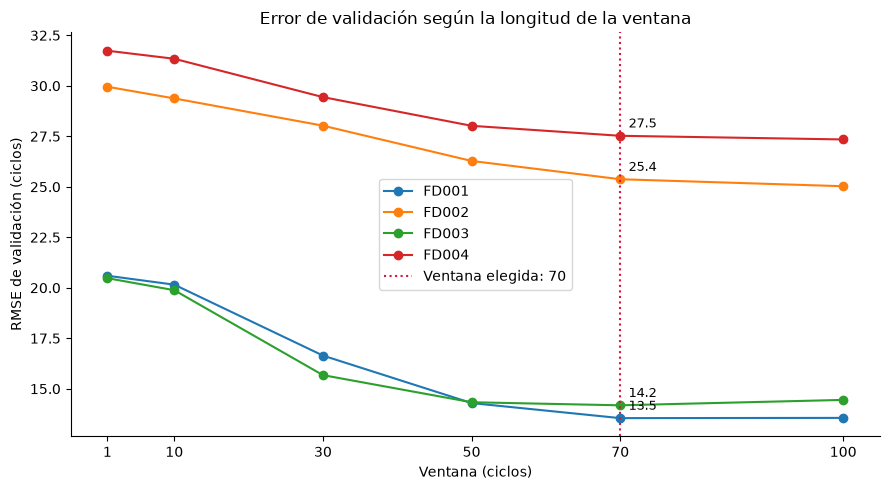

In [37]:
# Una línea por subconjunto y el RMSE de la ventana elegida
fig, ax = plt.subplots(figsize=(9, 5))
for fd in Subsets:
    ax.plot(tabla.index, tabla[fd], marker="o", label=fd)
    rmse_elegida = tabla.loc[ventana_elegida, fd]
    ax.annotate(f"{rmse_elegida:.1f}", (ventana_elegida, rmse_elegida),
                textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.axvline(ventana_elegida, color="crimson", ls=":", lw=1.5,
           label=f"Ventana elegida: {ventana_elegida}")
ax.set(xlabel="Ventana (ciclos)", ylabel="RMSE de validación (ciclos)",
       title="Error de validación según la longitud de la ventana")
ax.set_xticks(tabla.index)
ax.legend()
plt.tight_layout()
guardar_figura("Figura 09 - Error de validación según la ventana")
plt.show()

##### Interpretación:
- **Todas las líneas bajan de izquierda a derecha:** dar más historial al modelo reduce el error. El salto más grande está entre 10 y 50 ciclos.
- **A partir de 70 ciclos las líneas se aplanan:** pasar de 70 a 100 casi no cambia el error en ningún subconjunto.
- **Con la ventana elegida (70)** el error es de 13.6 (FD001), 25.4 (FD002), 14.2 (FD003) y 27.5 (FD004) ciclos.
- **Hay dos parejas de líneas:** FD001 y FD003 abajo, FD002 y FD004 arriba. Tienen la misma forma, así que la ventana ayuda a todos, pero FD002 y FD004 parten de más arriba por los motores muy sanos de su rango de test (ver 6.4).

---
## 8. Comparación de modelos
Se comparan 6 modelos de regresión con la misma validación de la sección 6 (`validar`) y la ventana elegida en la sección 7 (70 ciclos). Todos usan hiperparámetros por defecto o razonables, **sin ajustar**: aquí solo se busca qué tipo de modelo funciona mejor; el ajuste se hace en la sección 9.

| Modelo | Cómo estima el RUL de un motor |
|:--|:--|
| **Ridge** | Una sola fórmula lineal para todos los motores: suma cada característica multiplicada por un peso. |
| **kNN** | Busca en train los 5 ciclos cuyos sensores más se parecen a los del motor y promedia su RUL. |
| **SVR** | Ajusta una curva que pase lo más cerca posible de los datos, ignorando errores pequeños. |
| **Random Forest** | 100 árboles de preguntas sobre los sensores ("¿Ps30 > 1.2? ¿T50 sube?"), entrenados por separado; promedia sus respuestas (*bagging*). |
| **XGBoost** | Árboles en cadena (*boosting*): cada árbol nuevo corrige el error de los anteriores. Los árboles crecen nivel por nivel. |
| **LightGBM** | También *boosting*, pero cada árbol crece hoja por hoja, dividiendo la hoja que más reduce el error. Usa los parámetros de *fleet-readiness*. |

El **Promedio** (Dummy) se incluye como piso.

Pasos:
1. **8.1** Definir los modelos.
2. **8.2** Validar los modelos.
3. **8.3** Comparar los resultados.

### 8.1 Definición de los modelos
Cada modelo se define como una función que crea un modelo nuevo, sin entrenar (igual que `nuevo_bosque` en la sección 6).

Ridge, kNN y SVR trabajan con **distancias o pesos**, así que necesitan que todas las características estén en la misma escala: se les agrega un `StandardScaler` (por ejemplo, `cycle` va de 1 a 362, pero las pendientes son números como 0.01). A SVR también se le escala el RUL objetivo, porque sus parámetros por defecto están pensados para valores cercanos a 0. Los modelos de árboles (Random Forest, XGBoost y LightGBM) no necesitan escalar.

**¿Qué hace el código?**
- `make_pipeline(StandardScaler(), modelo)` escala las características y luego entrena el modelo. El escalador aprende sus medias solo con los motores de entrenamiento de cada pliegue, así que no hay fuga de datos.
- `TransformedTargetRegressor` escala el RUL antes de entrenar SVR y regresa la predicción a ciclos al final.
- XGBoost usa 300 árboles, `learning_rate` 0.05 y profundidad 6. LightGBM usa 500 árboles, `learning_rate` 0.03 y 31 hojas.
- `modelos` es un diccionario con el nombre de cada modelo y su receta; reutiliza `nuevo_promedio` y `nuevo_bosque` de la sección 6.

In [38]:
# Modelos a comparar; cada función crea un modelo nuevo, sin entrenar
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.compose import TransformedTargetRegressor
from xgboost import XGBRegressor
import lightgbm as lgb

# LightGBM con los parámetros de fleet-readiness
def nuevo_lgbm():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=31,
                             min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0,
                             n_jobs=-1, random_state=42, verbose=-1)
# Ridge, kNN y SVR dependen de la escala: se estandarizan las columnas
def nuevo_ridge():
    return make_pipeline(StandardScaler(), Ridge())

def nuevo_knn():
    return make_pipeline(StandardScaler(), KNeighborsRegressor(n_jobs=-1))

# SVR también estandariza el RUL
def nuevo_svr():
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), SVR()),
                                      transformer=StandardScaler())

def nuevo_xgb():
    return XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                        tree_method="hist", n_jobs=-1, random_state=42)

# Nombre del modelo → función que lo crea
modelos = {
    "Promedio": nuevo_promedio,
    "Ridge": nuevo_ridge,
    "kNN": nuevo_knn,
    "SVR": nuevo_svr,
    "Random Forest": nuevo_bosque,
    "XGBoost": nuevo_xgb,
    "LightGBM": nuevo_lgbm
}


### 8.2 Validación de los modelos
Cada modelo se valida con `validar` en los 4 subconjuntos. Los resultados se guardan en un CSV.

**¿Qué hace el código?** Recorre el diccionario `modelos`, valida cada uno en los 4 subconjuntos, imprime cuánto tardó y guarda los resultados en `comparacion_modelos.csv`.

In [39]:
# Validar cada modelo en los 4 subconjuntos y medir su tiempo
filas = []
for nombre, crear in modelos.items():
    inicio = time.time()
    for fd in Subsets:
        resultado = validar(fd, crear)
        resultado.update(modelo=nombre, subset=fd)
        filas.append(resultado)
    print(f"{nombre} listo ({time.time() - inicio:.0f} s)")

# Guardar los resultados
resultados_modelos = pd.DataFrame(filas)
resultados_modelos.to_csv("CMAPSSData/CMAPSS-v2/comparacion_modelos.csv", index=False)


Promedio listo (1 s)
Ridge listo (1 s)
kNN listo (3 s)
SVR listo (82 s)
Random Forest listo (141 s)
XGBoost listo (36 s)
LightGBM listo (19 s)


##### Interpretación:
Los modelos más lentos son Random Forest (127 s) y SVR (68 s). Random Forest tarda más porque `nuevo_bosque` usa un solo núcleo del procesador (`n_jobs=1`). XGBoost (33 s) y LightGBM (17 s) son mucho más rápidos, y Ridge, kNN y el Promedio tardan 1–2 segundos.

### 8.3 Resultados
Se muestran el RMSE y el score NASA medio de cada modelo por subconjunto, y una gráfica del RMSE.

**¿Qué hace el código?**
- `pivot` acomoda los resultados con un modelo por fila y un subconjunto por columna; `.loc[orden]` los ordena del más simple al más complejo, y se agrega el promedio.
- `display` muestra las dos tablas.
- La gráfica de barras compara el RMSE por subconjunto; no incluye al Promedio, porque sus barras de ≈ 50 aplastarían a las demás.

RMSE (ciclos)


subset,FD001,FD002,FD003,FD004,Promedio
modelo,,,,,
Promedio,41.95,52.87,44.97,53.65,48.36
Ridge,20.48,31.03,19.98,33.36,26.22
kNN,19.41,31.72,19.01,32.31,25.61
SVR,14.74,27.06,14.92,28.08,21.20
Random Forest,13.69,25.34,14.05,27.51,20.15
XGBoost,13.66,24.62,13.24,26.80,19.58
LightGBM,12.82,24.49,12.77,26.61,19.17


Score NASA medio


subset,FD001,FD002,FD003,FD004,Promedio
modelo,,,,,
Promedio,264.83,396.24,567.11,552.70,445.22
Ridge,32.62,175.12,10.30,311.52,132.39
kNN,11.57,50.20,10.21,169.28,60.31
SVR,3.52,20.03,12.69,154.27,47.63
Random Forest,3.13,15.20,3.17,177.33,49.71
XGBoost,3.21,14.14,2.83,237.30,64.37
LightGBM,2.69,13.82,2.57,226.98,61.51


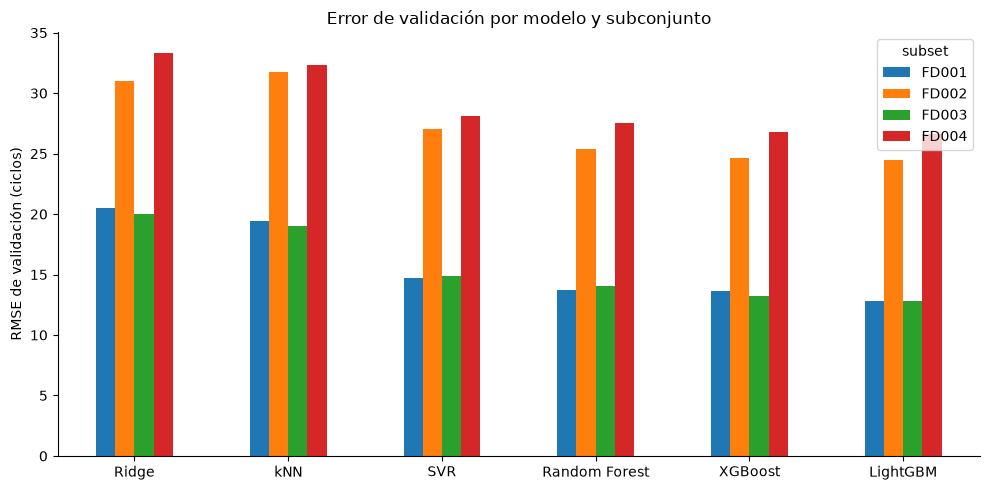

In [40]:
# Tablas de RMSE y score NASA, en el orden de los modelos
orden = list(modelos)

tabla_rmse = resultados_modelos.pivot(index="modelo", columns="subset", values="RMSE").loc[orden]
tabla_rmse["Promedio"] = tabla_rmse.mean(axis=1)

tabla_score = resultados_modelos.pivot(index="modelo", columns="subset", values="Score medio").loc[orden]
tabla_score["Promedio"] = tabla_score.mean(axis=1)

print("RMSE (ciclos)")
display(tabla_rmse.round(2))
print("Score NASA medio")
display(tabla_score.round(2))

# Gráfica de barras sin el promedio
ax = tabla_rmse.drop(index="Promedio", columns="Promedio").plot.bar(figsize=(10, 5), rot=0)
ax.set(xlabel="", ylabel="RMSE de validación (ciclos)", title="Error de validación por modelo y subconjunto")
plt.tight_layout()
guardar_figura("Figura 10 - Error de validación por modelo")
plt.show()


##### Interpretación:
- **Todos los modelos le ganan con mucho al Promedio** (≈ 48 ciclos): todos aprenden algo de los sensores.
- **Ridge y kNN** (≈ 26 ciclos) son los más débiles. Ridge solo puede trazar relaciones en línea recta, y el desgaste tiene forma de "codo" (4.5). kNN promedia ciclos parecidos, pero con 91–97 características le cuesta saber qué motores se parecen realmente en su desgaste.
- **SVR** (21.20) mejora bastante, porque puede trazar curvas.
- **Los modelos de árboles son los mejores**: Random Forest (20.15), XGBoost (19.58) y **LightGBM (19.17)**. LightGBM tiene el menor RMSE en los 4 subconjuntos y el menor score en FD001, FD002 y FD003. La comparación lo favorece un poco: sus parámetros ya venían ajustados por *fleet-readiness*, mientras que XGBoost usa valores base.
- **Score NASA:** en FD004 el score de todos es alto (154–311), porque unos pocos errores muy grandes dominan la multa (en 6.4 se vio que el 1 % de las predicciones causa ≈ 90 % del score). Por eso el promedio del score no es buen criterio para elegir modelo y se usa el **RMSE como criterio principal**.
- Con base en estos resultados se elige **LightGBM** como modelo final, que se ajusta en la sección 9.

---
## 9. LightGBM: ajuste y evaluación final
En la sección 8, **LightGBM** fue el modelo con menor error de validación (19.17 ciclos). Además, es el modelo base de *fleet-readiness*, el trabajo de referencia más cercano a este proyecto, así que se puede comparar en igualdad de condiciones. En esta sección se mejora y se evalúa como modelo final.

Pasos:
1. **9.1** Receta de LightGBM.
2. **9.2** Ventanas combinadas: agregar una ventana corta a la de 70 ciclos.
3. **9.3–9.4** Ajuste de hiperparámetros con **Optuna** y comprobación con 3 semillas.
4. **9.5–9.12** Modelo final, evaluación **una sola vez** en test, comparación con otros trabajos, gráficas, qué aprendió el modelo, un modelo preentrenado (Chronos-2) y predicciones.

**Flujo de la sección:**

```
receta de LightGBM (9.1) → ¿ventana corta + larga? (9.2) → ajuste con Optuna (9.3) → ¿mejora real? (9.4)
        → modelo final y test, una sola vez (9.5) → comparación, gráficas y error por zona (9.6–9.8)
        → trayectoria de un motor e importancia de las características (9.9–9.10)
        → ¿ayuda Chronos-2? (9.11) → CSV (9.12)
```

Del 9.1 al 9.4 todo se decide con la **validación por motor** (`validar`, sección 6). Test solo aparece en el 9.5.

### 9.1 Receta de LightGBM
Se parte de los mismos parámetros que en la sección 8, tomados de *fleet-readiness*:

| Parámetro | Valor | Qué controla |
|:--|:--|:--|
| `n_estimators` | 500 | Cuántos árboles hay en la cadena; cada uno corrige el error de los anteriores. |
| `learning_rate` | 0.03 | Qué fracción del error corrige cada árbol (3 %). |
| `num_leaves` | 31 | Cuántas hojas (grupos de ciclos con un RUL parecido) puede tener cada árbol. |
| `min_child_samples` | 20 | Cuántos ciclos debe tener como mínimo una hoja. |
| `subsample` / `subsample_freq` | 0.8 / 1 | Cada árbol se entrena con el 80 % de los ciclos, sorteados de nuevo en cada árbol. |
| `colsample_bytree` | 0.8 | Cada árbol ve el 80 % de las columnas. |
| `reg_lambda` | 1.0 | Penalización que evita que una hoja dé predicciones extremas. |

**¿Qué hace el código?**
- `PARAMS_LGBM` guarda estos parámetros en un diccionario, para poder modificarlos en Optuna (9.3).
- `receta_lgbm(parametros)` fabrica una receta que crea un LightGBM nuevo con esos parámetros, como `nuevo_lgbm` en la sección 8. `validar` la necesita para crear un modelo sin entrenar en cada pliegue.

In [41]:
# Parámetros base de LightGBM (fleet-readiness)
PARAMS_LGBM = dict(n_estimators=500, learning_rate=0.03, num_leaves=31, min_child_samples=20,
                   subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0)

def receta_lgbm(parametros):
    """Devuelve una receta que crea un LightGBM nuevo con esos parámetros."""
    def crear():
        return lgb.LGBMRegressor(**parametros, n_jobs=-1, random_state=42, verbose=-1)
    return crear

### 9.2 Ventanas combinadas
Hasta ahora cada fila resume los **últimos 70 ciclos** de cada sensor. Una ventana larga capta la tendencia de fondo, pero **diluye los cambios recientes**: si Ps30 sube mucho en los últimos 10 ciclos, el promedio de 70 apenas se mueve.

Con **ventanas combinadas** se calculan las 6 estadísticas dos veces, con una ventana corta y con la larga, y se ponen lado a lado (`Ps30_media_10`, `Ps30_media_70`, …). Así el modelo puede comparar el estado reciente del motor con su tendencia: si `Ps30_media_10` es mucho mayor que `Ps30_media_70`, el desgaste se está acelerando.

Se comparan 70 sola, 10 + 70 y 30 + 70 con LightGBM. Las columnas pasan de 91–97 a 181–193.

**¿Qué hace el código?**
- `ventanas_combinadas(df, sensores, corta, larga)` llama dos veces a `caracteristicas_ventana` (lección 5), una con la ventana corta y otra con la larga. Agrega a cada columna el sufijo de su ventana (`_10`, `_70`) y las pega lado a lado. Se deja una sola columna `cycle`.
- `.loc[datos[fd]["X_train"].index]` acomoda las filas en el mismo orden que `y_train` y `grupos`, para que cada fila quede con su RUL y su motor.
- `X_comb` guarda las características de cada combinación y subconjunto, para reutilizarlas en Optuna y en el modelo final sin recalcularlas.
- Cada combinación se valida con LightGBM (parámetros base). `ventanas_elegidas` es la de menor RMSE promedio.
- La tabla muestra el RMSE por subconjunto, el promedio y cuántas columnas tiene cada combinación.

In [42]:
def ventanas_combinadas(df, sensores, corta, larga):
    """Pega las características de una ventana corta y una larga (sufijos _corta y _larga)."""
    X_corta = caracteristicas_ventana(df, sensores, corta).add_suffix(f"_{corta}")
    X_larga = caracteristicas_ventana(df, sensores, larga).add_suffix(f"_{larga}")
    # Una sola columna 'cycle'
    X = pd.concat([X_corta.drop(columns=f"cycle_{corta}"), X_larga], axis=1)
    return X.rename(columns={f"cycle_{larga}": "cycle"})

# Combinaciones a comparar
combinaciones = {"70": None, "10 + 70": (10, 70), "30 + 70": (30, 70)}

# Características de cada combinación (se reutilizan en 9.3–9.11)
X_comb = {}
filas = []
for nombre, par in combinaciones.items():
    for fd in Subsets:
        if par is None:
            X = datos[fd]["X_train"]
        else:
            tr = train_n[train_n["subset"] == fd]
            X = ventanas_combinadas(tr, sensores_por_subset[fd], *par).loc[datos[fd]["X_train"].index]
        X_comb[nombre, fd] = X
        # Validar LightGBM base con esa combinación
        resultado = validar(fd, receta_lgbm(PARAMS_LGBM), X=X)
        resultado.update(ventanas=nombre, subset=fd, columnas=X.shape[1])
        filas.append(resultado)

resultados_ventanas = pd.DataFrame(filas)
tabla_ventanas = resultados_ventanas.pivot(index="ventanas", columns="subset", values="RMSE").loc[list(combinaciones)]
tabla_ventanas["Promedio"] = tabla_ventanas.mean(axis=1)
tabla_ventanas["Columnas (FD001)"] = resultados_ventanas.query("subset == 'FD001'").set_index("ventanas")["columnas"]

# La combinación con menor RMSE promedio
ventanas_elegidas = tabla_ventanas["Promedio"].idxmin()
print(f"Ventanas elegidas: {ventanas_elegidas}")
tabla_ventanas.round(2)

Ventanas elegidas: 10 + 70


subset,FD001,FD002,FD003,FD004,Promedio,Columnas (FD001)
ventanas,,,,,,
70,12.82,24.49,12.77,26.61,19.17,91
10 + 70,12.50,24.24,12.61,26.43,18.95,181
30 + 70,12.85,24.32,12.82,26.44,19.11,181


##### Interpretación:
- **10 + 70 es la mejor combinación** (18.95 contra 19.17 con 70 sola) y mejora en los 4 subconjuntos. La mayor ganancia está en FD001 (12.82 → 12.50).
- **30 + 70 ayuda menos** (19.11): una ventana de 30 ciclos se parece demasiado a la de 70. La de 10 aporta información distinta, el cambio reciente del motor.
- La mejora es pequeña (≈ 0.2 ciclos) pero constante, y a cambio el modelo tiene el doble de columnas y tarda más en entrenar.

#### 9.2 b) ¿Cómo compensa la ventana de 10 el retraso de la de 70?
En la gráfica 5.5 se vio que la media de 70 ciclos va **atrasada** cuando el motor se acerca a la falla: todavía promedia muchos ciclos de cuando estaba sano. Aquí se grafica el mismo motor (FD001_1) y el mismo sensor (Ps30) con las dos medias, la de 70 y la de 10, para ver cuánto se reduce ese retraso.

**¿Qué hace el código?**
- Calcula las características de la ventana de 10 con `caracteristicas_ventana(..., 10)` y se queda con las filas del motor FD001_1.
- Izquierda: el valor de cada ciclo (gris), la media de 70 (morada) y la media de 10 (naranja), contra el RUL invertido.
- Derecha: la diferencia `media_10 − media_70`. Si es positiva y crece, el sensor está subiendo más rápido últimamente: el desgaste se acelera.
- La tabla compara las dos medias con el nivel real del sensor en varios puntos de la vida. El nivel real se aproxima con una media centrada de 5 ciclos (usa ciclos antes y después, así que solo sirve como referencia para la gráfica, no para el modelo). El **atraso** es cuánto queda cada media por debajo de ese nivel.

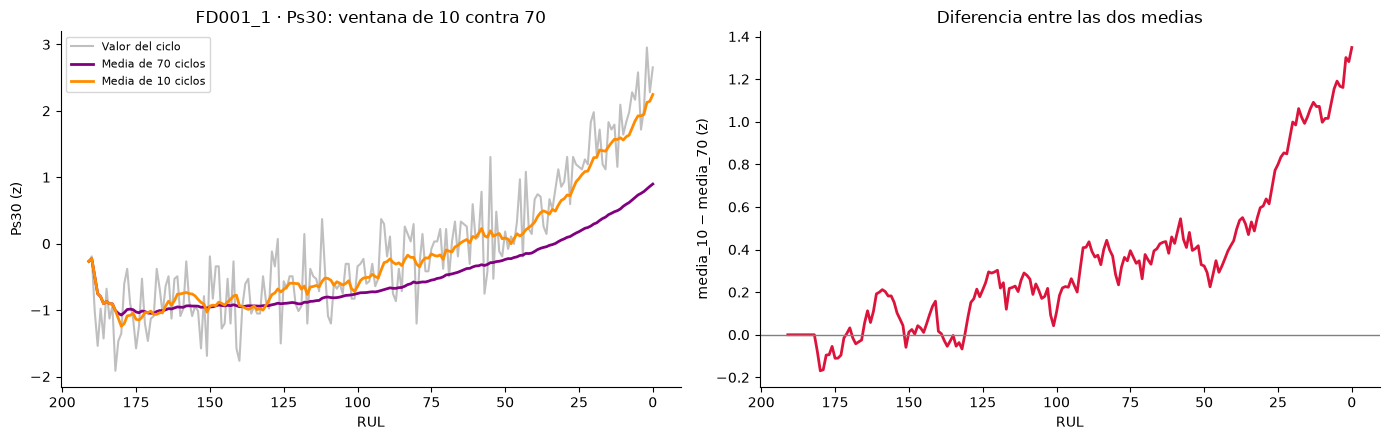

,Nivel real,Media de 70,Media de 10,Atraso de la de 70,Atraso de la de 10
RUL,,,,,
130,-0.56,-0.93,-0.85,0.37,0.29
75,-0.17,-0.55,-0.15,0.38,-0.01
50,-0.02,-0.24,0.09,0.22,-0.10
25,1.21,0.18,0.98,1.03,0.23
10,1.74,0.56,1.56,1.18,0.18
0,2.63,0.90,2.25,1.73,0.38


In [43]:
fd, motor_id, sensor = "FD001", "FD001_1", "Ps30"
d = datos[fd]
motor = d["grupos"] == motor_id
X_m = d["X_train"][motor]
y_m = d["y_train_real"][motor]

# Ventana de 10 ciclos para el mismo motor
tr = train_n[train_n["subset"] == fd]
X_10 = caracteristicas_ventana(tr, sensores_por_subset[fd], 10).loc[X_m.index]

media_70 = X_m[f"{sensor}_media"]
media_10 = X_10[f"{sensor}_media"]
nivel_real = X_m[f"{sensor}_ult"].rolling(5, center=True, min_periods=1).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(y_m, X_m[f"{sensor}_ult"], color="gray", alpha=0.5, label="Valor del ciclo")
ax1.plot(y_m, media_70, color="purple", lw=2, label="Media de 70 ciclos")
ax1.plot(y_m, media_10, color="darkorange", lw=2, label="Media de 10 ciclos")
ax1.set(xlabel="RUL", ylabel=f"{sensor} (z)", title=f"{motor_id} · {sensor}: ventana de 10 contra 70")
ax1.invert_xaxis()
ax1.legend(fontsize=8)

ax2.plot(y_m, media_10 - media_70, color="crimson", lw=2)
ax2.axhline(0, color="gray", lw=1)
ax2.set(xlabel="RUL", ylabel="media_10 − media_70 (z)", title="Diferencia entre las dos medias")
ax2.invert_xaxis()
plt.tight_layout()
plt.show()

puntos = [130, 75, 50, 25, 10, 0]
tabla_atraso = pd.DataFrame({
    "RUL": puntos,
    "Nivel real": [nivel_real[y_m == r].iloc[0] for r in puntos],
    "Media de 70": [media_70[y_m == r].iloc[0] for r in puntos],
    "Media de 10": [media_10[y_m == r].iloc[0] for r in puntos],
}).set_index("RUL")
tabla_atraso["Atraso de la de 70"] = tabla_atraso["Nivel real"] - tabla_atraso["Media de 70"]
tabla_atraso["Atraso de la de 10"] = tabla_atraso["Nivel real"] - tabla_atraso["Media de 10"]
tabla_atraso.round(2)

##### Interpretación:
| RUL | Nivel real | Media de 70 | Media de 10 | Atraso de la de 70 | Atraso de la de 10 |
|--:|--:|--:|--:|--:|--:|
| 130 | −0.56 | −0.93 | −0.85 | 0.37 | 0.29 |
| 75 | −0.17 | −0.55 | −0.15 | 0.38 | −0.01 |
| 50 | −0.02 | −0.24 | 0.09 | 0.22 | −0.10 |
| 25 | 1.21 | 0.18 | 0.98 | 1.03 | 0.23 |
| 10 | 1.74 | 0.56 | 1.56 | 1.18 | 0.18 |
| 0 | 2.63 | 0.90 | 2.25 | 1.73 | 0.38 |

- **Mientras el motor está sano, las dos medias casi coinciden** (atraso de 0.2 a 0.4 en las dos): no hay subida que atrasar.
- **Cerca de la falla, la media de 70 se queda muy atrás:** en el último ciclo vale 0.90 cuando el sensor ya está en 2.63, un atraso de 1.73. Todavía promedia unos 40 ciclos de antes de la subida.
- **La media de 10 sigue la subida casi sin retraso:** en el último ciclo vale 2.25, con un atraso de solo 0.38. Desde RUL 25 su atraso es de 0.2 a 0.4, contra 1.0 a 1.7 de la de 70.
- **La diferencia `media_10 − media_70` (derecha) es casi 0 mientras el motor está sano y crece hasta ≈ 1.35 al final.** Es una señal directa de que el desgaste se acelera, que ninguna de las dos ventanas da por sí sola.
- Por eso el modelo final usa sobre todo `media_10` (59 % de la importancia, sección 9.10) para saber cómo está el motor ahora, y `pend_70` (19 %) para la tendencia de fondo. La ventana de 70 no se descarta: sola es más estable que la de 10 (20.16 contra 25.19 en la sección 7), y su pendiente es la segunda característica más útil.

### 9.3 Ajuste de hiperparámetros con Optuna
En lugar de escribir configuraciones a mano, **Optuna** las busca automáticamente dentro de unos rangos:
1. Propone una configuración (por ejemplo, 700 árboles, `learning_rate` 0.02, 40 hojas…).
2. La evalúa con `validar` en los 4 subconjuntos, con las ventanas elegidas en 9.2, y obtiene el RMSE promedio.
3. Aprende de los intentos anteriores y propone la siguiente configuración cerca de las que dieron menos error.

El primer intento es la configuración base de 9.1 (`enqueue_trial`), así que el resultado de Optuna nunca puede quedar peor que la base. Solo se usa la validación; **test no participa**.

**Aviso:** cada intento es una validación completa. Con 30 intentos la celda puede tardar **1–2 horas**; para una prueba más rápida, baja `N_INTENTOS`.

**¿Qué hace el código?**
- `objetivo(trial)` es la función que Optuna intenta **minimizar**: arma una configuración con los valores que propone Optuna, la valida en los 4 subconjuntos y devuelve el RMSE promedio.
- `create_study(direction="minimize")` crea la búsqueda; `optimize(..., n_trials=N_INTENTOS)` la ejecuta.
- `PARAMS_OPTUNA` guarda la mejor configuración, y el historial de intentos se guarda en `optuna_lightgbm.csv`.
- La celda siguiente grafica el RMSE de cada intento (puntos) y el mejor encontrado hasta ese momento (línea roja).

In [44]:
import optuna
# Mostrar solo advertencias, no cada intento
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Número de configuraciones a probar
N_INTENTOS = 30

# Función que Optuna minimiza: RMSE promedio de validación en los 4 subconjuntos
def objetivo(trial):
    # Rangos de búsqueda de cada hiperparámetro
    parametros = {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 63),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 100, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "subsample_freq": 1,
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    }
    crear = receta_lgbm(parametros)
    errores = [validar(fd, crear, X=X_comb[ventanas_elegidas, fd])["RMSE"] for fd in Subsets]
    return float(np.mean(errores))

# Búsqueda con semilla fija; el primer intento es la configuración base
estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
estudio.enqueue_trial({k: v for k, v in PARAMS_LGBM.items() if k != "subsample_freq"})
estudio.optimize(objetivo, n_trials=N_INTENTOS, show_progress_bar=True)

# Mejor configuración y historial de intentos
PARAMS_OPTUNA = {**estudio.best_params, "subsample_freq": 1}
estudio.trials_dataframe().to_csv("CMAPSSData/CMAPSS-v2/optuna_lightgbm.csv", index=False)
print(f"Mejor RMSE promedio: {estudio.best_value:.2f} (intento {estudio.best_trial.number})")
PARAMS_OPTUNA

  0%|          | 0/30 [00:00<?, ?it/s]

Mejor RMSE promedio: 18.78 (intento 23)


{'n_estimators': 900,
 'learning_rate': 0.010480452430985308,
 'num_leaves': 41,
 'min_child_samples': 11,
 'subsample': 0.5039223876867823,
 'colsample_bytree': 0.951884727393112,
 'reg_lambda': 0.95266790458317,
 'subsample_freq': 1}

Qué es cada cosa:

| Código | Qué hace |
|:--|:--|
| `trial.suggest_int("num_leaves", 15, 63)` | Optuna elige un número entero de hojas entre 15 y 63. |
| `log=True` | Explora los valores en escala logarítmica: prueba tanto 0.01 como 0.1 con la misma frecuencia, en lugar de concentrarse en los grandes. |
| `TPESampler(seed=42)` | El método con el que Optuna aprende de los intentos anteriores; la semilla hace que la búsqueda se repita igual. |
| `enqueue_trial(...)` | Obliga a que el primer intento sea la configuración base. |
| `estudio.best_params` | La configuración con menor RMSE promedio. |

**Resultado esperado** (≈ 30 intentos): mejor RMSE ≈ **18.78** en el intento 23, contra 18.95 de la base (intento 0). Parámetros encontrados: 900 árboles, `learning_rate` ≈ 0.0105, 41 hojas, `min_child_samples` 11, `subsample` ≈ 0.50, `colsample_bytree` ≈ 0.95, `reg_lambda` ≈ 0.95.

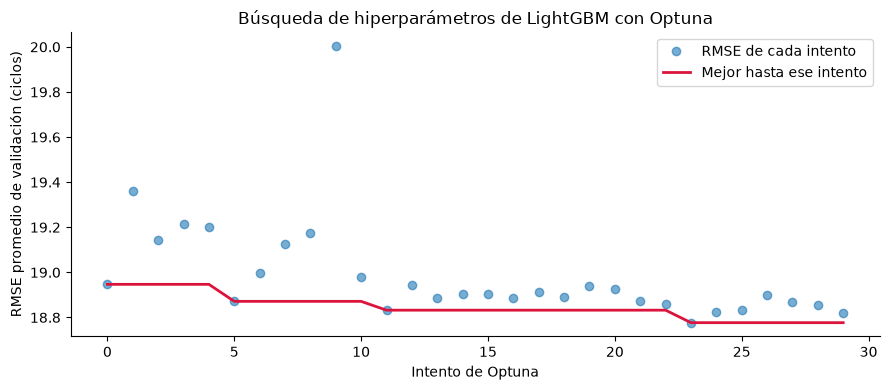

In [45]:
# RMSE de cada intento y el mejor encontrado hasta ese intento
historial = estudio.trials_dataframe()[["number", "value"]]
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(historial["number"], historial["value"], "o", alpha=0.6, label="RMSE de cada intento")
ax.plot(historial["number"], historial["value"].cummin(), color="crimson", lw=2, label="Mejor hasta ese intento")
ax.set(xlabel="Intento de Optuna", ylabel="RMSE promedio de validación (ciclos)",
       title="Búsqueda de hiperparámetros de LightGBM con Optuna")
ax.legend()
plt.tight_layout()
guardar_figura("Figura 11 - Búsqueda de hiperparámetros con Optuna")
plt.show()

##### Interpretación:
- La línea roja baja de 18.95 (configuración base) a **18.78**. La mejora llega de forma gradual: ≈ 18.87 hacia el intento 5, ≈ 18.83 en el 11 y 18.78 en el 23.
- Las mejores configuraciones combinan **muchos árboles con un `learning_rate` bajo** (900 árboles que corrigen ≈ 1 % del error cada uno) y **`subsample` ≈ 0.5**: cada árbol ve solo la mitad de los ciclos, lo que evita depender de unos pocos motores.
- La mejora total (0.17 ciclos) es pequeña: la configuración de *fleet-readiness* ya estaba cerca del óptimo.

### 9.4 ¿La mejora de Optuna es real?
Optuna eligió la mejor de 30 configuraciones con un solo reparto de motores en los pliegues (semilla 0). Con tantos intentos, alguna podría ganar solo por suerte en ese reparto. Para comprobarlo, se valida la configuración base y la de Optuna con **3 semillas**: si Optuna sigue ganando con repartos distintos, la mejora es real.

**¿Qué hace el código?**
- Valida la configuración base y la de Optuna con las ventanas elegidas, en los 4 subconjuntos y con 3 semillas (3 repartos distintos de los motores en los pliegues).
- `tabla_robustez` muestra el RMSE promedio de las 3 semillas por subconjunto, el promedio general y el **± ruido** (cuánto cambia el promedio de una semilla a otra).

In [46]:
# Configuración base contra la de Optuna, con 3 semillas
filas = []
for nombre, parametros in [("Base (fleet-readiness)", PARAMS_LGBM), ("Optuna", PARAMS_OPTUNA)]:
    for fd in Subsets:
        for semilla in [0, 1, 2]:
            resultado = validar(fd, receta_lgbm(parametros), X=X_comb[ventanas_elegidas, fd], semilla=semilla)
            resultado.update(config=nombre, subset=fd, semilla=semilla)
            filas.append(resultado)

# Promedio por subconjunto y ruido entre semillas
robustez = pd.DataFrame(filas)
tabla_robustez = robustez.groupby(["config", "subset"])["RMSE"].mean().unstack()
por_semilla = robustez.groupby(["config", "semilla"])["RMSE"].mean()
tabla_robustez["Promedio"] = por_semilla.groupby("config").mean()
tabla_robustez["± ruido"] = por_semilla.groupby("config").std()
tabla_robustez.round(2)

subset,FD001,FD002,FD003,FD004,Promedio,± ruido
config,,,,,,
Base (fleet-readiness),12.31,24.25,12.72,26.48,18.94,0.01
Optuna,12.17,24.05,12.56,26.34,18.78,0.01


##### Interpretación:
- **Optuna gana con las 3 semillas** (18.78 contra 18.94) y en los 4 subconjuntos. La diferencia (0.16 ciclos) es mucho mayor que el ruido entre semillas (0.01), así que la mejora es real y no suerte del reparto.
- Se usa la configuración de Optuna para el modelo final.

### 9.5 Modelo final y evaluación en test
Para cada subconjunto se entrena LightGBM con la configuración de Optuna, las ventanas 10 + 70 y **todos los motores de train** (con 1 de cada 5 ciclos, igual que en la validación). Después se predice el RUL de cada motor de test en su último ciclo observado y se compara con el RUL real de NASA. **Es la única vez que se usa test.**

Las ventanas de test se calculan con la misma función `ventanas_combinadas` y con los datos de test normalizados con las estadísticas de train (lección 4).

Se reportan:
- **RMSE contra el RUL real:** la métrica principal (protocolo oficial).
- **RMSE contra el RUL real recortado a 125:** solo para comparar con trabajos que califican así.
- **Score NASA (suma de multas)** y **% de predicciones tardías**.

**¿Qué hace el código?**
- `parametros_finales` toma la configuración de Optuna si ganó en 9.4; si no, la base.
- Para cada subconjunto:
  1. Calcula las ventanas combinadas de **test** con `ventanas_combinadas` y se queda con la fila del último ciclo de cada motor (`d["X_test"].index`).
  2. Entrena LightGBM con todos los motores de train y lo guarda en `modelos_finales`.
  3. Predice el RUL de cada motor de test (`np.clip` evita valores negativos) y calcula las métricas contra el RUL real.
  4. Guarda una tabla con la predicción de cada motor en `predicciones`.
- La tabla final muestra las 4 métricas por subconjunto y su promedio.

In [47]:
parametros_finales = PARAMS_OPTUNA if tabla_robustez.loc["Optuna", "Promedio"] < tabla_robustez.loc["Base (fleet-readiness)", "Promedio"] else PARAMS_LGBM # type: ignore
corta_larga = combinaciones[ventanas_elegidas] # type: ignore

# Entrenar con todos los motores de train y evaluar una sola vez en test
resultados_test = []
predicciones = []
modelos_finales = {}
for fd in Subsets:
    d = datos[fd]
    X_train = X_comb[ventanas_elegidas, fd]
    te = test_n[test_n["subset"] == fd]
    # Ventanas de test calculadas igual que en train, en el último ciclo de cada motor
    if corta_larga is None:
        X_test = d["X_test"]
    else:
        X_test = ventanas_combinadas(te, sensores_por_subset[fd], *corta_larga).loc[d["X_test"].index]

    # Entrenar con 1 de cada 5 ciclos, igual que en la validación
    entrenar = (X_train["cycle"] % 5 == 0).to_numpy()
    modelo = receta_lgbm(parametros_finales)().fit(X_train[entrenar], d["y_train"][entrenar])
    modelos_finales[fd] = modelo

    # RUL predicho, sin valores negativos
    y_pred = np.clip(modelo.predict(X_test), 0, None) # type: ignore # type: ignore
    y_real = d["y_test"].to_numpy()

    # Métricas contra el RUL real y contra el RUL recortado a 125
    resultados_test.append({
        "subset": fd,
        "RMSE (RUL real)": rmse(y_real, y_pred),
        "RMSE (RUL recortado a 125)": rmse(np.minimum(y_real, 125), y_pred),
        "Score NASA (suma)": score_nasa(y_real, y_pred),
        "% predicciones tarde": 100 * np.mean(y_pred > y_real),
    })
    # Predicción de cada motor
    predicciones.append(pd.DataFrame({
        "subset": fd,
        "engine_id": d["motores_test"].to_numpy(),
        "ciclos_observados": X_test["cycle"].to_numpy(),
        "RUL_predicho": y_pred.round(1),
        "RUL_real": y_real,
    }))

# Tabla final con el promedio
tabla_test = pd.DataFrame(resultados_test).set_index("subset")
tabla_test.loc["Promedio"] = tabla_test.mean()
tabla_test.round(2)

,RMSE (RUL real),RMSE (RUL recortado a 125),Score NASA (suma),% predicciones tarde
subset,,,,
FD001,13.10,12.28,290.07,54.00
FD002,21.55,10.36,3003.46,41.70
FD003,11.91,11.01,320.22,47.00
FD004,23.12,12.56,2797.40,46.37
Promedio,17.42,11.55,1602.78,47.27


##### Interpretación:
Resultado esperado: RMSE contra el RUL real de **13.10 / 21.55 / 11.91 / 23.12** (FD001–FD004), con un promedio de **17.42**.
- **En FD001 y FD003 el error de test es parecido al de validación** (13.10 contra 12.17; 11.91 contra 12.56): la validación por motor fue una buena guía.
- **FD002 y FD004 salen mejor en test que en validación** (21.55 contra 24.05; 23.12 contra 26.34): la validación califica todo el rango de RUL de test, y en el rango completo hay proporcionalmente más ciclos de motores muy sanos que entre los 259 y 248 motores de test.
- **Contra el RUL recortado a 125, FD002 y FD004 bajan a ≈ 10–13**: casi todo su error contra el RUL real viene de motores con más de 130 ciclos de vida, a los que el modelo, por el recorte, les predice ≈ 130.
- **≈ 47 % de las predicciones son tardías**: el modelo no tiene una tendencia fuerte a predecir de más ni de menos.
- El score NASA de FD002 y FD004 (≈ 3 000) es mayor porque tienen ≈ 2.5 veces más motores y la multa se suma.

### 9.6 Comparación con otros trabajos

Los notebooks de Kaggle son la línea base externa de la propuesta (P1); *rul_codes_open* [[3]](#ref3) es un repositorio de GitHub que se incluye porque reporta los 4 subconjuntos con el mismo protocolo.

**Contra el RUL real (protocolo oficial):**

| Modelo | FD001 | FD002 | FD003 | FD004 | Promedio |
|:--|--:|--:|--:|--:|--:|
| Random Forest, 1 ciclo (Kaggle *predictive-maintenance* [[2]](#ref2)) | 17.96 | — | — | — | — |
| LSTM, 30 ciclos (Kaggle *rul-prediction-using-lstm* [[4]](#ref4)) | 15.30 | — | — | — | — |
| Random Forest, 1 ciclo (*rul_codes_open*) | 17.76 | 29.16 | 20.59 | 30.15 | 24.42 |
| XGBoost, 1 ciclo (*rul_codes_open*) | 18.44 | 29.35 | 21.29 | 29.89 | 24.74 |
| LSTM, 30 ciclos (*rul_codes_open*) | 15.13 | 27.70 | 14.03 | 28.37 | 21.31 |
| GRU + atención, 30 ciclos (*rul_codes_open*) | 14.21 | 27.99 | 14.64 | 26.78 | 20.91 |
| Chronos-2 + LightGBM (Kaggle *fleet-readiness* [[5]](#ref5)) | **11.79** | 23.38 | **11.13** | 23.86 | 17.54 |
| **LightGBM, ventanas 10 + 70, Optuna** | 13.10 | **21.55** | 11.91 | **23.12** | **17.42** |

**Contra el RUL real recortado a 125:**

| Modelo | FD001 | FD002 | FD003 | FD004 | Promedio |
|:--|--:|--:|--:|--:|--:|
| LightGBM (Kaggle *fleet-readiness* [[5]](#ref5)) | 11.46 | 11.03 | 9.96 | 11.59 | 11.01 |
| Chronos-2 + LightGBM (Kaggle *fleet-readiness* [[5]](#ref5)) | **10.60** | 10.86 | **9.46** | **11.44** | **10.59** |
| **LightGBM, ventanas 10 + 70, Optuna** | 12.28 | **10.36** | 11.01 | 12.56 | 11.55 |

##### Interpretación:
- **Contra el RUL real, este proyecto tiene el menor promedio** (17.42 contra 17.54 de *fleet-readiness*). Es mejor en FD002 (−1.8 ciclos) y FD004 (−0.7), y peor en FD001 (+1.3) y FD003 (+0.8). Las diferencias están dentro de la incertidumbre que reporta *fleet-readiness* (≈ ±1–2 ciclos por subconjunto), así que en la práctica ambos trabajos quedan al mismo nivel.
- **Supera a los dos notebooks de Kaggle que solo reportan FD001** (17.96 y 15.30 contra 13.10).
- **Supera claramente a los modelos sin ventanas** (≈ 24.5) y a las redes LSTM y GRU de *rul_codes_open* (≈ 21), lo que confirma el aporte de las ventanas y de la normalización por condición.
- **Contra el RUL recortado a 125, *fleet-readiness* es ≈ 1 ciclo mejor** (10.59 contra 11.55), aunque este proyecto es el mejor en FD002 (10.36). Esa calificación favorece a los modelos entrenados con recorte a 125, como el suyo, y no cuenta el error en los motores muy sanos, donde el recorte a 130 de este proyecto da ventaja.
- Con Chronos-2 (9.11) el promedio baja a 17.22. La respuesta formal a P1, con su criterio, está en 10.1.

### 9.7 RUL predicho contra RUL real
Cada punto es un motor de test. Si la predicción fuera perfecta, todos los puntos caerían sobre la diagonal. Los puntos arriba de la diagonal son predicciones tardías (más vida de la real); los de abajo, tempranas.

**¿Qué hace el código?** Dibuja una gráfica por subconjunto con un punto por motor de test (eje X: RUL real; eje Y: RUL predicho), la diagonal de predicción perfecta (gris) y la línea del recorte a 130 (roja). En el título aparece el RMSE de ese subconjunto.

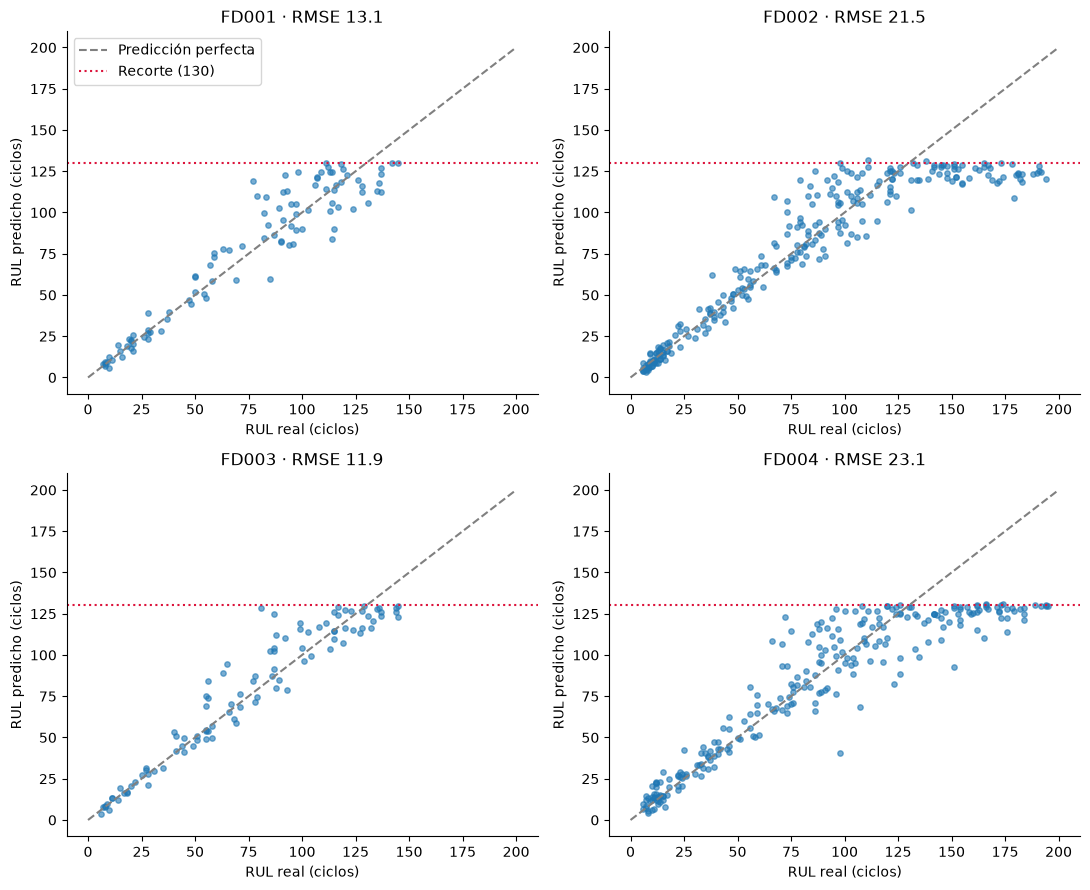

In [48]:
# Un panel por subconjunto: RUL real contra predicho de cada motor de test
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for ax, df_p in zip(axes.ravel(), predicciones):
    fd = df_p["subset"].iloc[0]
    ax.scatter(df_p["RUL_real"], df_p["RUL_predicho"], s=15, alpha=0.6)
    # Diagonal de predicción perfecta y línea del recorte
    ax.plot([0, 200], [0, 200], color="gray", ls="--", label="Predicción perfecta")
    ax.axhline(RUL_TOPE, color="crimson", ls=":", label=f"Recorte ({RUL_TOPE})")
    ax.set(title=f"{fd} · RMSE {tabla_test.loc[fd, 'RMSE (RUL real)']:.1f}",
           xlabel="RUL real (ciclos)", ylabel="RUL predicho (ciclos)")
axes[0, 0].legend()
plt.tight_layout()
guardar_figura("Figura 12 - RUL predicho contra RUL real en test")
plt.show()

##### Interpretación:
- **Los motores cercanos a la falla (RUL real < 50) quedan pegados a la diagonal:** ahí el modelo es más preciso, que es donde más importa para el mantenimiento.
- **Los motores muy sanos (RUL real > 130) forman una línea horizontal en ≈ 130:** el modelo nunca predice más del recorte. En FD002 y FD004 se nota más porque tienen más motores con RUL real de hasta 195.
- **Entre 60 y 120 ciclos hay más dispersión:** es la zona donde el desgaste apenas empieza y es más difícil saber cuánto falta.

### 9.8 Error por zona de RUL
El RMSE total mezcla motores en situaciones muy distintas. Se separa el error de test en tres zonas: **cerca de la falla** (RUL < 50), **desgaste** (50–130) y **muy sano** (> 130). El **sesgo** es el error promedio: positivo si el modelo tiende a predecir de más (tarde), negativo si tiende a predecir de menos (temprano).

**¿Qué hace el código?**
- Junta las predicciones de los 4 subconjuntos en `predicciones_test` y calcula el `error` de cada motor (predicho − real).
- `pd.cut` asigna a cada motor su zona según su RUL real: < 50, 50–130 o > 130.
- `groupby(["zona", "subset"]).agg(...)` calcula por zona y subconjunto el RMSE, cuántos motores hay y el sesgo (error promedio).
- Se muestran tres tablas: RMSE, número de motores y sesgo.

In [49]:
# Predicciones de los 4 subconjuntos y error de cada motor (predicho − real)
predicciones_test = pd.concat(predicciones, ignore_index=True)
predicciones_test["error"] = predicciones_test["RUL_predicho"] - predicciones_test["RUL_real"]
# Zona de cada motor según su RUL real
predicciones_test["zona"] = pd.cut(predicciones_test["RUL_real"], bins=[-1, 49, 130, 1000],
                                   labels=["RUL < 50", "RUL 50–130", "RUL > 130"])

# RMSE, número de motores y sesgo por zona y subconjunto
error_zona = predicciones_test.groupby(["zona", "subset"], observed=True).agg(
    RMSE=("error", lambda e: np.sqrt(np.mean(e ** 2))),
    motores=("error", "size"),
    sesgo=("error", "mean"),
)
print("RMSE por zona (ciclos)")
display(error_zona["RMSE"].unstack().round(1))
print("Motores de test por zona")
display(error_zona["motores"].unstack())
print("Sesgo por zona (ciclos; + = tarde, − = temprano)")
display(error_zona["sesgo"].unstack().round(1))

RMSE por zona (ciclos)


subset,FD001,FD002,FD003,FD004
zona,,,,
RUL < 50,3.5,4.9,4.1,5.8
RUL 50–130,15.1,14.3,13.9,17.3
RUL > 130,18.4,41.4,14.0,40.2


Motores de test por zona


subset,FD001,FD002,FD003,FD004
zona,,,,
RUL < 50,30,87,29,79
RUL 50–130,62,117,60,109
RUL > 130,8,55,11,60


Sesgo por zona (ciclos; + = tarde, − = temprano)


subset,FD001,FD002,FD003,FD004
zona,,,,
RUL < 50,0.2,0.4,0.8,2.4
RUL 50–130,3.9,4.8,5.0,3.3
RUL > 130,-17.5,-36.6,-13.2,-37.0


##### Interpretación:
- **Cerca de la falla el error es de solo 3.5–5.8 ciclos** y el sesgo es casi cero (+0.2 a +2.4): el modelo es preciso justo donde se decide sacar un motor de servicio, y no tiende a dar avisos tardíos.
- **En la zona de desgaste el error sube a ≈ 14–17 ciclos**: los sensores apenas empiezan a moverse y es más difícil saber cuánto falta.
- **En los motores muy sanos el error es el más grande** (≈ 40 en FD002 y FD004) y el sesgo es negativo (−13 a −37): por el recorte a 130, a esos motores siempre se les predice de menos, un error del lado seguro.
- **FD002 y FD004 tienen 55 y 60 motores muy sanos en test**, contra 8 y 11 en FD001 y FD003. Por eso su RMSE total es más alto aunque cerca de la falla el modelo funciona igual de bien en los cuatro.

### 9.9 El RUL predicho a lo largo de la vida de un motor
En test solo se califica el último ciclo de cada motor, pero el modelo puede predecir el RUL en **cualquier** ciclo. Aquí se le pide una predicción en cada ciclo de un motor de test, como si se revisara después de cada vuelo, y se compara con el RUL real en ese momento.

Se eligió, en cada subconjunto, uno de los motores de test con la historia más larga (300–475 ciclos) y que termina cerca de la falla, para ver todo el recorrido de sano a gastado.

**¿Qué hace el código?**
- Para cada motor calcula las ventanas (10 + 70) en **todos** sus ciclos de test, no solo en el último, y predice con su modelo final de 9.5 (`modelos_finales`).
- `rul_real` reconstruye el RUL real en cada ciclo: el RUL del último ciclo (`RUL_final`) más los ciclos que faltaban para llegar a él.
- Dibuja el RUL real (negro), el real recortado a 130 (gris, lo que el modelo aprendió a predecir), el predicho (morado) y el último ciclo, el que se califica en test (punto rojo).

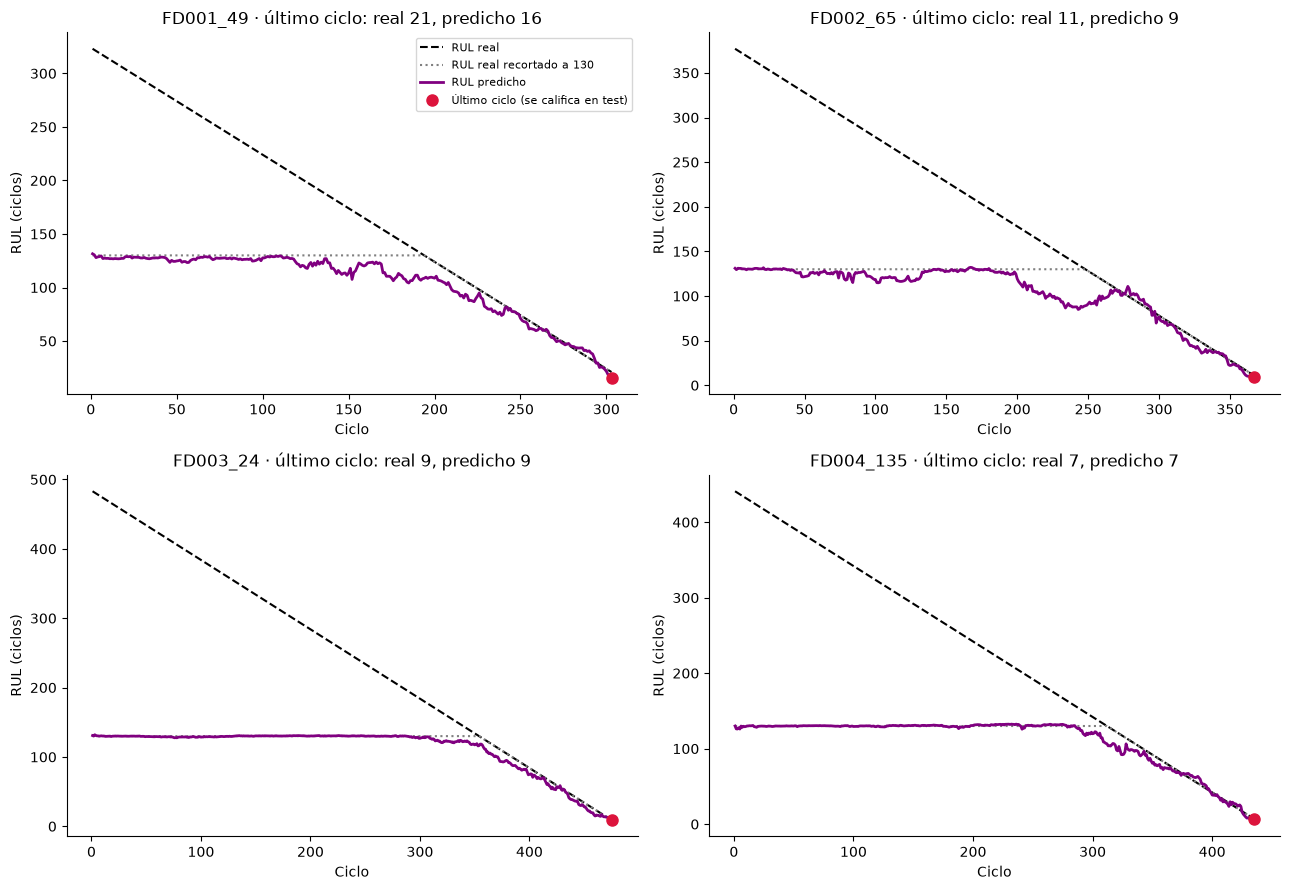

In [50]:
# Motores de test con historia larga y que terminan cerca de la falla
motores_ejemplo = ["FD001_49", "FD002_65", "FD003_24", "FD004_135"]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, motor_id in zip(axes.ravel(), motores_ejemplo):
    fd = motor_id.split("_")[0]
    # Ventanas en todos los ciclos del motor, no solo en el último
    te_motor = test_n[test_n["engine_id"] == motor_id]
    if corta_larga is None:
        X_motor = caracteristicas_ventana(te_motor, sensores_por_subset[fd])
    else:
        X_motor = ventanas_combinadas(te_motor, sensores_por_subset[fd], *corta_larga)
    X_motor = X_motor[modelos_finales[fd].feature_name_]

    # RUL predicho en cada ciclo y RUL real reconstruido
    rul_predicho = np.clip(modelos_finales[fd].predict(X_motor), 0, None)
    rul_real = te_motor["RUL_final"].to_numpy() + te_motor["cycle"].max() - te_motor["cycle"].to_numpy()

    # Real, real recortado, predicho y el último ciclo (el que se califica)
    ax.plot(te_motor["cycle"], rul_real, color="black", ls="--", label="RUL real")
    ax.plot(te_motor["cycle"], np.minimum(rul_real, RUL_TOPE), color="gray", ls=":",
            label=f"RUL real recortado a {RUL_TOPE}")
    ax.plot(te_motor["cycle"], rul_predicho, color="purple", lw=2, label="RUL predicho")
    ax.plot(te_motor["cycle"].iloc[-1], rul_predicho[-1], "o", color="crimson", ms=8,
            label="Último ciclo (se califica en test)")
    ax.set(title=f"{motor_id} · último ciclo: real {rul_real[-1]}, predicho {rul_predicho[-1]:.0f}",
           xlabel="Ciclo", ylabel="RUL (ciclos)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
guardar_figura("Figura 13 - RUL predicho a lo largo de la vida de un motor")
plt.show()

##### Interpretación:
- **Mientras el motor está sano, el modelo predice ≈ 130 ciclos** (la meseta morada), aunque el RUL real sea de ≈ 320–480. Es el efecto del recorte: el modelo aprendió que arriba de 130 los sensores casi no cambian, así que no intenta distinguir un motor con 200 ciclos de vida de uno con 400.
- **Cuando el RUL real baja de ≈ 130, la predicción empieza a bajar y sigue la diagonal real.** En esa parte final se equivoca ≈ 9–12 ciclos (RMSE), con oscilaciones de un vuelo a otro.
- **En el último ciclo, que es el que se califica, las predicciones quedan muy cerca:** 16 contra 21 (FD001_49), 9 contra 11 (FD002_65), 9 contra 9 (FD003_24) y 7 contra 7 (FD004_135). Los cuatro son errores tempranos, el lado seguro.
- En FD001_49 y FD002_65 la predicción empieza a bajar antes de que el RUL real llegue a 130: el modelo detecta los primeros signos de desgaste y da un aviso temprano.
- Estos motores están cerca de la falla en su último ciclo, que es la zona donde el modelo es más preciso (9.8). En los motores de test que terminan muy sanos, el último ciclo cae en la meseta y el error es mayor.

### 9.10 ¿Qué aprendió el modelo? Importancia de las características
LightGBM decide con preguntas del tipo "¿`Ps30_media_10` > 0.8?". La **ganancia** de una característica es cuánto reduce el error del modelo en todas las divisiones donde se usa. Entre más ganancia, más depende el modelo de ella para estimar el RUL.

**¿Qué hace el código?**
- Para cada modelo final de 9.5 obtiene la ganancia de cada característica (`importance_type="gain"`) y la convierte en % del total de ese subconjunto.
- `importancia` junta los 4 subconjuntos y calcula el promedio (si una característica no existe en un subconjunto, cuenta como 0).
- Izquierda: la importancia sumada por **sensor** (las 12 estadísticas de cada sensor: 6 de la ventana de 10 y 6 de la de 70).
- Derecha: las 15 **características** individuales más importantes.
- La tabla `por_estadistica` suma la importancia por tipo de estadística y ventana (`media_10`, `pend_70`…).

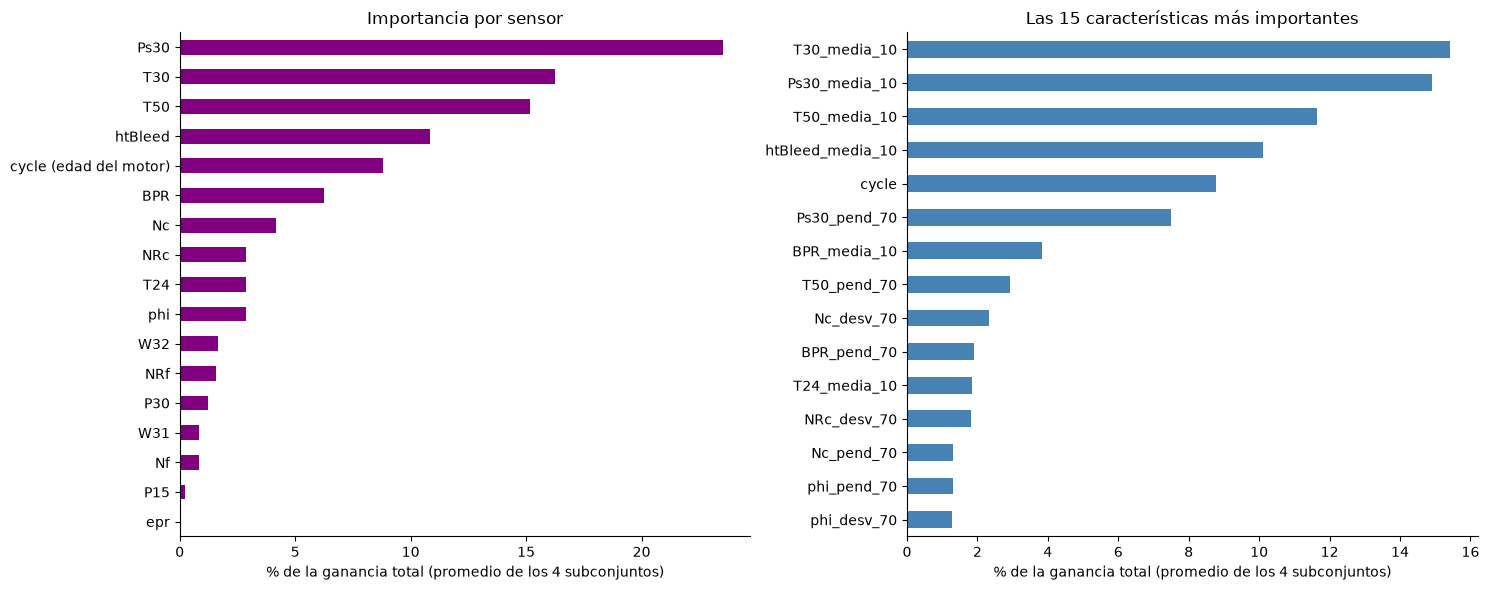

Importancia por estadística y ventana (%)


,Promedio
media_10,59.0
pend_70,18.9
cycle,8.8
desv_70,7.0
max_70,1.8
max_10,1.3
min_70,1.3
min_10,0.6
ult_10,0.4
media_70,0.4


Las 10 características más importantes en cada subconjunto (%)


,FD001,FD002,FD003,FD004,Promedio
T30_media_10,2.5,0.6,32.2,26.4,15.4
Ps30_media_10,5.7,30.5,9.1,14.4,14.9
T50_media_10,24.9,20.5,0.4,0.7,11.6
htBleed_media_10,3.5,5.7,17.7,13.4,10.1
cycle,11.2,11.3,7.1,5.6,8.8
Ps30_pend_70,4.2,10.3,6.9,8.6,7.5
BPR_media_10,13.2,2.0,0.0,0.1,3.8
T50_pend_70,3.3,3.2,3.5,1.7,2.9
Nc_desv_70,1.4,0.2,0.9,6.8,2.3
BPR_pend_70,2.1,4.3,0.4,0.8,1.9


In [51]:
# Ganancia de cada característica en los modelos finales, en % del total de su subconjunto
filas = []
for fd in Subsets:
    modelo = modelos_finales[fd]
    ganancia = modelo.booster_.feature_importance(importance_type="gain")
    filas.append(pd.Series(100 * ganancia / ganancia.sum(), index=modelo.feature_name_, name=fd))

# Promedio de los 4 subconjuntos
importancia = pd.concat(filas, axis=1).fillna(0)
importancia["Promedio"] = importancia.mean(axis=1)

# Sensor y estadística de cada columna (por ejemplo Ps30 y media_10)
partes = importancia.index.to_series().str.split("_")
sensor = partes.str[0].replace({"cycle": "cycle (edad del motor)"})
estadistica = partes.str[1:].str.join("_").replace({"": "cycle"})

# Importancia sumada por sensor y por estadística, y las 15 columnas más importantes
por_sensor = importancia.groupby(sensor)["Promedio"].sum().sort_values()
por_estadistica = importancia.groupby(estadistica)["Promedio"].sum().sort_values(ascending=False)
top = importancia["Promedio"].sort_values().tail(15)

# Izquierda: por sensor; derecha: 15 características
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
por_sensor.plot.barh(ax=ax1, color="purple")
ax1.set(xlabel="% de la ganancia total (promedio de los 4 subconjuntos)", ylabel="", title="Importancia por sensor")
top.plot.barh(ax=ax2, color="steelblue")
ax2.set(xlabel="% de la ganancia total (promedio de los 4 subconjuntos)", ylabel="",
        title="Las 15 características más importantes")
plt.tight_layout()
guardar_figura("Figura 14 - Importancia de las características por ganancia")
plt.show()

print("Importancia por estadística y ventana (%)")
display(por_estadistica.round(1).to_frame("Promedio"))
print("Las 10 características más importantes en cada subconjunto (%)")
display(importancia.sort_values("Promedio", ascending=False).head(10).round(1))

##### Interpretación:
- **Ps30 es el sensor más importante** (23.5 % de la ganancia), seguido de T30 (16.2 %), T50 (15.2 %) y htBleed (10.9 %). Son la presión de la cámara de combustión y las temperaturas, los sensores que en 4.5 y 4.6 b) tenían la subida más clara al acercarse la falla. Entre estos cuatro reúnen ≈ 66 % de la ganancia.
- **P15 casi no se usa** (0.2 %). Confirma lo visto en 4.1 b): pasa el criterio de los sensores, pero no aporta información.
- **La estadística más útil es la media de los últimos 10 ciclos** (59 % de la ganancia), seguida de la pendiente de los últimos 70 (18.9 %). El modelo combina el **estado actual** del motor (media reciente) con su **tendencia** (pendiente larga), que es justo lo que buscaba la combinación 10 + 70 de 9.2.
- **El valor del último ciclo (`_ult`) casi no se usa** (0.4 %): un solo ciclo es demasiado ruidoso, y el modelo prefiere los promedios. Es la mejor evidencia del aporte de las ventanas (sección 5).
- **`cycle` (los ciclos que lleva el motor) aporta 8.8 %:** un motor con muchos vuelos tiende a estar más gastado.
- **La importancia de un sensor cambia entre subconjuntos:** `T50_media_10` es la segunda característica en FD001 (24.9 %) pero casi no se usa en FD003 (0.4 %), donde `T30_media_10` toma su lugar (32.2 %). Las temperaturas suben juntas, así que el modelo usa la que le sirva y la otra queda como respaldo. Por eso la importancia de una característica individual no se debe sobreinterpretar; la suma por sensor es más estable.

### 9.11 ¿Ayuda un modelo preentrenado? LightGBM + Chronos-2
**Chronos-2** (Amazon, 2025) es un modelo de series de tiempo **preentrenado** con millones de series de muchos dominios (ventas, clima, energía, tráfico…). *Fleet-readiness* lo usa **congelado**, sin reentrenarlo, como un "lector" de la historia reciente de los sensores: le da los últimos 64 ciclos de cada sensor y Chronos-2 devuelve un resumen numérico (*embedding*) de esa historia. Ese resumen se agrega como columnas extra a LightGBM.

La pregunta es si este resumen aprendido aporta algo que las ventanas 10 + 70 de este proyecto no capturen ya.

Receta (la misma de *fleet-readiness*):
1. Para cada punto se toman los últimos 64 ciclos de los sensores normalizados (menos si el motor lleva menos ciclos).
2. Chronos-2 small (28 millones de parámetros) devuelve ≈ 1 055 valores por punto: dos vectores de 512 que resumen la serie (promediados entre sensores), más la media y la desviación de cada sensor en la ventana.
3. Dentro de cada pliegue, esos ≈ 1 055 valores se comprimen a **32 componentes con PCA**, y se agregan a las columnas de las ventanas 10 + 70.
4. LightGBM, con los parámetros de Optuna, se entrena con todo junto.

**Aviso:**
- Requiere `torch` y `chronos-forecasting` (`pip install chronos-forecasting`). Con GPU, los embeddings tardan ≈ 3 minutos; en CPU, bastante más. Se guardan en `CMAPSSData/CMAPSS-v2/chronos/` y no se recalculan.
- Para no calcular embeddings de las ≈ 160 000 filas de train, solo se calculan en **1 de cada 5 ciclos**, los mismos puntos con los que ya se entrena. La validación de esta sección evalúa en esos puntos, así que su RMSE base (≈ 18.73) es un poco distinto al de 9.4 (18.78). Los dos modelos se comparan en exactamente los mismos puntos.

**¿Qué hace el código?**
- `ventanas_crudas` toma, para cada punto pedido, los últimos 64 ciclos de cada sensor del motor (una matriz sensores × ciclos).
- `embeddings_chronos` pasa esas ventanas por Chronos-2 en grupos de 1 024 y arma los ≈ 1 055 valores de cada punto.
- Para cada subconjunto calcula los embeddings de los puntos de train (1 de cada 5 ciclos) y del último ciclo de cada motor de test, y los guarda en disco. Si el archivo ya existe, solo lo carga.

In [ ]:
import torch
from chronos import Chronos2Pipeline

# Ciclos de historia que ve Chronos-2, GPU si está disponible y carpeta de la caché
CONTEXTO = 64
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
carpeta_chronos = carpeta / "CMAPSS-v2" / "chronos"
carpeta_chronos.mkdir(exist_ok=True)
chronos = None

def ventanas_crudas(df, sensores, filas):
    """Los últimos CONTEXTO ciclos de cada sensor (sensores × ciclos) que terminan en cada fila pedida."""
    df = df.sort_values(["engine_id", "cycle"])
    valores = df[sensores].to_numpy(np.float32)
    posicion = df.groupby("engine_id").cumcount().to_numpy()
    fin = pd.Series(np.arange(len(df)), index=df.index).loc[filas].to_numpy()
    inicio = fin - np.minimum(posicion[fin], CONTEXTO - 1)
    return [valores[i:f + 1].T for i, f in zip(inicio, fin)]

def embeddings_chronos(ventanas, n_sensores, trozo=1024):
    """Resume cada ventana con Chronos-2: 2 tokens (promediados entre sensores) + media y desviación de cada sensor."""
    filas = []
    for i in range(0, len(ventanas), trozo):
        emb, loc_scale = chronos.embed(ventanas[i:i + trozo], batch_size=n_sensores * 64) # type: ignore
        for e, (media, desv) in zip(emb, loc_scale):
            e = e.float().cpu()
            filas.append(np.concatenate([e[:, -2].mean(0).numpy(), e[:, -1].mean(0).numpy(),
                                         media.flatten().float().cpu().numpy(), desv.flatten().float().cpu().numpy()]))
    return np.vstack(filas).astype(np.float32)

print("Dispositivo:", dispositivo)
# Embeddings de los puntos de train (1 de cada 5 ciclos) y del último ciclo de test, guardados en disco
emb_chronos = {}
for fd in Subsets:
    X = X_comb[ventanas_elegidas, fd]
    puntos = X.index[(X["cycle"] % 5 == 0).to_numpy()]
    archivo = carpeta_chronos / f"chronos-2-small_{fd}.npz"
    # Si ya se calcularon, solo se cargan
    if archivo.exists():
        guardado = np.load(archivo)
        emb_chronos[fd] = {"train": guardado["train"], "test": guardado["test"]}
    else:
        if chronos is None:
            chronos = Chronos2Pipeline.from_pretrained("autogluon/chronos-2-small", device_map=dispositivo)
        tr = train_n[train_n["subset"] == fd]
        te = test_n[test_n["subset"] == fd]
        s = sensores_por_subset[fd]
        emb_chronos[fd] = {"train": embeddings_chronos(ventanas_crudas(tr, s, puntos), len(s)),
                           "test": embeddings_chronos(ventanas_crudas(te, s, datos[fd]["X_test"].index), len(s))}
        np.savez_compressed(archivo, **emb_chronos[fd])
    emb_chronos[fd]["puntos"] = puntos
    print(f"{fd}: {emb_chronos[fd]['train'].shape[0]} puntos de train y {emb_chronos[fd]['test'].shape[0]} motores de test, "
          f"{emb_chronos[fd]['train'].shape[1]} valores de Chronos-2 por punto")

Dispositivo: cuda
FD001: 4086 puntos de train y 100 motores de test, 1054 valores de Chronos-2 por punto
FD002: 10638 puntos de train y 259 motores de test, 1054 valores de Chronos-2 por punto
FD003: 4906 puntos de train y 100 motores de test, 1056 valores de Chronos-2 por punto
FD004: 12146 puntos de train y 248 motores de test, 1056 valores de Chronos-2 por punto


##### Interpretación:
Cada punto queda resumido con 1 054 valores en FD001 y FD002 (15 sensores) y 1 056 en FD003 y FD004 (16 sensores): 2 × 512 de los tokens de Chronos-2 más la media y la desviación de cada sensor. Son ≈ 32 000 puntos de train en total (4 086 / 10 638 / 4 906 / 12 146) y los 707 motores de test. Es la primera ejecución que dice que el modelo se cargó en la GPU; el aviso de *symlinks* de Hugging Face en Windows es inofensivo.

#### 9.11 b) Validación: ¿Chronos-2 mejora a LightGBM?
**¿Qué hace el código?**
- `receta_chronos(n_tabla)` crea un modelo en dos pasos: deja pasar tal cual las columnas de las ventanas y comprime las de Chronos-2 a 32 componentes con PCA (ajustado **solo con los motores de entrenamiento de cada pliegue**), y luego entrena LightGBM con todo junto.
- `matrices(fd)` arma, en los puntos con embeddings, las columnas **sin** Chronos-2 (solo ventanas) y **con** Chronos-2 (ventanas + embeddings).
- Se validan los dos modelos con los mismos pliegues por motor y 3 semillas, evaluando contra el RUL real en el rango de test, igual que `validar`.
- La tabla muestra el RMSE promedio por subconjunto, el promedio general y el ± ruido entre semillas.

In [53]:
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def receta_chronos(n_tabla):
    """LightGBM que recibe las columnas de las ventanas tal cual y los embeddings de Chronos-2 comprimidos a 32 con PCA."""
    def crear():
        columnas = ColumnTransformer([
            ("ventanas", "passthrough", slice(0, n_tabla)),
            ("chronos", make_pipeline(StandardScaler(), PCA(32, random_state=42)), slice(n_tabla, None)),
        ])
        return make_pipeline(columnas, receta_lgbm(parametros_finales)())
    return crear

def matrices(fd):
    """Columnas de las ventanas, sin y con Chronos-2, en los puntos de train donde hay embeddings."""
    X = X_comb[ventanas_elegidas, fd].loc[emb_chronos[fd]["puntos"]]
    sin = X.to_numpy(np.float64)
    con = np.hstack([sin, emb_chronos[fd]["train"].astype(np.float64)])
    return X, sin, con

# Validar los dos modelos con los mismos pliegues y 3 semillas
filas = []
for fd in Subsets:
    d = datos[fd]
    X, X_sin, X_con = matrices(fd)
    y = d["y_train"].loc[X.index].to_numpy()
    rul = d["y_train_real"].loc[X.index].to_numpy()
    grupos = d["grupos"].loc[X.index].to_numpy()
    minimo, maximo = rango_test.loc[fd] # type: ignore
    evaluar = (rul >= minimo) & (rul <= maximo)
    for semilla in [0, 1, 2]:
        pred = {"LightGBM": np.full(len(y), np.nan), "LightGBM + Chronos-2": np.full(len(y), np.nan)}
        for i_ent, i_val in GroupKFold(n_splits=5, shuffle=True, random_state=semilla).split(X_sin, y, grupos): # type: ignore
            i_val = i_val[evaluar[i_val]]
            pred["LightGBM"][i_val] = receta_lgbm(parametros_finales)().fit(X_sin[i_ent], y[i_ent]).predict(X_sin[i_val])
            pred["LightGBM + Chronos-2"][i_val] = receta_chronos(X_sin.shape[1])().fit(X_con[i_ent], y[i_ent]).predict(X_con[i_val])
        for nombre, p in pred.items():
            filas.append({"modelo": nombre, "subset": fd, "semilla": semilla,
                          "RMSE": rmse(rul[evaluar], np.clip(p[evaluar], 0, None))})
    print(f"{fd} listo", flush=True)

# Promedio por subconjunto y ruido entre semillas
val_chronos = pd.DataFrame(filas)
tabla_val_chronos = val_chronos.groupby(["modelo", "subset"])["RMSE"].mean().unstack()
por_semilla = val_chronos.groupby(["modelo", "semilla"])["RMSE"].mean()
tabla_val_chronos["Promedio"] = por_semilla.groupby("modelo").mean()
tabla_val_chronos["± ruido"] = por_semilla.groupby("modelo").std()
tabla_val_chronos.round(2)

FD001 listo
FD002 listo
FD003 listo
FD004 listo


subset,FD001,FD002,FD003,FD004,Promedio,± ruido
modelo,,,,,,
LightGBM,12.18,23.91,12.53,26.30,18.73,0.01
LightGBM + Chronos-2,12.12,23.86,12.17,26.02,18.54,0.08


##### Interpretación:
- **Chronos-2 baja el error de validación de 18.73 a 18.54** (−0.19 ciclos), más que el ruido entre semillas. La mejora es real, pero pequeña.
- **La mejora no es igual en todos los subconjuntos:** es más clara en FD003 (12.53 → 12.17) y FD004 (26.30 → 26.02), donde mejora con las 3 semillas. En FD001 y FD002 es casi nula (−0.06 y −0.05) y, en FD001, con una de las semillas incluso empeora.
- **El ruido sube de 0.01 a 0.08:** con Chronos-2 el resultado depende más de qué motores caen en cada pliegue. Las 32 componentes de PCA cambian según los motores de entrenamiento.

#### 9.11 c) Test y comparación con *fleet-readiness*
Como en 9.5, se entrenan los dos modelos con todos los motores de train y se evalúan **una sola vez** en el último ciclo de los 707 motores de test. Se comparan con los resultados que reporta *fleet-readiness* contra el RUL real y contra el RUL recortado a 125. *Fleet-readiness* no reporta su LightGBM sin Chronos-2 contra el RUL real, así que esa fila solo aparece en la segunda tabla.

**¿Qué hace el código?**
- Para cada subconjunto entrena LightGBM sin y con Chronos-2 y predice el RUL de cada motor de test.
- `referencias` guarda los resultados de *fleet-readiness*. Las dos tablas los ponen junto a los de este proyecto, con su promedio.
- La última tabla separa el error por zona de RUL, como en 9.8.

In [54]:
# Entrenar con todos los motores de train y evaluar en test, sin y con Chronos-2
filas, pred_chronos = [], []
for fd in Subsets:
    d = datos[fd]
    X, X_sin, X_con = matrices(fd)
    y = d["y_train"].loc[X.index].to_numpy()
    te = test_n[test_n["subset"] == fd]
    if corta_larga is None:
        X_test = d["X_test"]
    else:
        X_test = ventanas_combinadas(te, sensores_por_subset[fd], *corta_larga).loc[d["X_test"].index]
    T_sin = X_test[X.columns].to_numpy(np.float64)
    T_con = np.hstack([T_sin, emb_chronos[fd]["test"].astype(np.float64)])
    y_real = d["y_test"].to_numpy()
    for nombre, modelo, A, B in [("LightGBM", receta_lgbm(parametros_finales)(), X_sin, T_sin),
                                 ("LightGBM + Chronos-2", receta_chronos(X_sin.shape[1])(), X_con, T_con)]:
        y_pred = np.clip(modelo.fit(A, y).predict(B), 0, None)
        filas.append({"modelo": nombre, "subset": fd,
                      "RMSE (RUL real)": rmse(y_real, y_pred),
                      "RMSE (RUL recortado a 125)": rmse(np.minimum(y_real, 125), y_pred)})
        pred_chronos.append(pd.DataFrame({"modelo": nombre, "subset": fd, "RUL_real": y_real, "RUL_predicho": y_pred}))

test_chronos = pd.DataFrame(filas)
# Resultados reportados por fleet-readiness
referencias = pd.DataFrame([
    {"modelo": "LightGBM (fleet-readiness)", "metrica": "RMSE (RUL recortado a 125)",
     "FD001": 11.46, "FD002": 11.03, "FD003": 9.96, "FD004": 11.59},
    {"modelo": "Chronos-2 + LightGBM (fleet-readiness)", "metrica": "RMSE (RUL recortado a 125)",
     "FD001": 10.60, "FD002": 10.86, "FD003": 9.46, "FD004": 11.44},
    {"modelo": "Chronos-2 + LightGBM (fleet-readiness)", "metrica": "RMSE (RUL real)",
     "FD001": 11.79, "FD002": 23.38, "FD003": 11.13, "FD004": 23.86},
])
nombres = {"LightGBM": "LightGBM 10 + 70, Optuna (este proyecto)",
           "LightGBM + Chronos-2": "LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto)"}
# Tablas comparativas contra el RUL real y contra el RUL recortado a 125
for metrica in ["RMSE (RUL real)", "RMSE (RUL recortado a 125)"]:
    propia = test_chronos.pivot(index="modelo", columns="subset", values=metrica).rename(index=nombres)
    externa = referencias[referencias["metrica"] == metrica].set_index("modelo")[Subsets]
    tabla = pd.concat([externa, propia])
    tabla["Promedio"] = tabla.mean(axis=1)
    print(f"Test, {metrica}")
    display(tabla.round(2))

# Error por zona de RUL
pred_chronos = pd.concat(pred_chronos, ignore_index=True)
pred_chronos["zona"] = pd.cut(pred_chronos["RUL_real"], bins=[-1, 49, 130, 1000],
                              labels=["RUL < 50", "RUL 50–130", "RUL > 130"])
zonas_chronos = (pred_chronos.groupby(["zona", "subset", "modelo"], observed=True)
                 .apply(lambda g: rmse(g["RUL_real"], g["RUL_predicho"]), include_groups=False)
                 .unstack("subset"))
print("Test, RMSE por zona de RUL")
display(zonas_chronos.round(1))

Test, RMSE (RUL real)


,FD001,FD002,FD003,FD004,Promedio
modelo,,,,,
Chronos-2 + LightGBM (fleet-readiness),11.79,23.38,11.13,23.86,17.54
"LightGBM 10 + 70, Optuna (este proyecto)",13.10,21.55,11.91,23.12,17.42
"LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto)",12.66,21.51,11.90,22.79,17.22


Test, RMSE (RUL recortado a 125)


,FD001,FD002,FD003,FD004,Promedio
modelo,,,,,
LightGBM (fleet-readiness),11.46,11.03,9.96,11.59,11.01
Chronos-2 + LightGBM (fleet-readiness),10.60,10.86,9.46,11.44,10.59
"LightGBM 10 + 70, Optuna (este proyecto)",12.28,10.36,11.01,12.56,11.55
"LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto)",11.87,10.37,10.99,12.16,11.35


Test, RMSE por zona de RUL


subset                           FD001  FD002  FD003  FD004
zona       modelo                                          
RUL < 50   LightGBM                3.5    4.9    4.1    5.8
           LightGBM + Chronos-2    3.0    4.3    4.1    5.7
RUL 50–130 LightGBM               15.1   14.3   13.9   17.3
           LightGBM + Chronos-2   14.7   14.4   13.8   16.8
RUL > 130  LightGBM               18.4   41.4   14.0   40.2
           LightGBM + Chronos-2   17.0   41.3   14.4   39.9

##### Interpretación:
- **Contra el RUL real, Chronos-2 baja el error de test de 17.42 a 17.22** y amplía la ventaja sobre *fleet-readiness* (17.54). Mejora en FD001 (13.10 → 12.66) y FD004 (23.12 → 22.79); en FD002 y FD003 casi no cambia.
- **Contra el RUL recortado a 125 baja de 11.55 a 11.35**, pero *fleet-readiness* sigue adelante (10.59). Esa diferencia no se debe a Chronos-2, que ambos usan, sino a que ellos entrenan con recorte a 125, justo el valor con el que se califica esa métrica.
- **A *fleet-readiness* Chronos-2 le aporta el doble** (11.01 → 10.59, −0.42) que a este proyecto (−0.20): sus características de ventana eran más simples (una ventana de 30 ciclos), así que el resumen de Chronos-2 tenía más información nueva que aportar. Las ventanas 10 + 70 ya capturan buena parte de lo que aporta Chronos-2.
- **Por zona, Chronos-2 ayuda sobre todo cerca de la falla** (FD001 3.5 → 3.0, FD002 4.9 → 4.3) y un poco en la zona de desgaste (FD001 15.1 → 14.7, FD004 17.3 → 16.8). En los motores muy sanos (> 130) no cambia: ahí el límite es el recorte, no la información.
- **Balance:** Chronos-2 mejora ≈ 0.2 ciclos a cambio de PyTorch, una GPU (o mucho más tiempo en CPU) y un modelo de 28 millones de parámetros. Para un sistema real, LightGBM con ventanas 10 + 70 da casi el mismo resultado con mucho menos costo. Chronos-2 se queda como una mejora opcional.

### 9.12 Predicciones de test
Se guarda una fila por motor de test con su RUL predicho, el RUL real y el error (predicho − real; positivo = tarde). El archivo se llama `predicciones_test_v2.csv` para no sobrescribir el del proyecto principal.

**¿Qué hace el código?** Guarda `predicciones_test` (sin la columna auxiliar `zona`) en `Predicciones/predicciones_test_v2.csv` y muestra las primeras 5 filas. Columnas: subconjunto, motor, ciclos observados, RUL predicho, RUL real y error.

In [55]:
# Guardar una fila por motor de test
predicciones_test.drop(columns="zona").to_csv("Predicciones/predicciones_test_v2.csv", index=False)
print(f"{len(predicciones_test)} motores guardados")
predicciones_test.drop(columns="zona").head()

707 motores guardados


,subset,engine_id,ciclos_observados,RUL_predicho,RUL_real,error
0,FD001,FD001_1,31,127.5,112,15.5
1,FD001,FD001_10,192,81.2,96,-14.8
2,FD001,FD001_100,198,22.7,20,2.7
3,FD001,FD001_11,83,98.8,97,1.8
4,FD001,FD001_12,217,102.0,124,-22.0


---
## 10. Preguntas de investigación
En esta sección se responde cada pregunta de la propuesta con el criterio que se definió para ella (ver la tabla del inicio). Se usan los resultados de las secciones anteriores y dos experimentos nuevos que siguen la metodología de la propuesta: la importancia por permutación por pliegue (P2) y el mismo modelo con y sin normalización por condición (P3). Ambos usan solo la validación por motor y el modelo final de la sección 9; test se usa únicamente para reportar.

Pasos:
1. **10.1** P1: comparación con los notebooks de Kaggle en el test oficial.
2. **10.2** P2: importancia por permutación de cada sensor, por pliegue.
3. **10.3** P3: el mismo modelo con y sin normalización por condición, en FD002 y FD004.

### 10.1 P1 · ¿Un modelo con ventanas deslizantes supera a los notebooks de Kaggle?
**Criterio:** superar los resultados reportados en los notebooks públicos de Kaggle en el test oficial (RUL real, una predicción por motor en su último ciclo) de los 4 subconjuntos.

De los 7 notebooks de Kaggle revisados, solo 3 reportan el test oficial: dos solo en FD001 [[2]](#ref2), [[4]](#ref4) y *fleet-readiness* en los cuatro [[5]](#ref5). Los demás evalúan con todas las filas de test, con una validación sacada de train o solo con R², así que sus números no son comparables.

**¿Qué hace el código?**
- `kaggle` guarda el RMSE de test que reporta cada notebook (un hueco donde no reporta ese subconjunto).
- `proyecto` toma el RMSE de test del modelo final (9.5) y del modelo con Chronos-2 (9.11).
- Cuenta en cuántos subconjuntos cada modelo de este proyecto supera al **mejor** notebook de Kaggle de ese subconjunto, y grafica la comparación.

LightGBM 10 + 70, Optuna (este proyecto): supera al mejor de Kaggle en 2 de 4 subconjuntos ['FD002', 'FD004']
LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto): supera al mejor de Kaggle en 2 de 4 subconjuntos ['FD002', 'FD004']


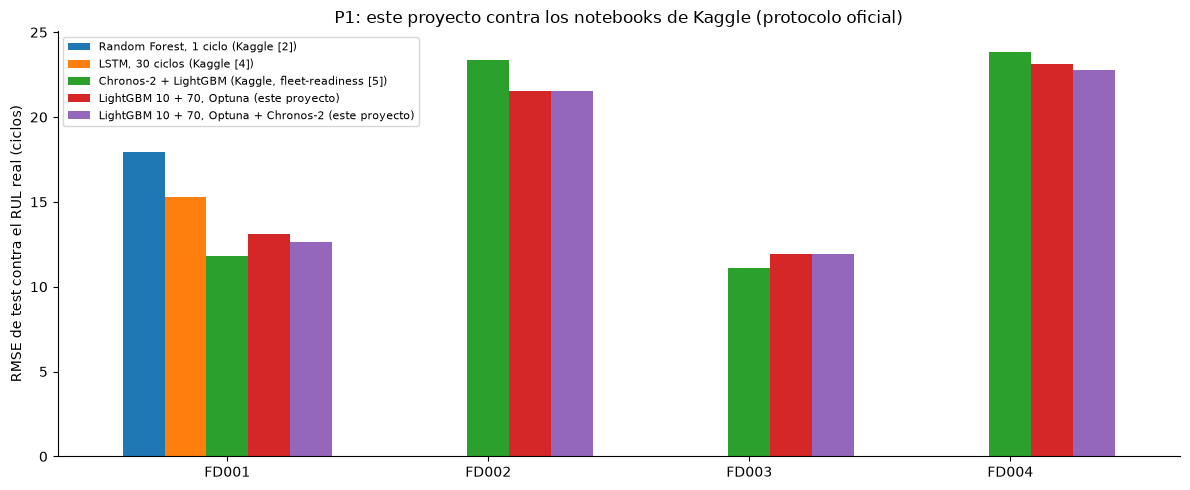

,FD001,FD002,FD003,FD004,Promedio
"Random Forest, 1 ciclo (Kaggle [2])",17.96,NaN,NaN,NaN,NaN
"LSTM, 30 ciclos (Kaggle [4])",15.30,NaN,NaN,NaN,NaN
"Chronos-2 + LightGBM (Kaggle, fleet-readiness [5])",11.79,23.38,11.13,23.86,17.54
"LightGBM 10 + 70, Optuna (este proyecto)",13.10,21.55,11.91,23.12,17.42
"LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto)",12.66,21.51,11.90,22.79,17.22


In [56]:
# 1. RMSE de test (RUL real) reportado por los notebooks de Kaggle con el protocolo oficial
kaggle = pd.DataFrame({
    "Random Forest, 1 ciclo (Kaggle [2])": {"FD001": 17.96},
    "LSTM, 30 ciclos (Kaggle [4])": {"FD001": 15.30},
    "Chronos-2 + LightGBM (Kaggle, fleet-readiness [5])": {"FD001": 11.79, "FD002": 23.38, "FD003": 11.13, "FD004": 23.86},
}).T[Subsets]

# 2. RMSE de test de este proyecto: modelo final (9.5) y con Chronos-2 (9.11)
con_chronos = test_chronos[test_chronos["modelo"] == "LightGBM + Chronos-2"].set_index("subset")
proyecto = pd.DataFrame({
    "LightGBM 10 + 70, Optuna (este proyecto)": tabla_test.loc[Subsets, "RMSE (RUL real)"],
    "LightGBM 10 + 70, Optuna + Chronos-2 (este proyecto)": con_chronos.loc[Subsets, "RMSE (RUL real)"],
}).T

# 3. Tabla conjunta; el promedio solo existe si el trabajo reporta los 4 subconjuntos
tabla_p1 = pd.concat([kaggle, proyecto])
tabla_p1["Promedio"] = tabla_p1[Subsets].mean(axis=1, skipna=False)

# 4. ¿En cuántos subconjuntos se supera al mejor notebook de Kaggle?
mejor_kaggle = kaggle.min()
for nombre, fila in proyecto.iterrows():
    gana = [fd for fd in Subsets if fila[fd] < mejor_kaggle[fd]]
    print(f"{nombre}: supera al mejor de Kaggle en {len(gana)} de 4 subconjuntos {gana}")

# 5. Gráfica: una barra por trabajo y subconjunto
ax = tabla_p1[Subsets].T.plot.bar(figsize=(12, 5), rot=0, width=0.8)
ax.set(xlabel="", ylabel="RMSE de test contra el RUL real (ciclos)",
       title="P1: este proyecto contra los notebooks de Kaggle (protocolo oficial)")
ax.legend(fontsize=8)
plt.tight_layout()
guardar_figura("Figura 15 - P1 comparación con los notebooks de Kaggle")
plt.show()
tabla_p1.round(2)

##### Interpretación:
- **Contra los dos notebooks de Kaggle que solo reportan FD001, el modelo de ventanas gana con claridad:** 13.10 contra 17.96 (Random Forest de un ciclo) y 15.30 (LSTM de 30 ciclos).
- **Contra *fleet-readiness*, el mejor notebook de Kaggle, gana en 2 de 4 subconjuntos:** FD002 (21.55 contra 23.38) y FD004 (23.12 contra 23.86), los dos con 6 condiciones de operación. Pierde en FD001 (13.10 contra 11.79) y FD003 (11.91 contra 11.13). Con Chronos-2 el resultado es el mismo: gana en FD002 y FD004 y reduce la diferencia en FD001 (12.66).
- **En el promedio de los 4 subconjuntos, este proyecto tiene el menor error:** 17.42 (17.22 con Chronos-2) contra 17.54.
- **Respuesta:** **sí en parte.** El modelo con ventanas deslizantes supera a todos los notebooks de Kaggle en el promedio y en los subconjuntos difíciles, pero **no cumple el criterio completo** ("superar en los 4 subconjuntos"), porque *fleet-readiness* es mejor en FD001 y FD003. Las diferencias en esos dos (≈ 0.8–1.3 ciclos) están dentro de la incertidumbre que reporta el propio *fleet-readiness* (intervalos de ≈ ±2 ciclos con 100 motores de test).

### 10.2 P2 · ¿Qué sensores anticipan mejor la degradación del motor?
**Criterio:** identificar un grupo de sensores que se mantenga relevante de forma **consistente** y que sea **coherente con la degradación física** del motor.

En 9.10 se midió la importancia con la **ganancia** de LightGBM, que tiene dos limitaciones: sale de un solo modelo por subconjunto (no dice si es consistente) y reparte el mérito entre sensores que suben juntos. Aquí se usa la **importancia por permutación por pliegue**, como se planteó en la propuesta:

1. En cada pliegue de la validación por motor se entrena el LightGBM final y se mide su RMSE en los motores de validación.
2. Se **revuelven** al azar los valores de un sensor (sus 12 columnas a la vez: 6 estadísticas × 2 ventanas) entre los ciclos de validación, rompiendo su relación con el RUL, y se vuelve a medir el RMSE.
3. La **importancia** es cuánto sube el RMSE: si el modelo depende de ese sensor, revolverlo aumenta mucho el error.

Se repite en los 5 pliegues de los 4 subconjuntos (20 mediciones por sensor). Un sensor es **consistente** si queda entre los más importantes en la mayoría de los pliegues.

**¿Qué hace el código?**
- `columnas` agrupa las columnas de cada sensor (y `cycle`, la edad del motor, como un grupo más).
- Para cada pliegue entrena el modelo, mide el RMSE base y el RMSE con cada sensor revuelto (`rng.permutation`, con semilla fija).
- `tabla_p2` muestra el aumento medio del RMSE por subconjunto, su promedio, cuánto varía entre los 20 pliegues y cuántas veces el sensor quedó entre los 5 más importantes de su pliegue.
- La gráfica muestra el aumento medio con su variación entre pliegues.

FD001 listo
FD002 listo
FD003 listo
FD004 listo


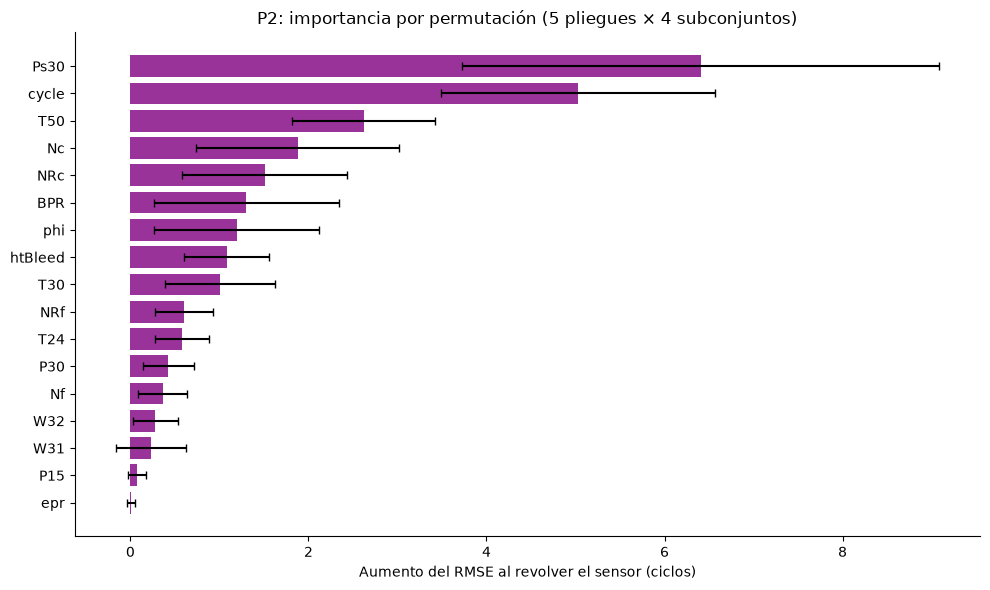

subset,FD001,FD002,FD003,FD004,Promedio,± entre pliegues,Veces en el top 5 (de 20)
sensor,,,,,,,
Ps30,2.47,8.14,6.39,8.62,6.40,2.68,20
cycle,4.20,7.09,5.22,3.59,5.03,1.54,20
T50,2.50,3.26,2.45,2.27,2.62,0.80,19
Nc,1.78,0.64,2.88,2.22,1.88,1.14,12
NRc,1.89,1.24,0.77,2.14,1.51,0.92,11
BPR,1.20,2.84,0.15,1.03,1.30,1.03,8
phi,1.15,0.23,2.47,0.92,1.19,0.93,4
htBleed,0.54,0.94,1.32,1.53,1.08,0.48,1
T30,0.51,0.46,1.56,1.50,1.01,0.62,3


In [ ]:
from sklearn.model_selection import GroupKFold

rng = np.random.default_rng(42)
filas = []
for fd in Subsets:
    d = datos[fd]
    X = X_comb[ventanas_elegidas, fd]
    y = d["y_train"].to_numpy()
    rul = d["y_train_real"].to_numpy()
    grupos = d["grupos"].to_numpy()

    # 1. Filas para entrenar y para evaluar (1 de cada 5 ciclos, RUL en el rango de test)
    entrenar = (X["cycle"] % 5 == 0).to_numpy()
    minimo, maximo = rango_test.loc[fd] # type: ignore
    evaluar = (rul >= minimo) & (rul <= maximo) & entrenar

    # 2. Columnas de cada sensor (12 por sensor) y la columna cycle como un grupo más
    columnas = {s: [c for c in X.columns if c.split("_")[0] == s] for s in sensores_por_subset[fd]}
    columnas["cycle"] = ["cycle"]

    # 3. En cada pliegue: RMSE base y RMSE con cada sensor revuelto
    divisor = GroupKFold(n_splits=5, shuffle=True, random_state=0)  # type: ignore
    for pliegue, (i_ent, i_val) in enumerate(divisor.split(X, y, grupos)):
        i_ent, i_val = i_ent[entrenar[i_ent]], i_val[evaluar[i_val]]
        modelo = receta_lgbm(parametros_finales)().fit(X.iloc[i_ent], y[i_ent])
        X_val = X.iloc[i_val]
        base = rmse(rul[i_val], np.clip(modelo.predict(X_val), 0, None)) # type: ignore
        for sensor, cols in columnas.items():
            X_revuelto = X_val.copy()
            X_revuelto[cols] = X_val[cols].to_numpy()[rng.permutation(len(X_val))]
            aumento = rmse(rul[i_val], np.clip(modelo.predict(X_revuelto), 0, None)) - base # type: ignore
            filas.append({"subset": fd, "pliegue": pliegue, "sensor": sensor, "aumento": aumento})
    print(f"{fd} listo")

permutacion = pd.DataFrame(filas)

# 4. Aumento medio del RMSE por sensor y subconjunto, variación entre pliegues y veces en el top 5
tabla_p2 = permutacion.groupby(["sensor", "subset"])["aumento"].mean().unstack()
tabla_p2["Promedio"] = tabla_p2[Subsets].mean(axis=1)
tabla_p2["± entre pliegues"] = permutacion.groupby("sensor")["aumento"].std()
permutacion["puesto"] = permutacion.groupby(["subset", "pliegue"])["aumento"].rank(ascending=False)
tabla_p2["Veces en el top 5 (de 20)"] = (permutacion["puesto"] <= 5).groupby(permutacion["sensor"]).sum()
tabla_p2 = tabla_p2.sort_values("Promedio", ascending=False)

# 5. Gráfica: aumento medio del RMSE con su variación entre los 20 pliegues
fig, ax = plt.subplots(figsize=(10, 6))
orden_p2 = tabla_p2.index[::-1]
ax.barh(orden_p2, tabla_p2.loc[orden_p2, "Promedio"], xerr=tabla_p2.loc[orden_p2, "± entre pliegues"],
        color="purple", alpha=0.8, capsize=3)
ax.set(xlabel="Aumento del RMSE al revolver el sensor (ciclos)", ylabel="",
       title="P2: importancia por permutación (5 pliegues × 4 subconjuntos)")
plt.tight_layout()
guardar_figura("Figura 16 - P2 importancia por permutación")
plt.show()
tabla_p2.round(2)

##### Interpretación:
- **Ps30 es el sensor más importante en los 4 subconjuntos y en los 20 pliegues:** queda entre los 5 más importantes en 20 de 20, y revolverlo sube el RMSE 6.4 ciclos en promedio (de 2.5 en FD001 a 8.6 en FD004).
- **T50 es el segundo sensor más consistente:** está en el top 5 en 19 de 20 pliegues (+2.6 ciclos). Le siguen **Nc y NRc**, la velocidad del núcleo real y corregida (12 y 11 de 20).
- **`cycle`, la edad del motor, también está en el top 5 en los 20 pliegues** (+5.0 ciclos), aunque no es un sensor: un motor con muchos vuelos tiende a estar más gastado.
- **Otros sensores solo importan en algunos subconjuntos:** BPR en FD002 (+2.8) y phi en FD003 (+2.5). FD003 tiene además degradación del ventilador, y ahí también gana peso Nc (+2.9).
- **El grupo es coherente con la física del motor.** Los 4 subconjuntos tienen degradación del **compresor de alta presión** (HPC). Un HPC gastado comprime peor, la presión estática a su salida (**Ps30**) cambia, el motor necesita más combustible para dar el mismo empuje y la temperatura de los gases a la salida de la turbina (**T50**) sube. La velocidad del núcleo (**Nc**, el eje que mueve el HPC) se ajusta para compensar. En 4.6 b) se vio que Ps30 y T50 son de los sensores que más suben al acercarse la falla.
- **Diferencia con la ganancia de 9.10:** T30 y htBleed tenían mucha ganancia, pero poca importancia por permutación (≈ 1 ciclo). Las temperaturas suben juntas: si se revuelve una, el modelo usa las otras y casi no pierde precisión. La permutación mide lo que **no se puede reemplazar**. Ps30 y T50 salen arriba con los dos métodos, así que esa conclusión es robusta.
- **Respuesta:** **sí.** Los sensores que mejor anticipan la degradación son **Ps30 y T50**, seguidos de la velocidad del núcleo (**Nc y NRc**). Son relevantes de forma consistente (en la mayoría de los 20 pliegues de los 4 subconjuntos) y coherentes con la degradación del compresor de alta presión. P15, epr, W31 y W32 casi no aportan (< 0.3 ciclos).

### 10.3 P3 · ¿Tomar en cuenta las condiciones de operación mejora la predicción?
**Criterio:** mejor desempeño en los subconjuntos con varias condiciones de operación (FD002 y FD004) al incorporarlas en el preprocesamiento.

En la sección 4.6 se vio en una gráfica que, sin normalizar por condición, el desgaste queda escondido detrás de los saltos entre condiciones. Aquí se mide su efecto en el error con **el mismo modelo** (LightGBM final, ventanas 10 + 70, parámetros de Optuna), cambiando solo el preprocesamiento:

| Variante | Preprocesamiento |
|:--|:--|
| Sin normalizar por condición | Una sola media y desviación por sensor para todo el subconjunto (z-score global). |
| Sin normalizar por condición + condición como columna | Igual, pero el modelo recibe la condición de vuelo como una columna más y puede aprender a corregirla por su cuenta. |
| Normalizado por condición (este proyecto) | Una media y una desviación por sensor **en cada condición** (sección 4). |

En las tres variantes las estadísticas se calculan solo con train. Se compara con la validación por motor (3 semillas) y, solo para reportar, en test.

**¿Qué hace el código?**
- Para FD002 y FD004 normaliza train y test con una sola media y desviación por sensor (`condicion="todas"`) y calcula las ventanas 10 + 70 de train y de test.
- `codigos` convierte cada condición en un número, para la variante con la condición como columna.
- Valida el mismo LightGBM con cada variante y 3 semillas, lo entrena con todos los motores de train y lo evalúa en test.
- La tabla muestra el RMSE de validación por subconjunto, su promedio y ruido, y el RMSE de test.

FD002 listo
FD004 listo


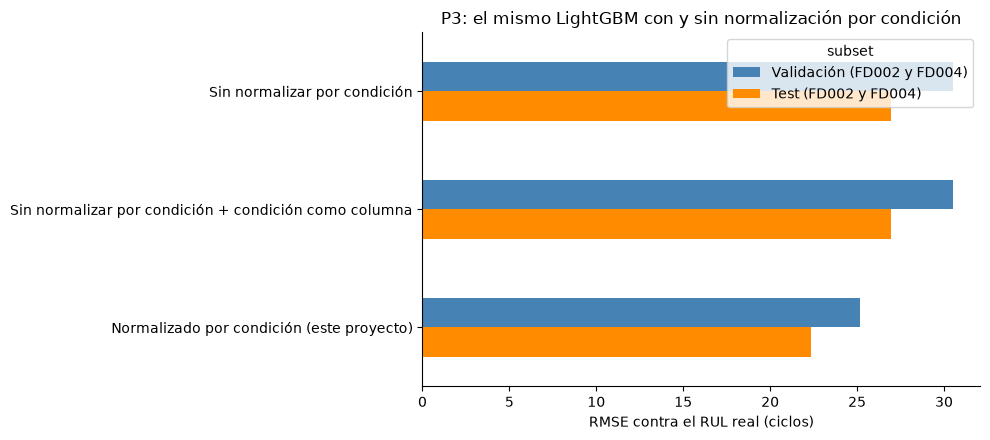

subset,FD002,FD004,Promedio,± ruido,Test FD002,Test FD004,Test promedio
variante,,,,,,,
Sin normalizar por condición,29.75,31.34,30.54,0.02,27.19,26.72,26.96
Sin normalizar por condición + condición como columna,29.73,31.35,30.54,0.01,27.13,26.79,26.96
Normalizado por condición (este proyecto),24.05,26.34,25.20,0.05,21.55,23.12,22.34


In [58]:
# 1. Condición de vuelo como número (para la variante con la condición como columna)
codigos = {c: i for i, c in enumerate(sorted(train["condicion"].unique()))}

variantes_p3 = {}
for fd in ["FD002", "FD004"]:
    s = sensores_por_subset[fd]
    tr = train[train["subset"] == fd]
    te = test[test["subset"] == fd]

    # 2. Sin condición: una sola media y desviación por sensor, calculadas solo con train
    tr_global = tr.assign(condicion="todas")
    te_global = te.assign(condicion="todas")
    estadisticas = ajustar_normalizador(tr_global, s)
    tr_global = normalizar(tr_global, estadisticas, s)
    te_global = normalizar(te_global, estadisticas, s)

    # 3. Ventanas 10 + 70 de train y del último ciclo de test, en el mismo orden que el resto del notebook
    X_tr = ventanas_combinadas(tr_global, s, *corta_larga).loc[datos[fd]["X_train"].index].copy()
    X_te = ventanas_combinadas(te_global, s, *corta_larga).loc[datos[fd]["X_test"].index].copy()
    X_te_proyecto = ventanas_combinadas(test_n[test_n["subset"] == fd], s, *corta_larga).loc[datos[fd]["X_test"].index]

    variantes_p3[fd] = {
        "Sin normalizar por condición": (X_tr, X_te),
        "Sin normalizar por condición + condición como columna": (
            X_tr.assign(condicion=tr.loc[X_tr.index, "condicion"].map(codigos)),
            X_te.assign(condicion=te.loc[X_te.index, "condicion"].map(codigos))),
        "Normalizado por condición (este proyecto)": (X_comb[ventanas_elegidas, fd], X_te_proyecto),
    }

# 4. Mismo LightGBM final con cada variante: validación con 3 semillas y evaluación en test
filas_val, filas_test = [], []
for fd, variantes in variantes_p3.items():
    y_real = datos[fd]["y_test"].to_numpy()
    for nombre, (X_tr, X_te) in variantes.items():
        for semilla in [0, 1, 2]:
            r = validar(fd, receta_lgbm(parametros_finales), X=X_tr, semilla=semilla)
            filas_val.append({"variante": nombre, "subset": fd, "semilla": semilla, "RMSE": r["RMSE"]})
        entrenar = (X_tr["cycle"] % 5 == 0).to_numpy()
        modelo = receta_lgbm(parametros_finales)().fit(X_tr[entrenar], datos[fd]["y_train"][entrenar])
        y_pred = np.clip(modelo.predict(X_te[X_tr.columns]), 0, None) # type: ignore
        filas_test.append({"variante": nombre, "subset": fd, "RMSE": rmse(y_real, y_pred)})
    print(f"{fd} listo")

# 5. Tabla: validación (promedio de 3 semillas y ruido) y test
val_p3 = pd.DataFrame(filas_val)
orden_p3 = list(variantes_p3["FD002"])
tabla_p3 = val_p3.groupby(["variante", "subset"])["RMSE"].mean().unstack().loc[orden_p3]
por_semilla = val_p3.groupby(["variante", "semilla"])["RMSE"].mean()
tabla_p3["Promedio"] = por_semilla.groupby("variante").mean()
tabla_p3["± ruido"] = por_semilla.groupby("variante").std()
test_p3 = pd.DataFrame(filas_test).pivot(index="variante", columns="subset", values="RMSE").loc[orden_p3]
tabla_p3[["Test FD002", "Test FD004"]] = test_p3[["FD002", "FD004"]].to_numpy()
tabla_p3["Test promedio"] = test_p3.mean(axis=1)

# 6. Gráfica: RMSE de validación y de test de cada variante
fig, ax = plt.subplots(figsize=(10, 4.5))
tabla_p3[["Promedio", "Test promedio"]].rename(
    columns={"Promedio": "Validación (FD002 y FD004)", "Test promedio": "Test (FD002 y FD004)"}
).plot.barh(ax=ax, color=["steelblue", "darkorange"])
ax.set(xlabel="RMSE contra el RUL real (ciclos)", ylabel="",
       title="P3: el mismo LightGBM con y sin normalización por condición")
ax.invert_yaxis()
plt.tight_layout()
guardar_figura("Figura 17 - P3 con y sin normalización por condición")
plt.show()
tabla_p3.round(2)

##### Interpretación:
- **Normalizar por condición baja el error de validación de 30.54 a 25.20 ciclos** (−5.3 ciclos, ≈ 17 %), en los dos subconjuntos: FD002 de 29.75 a 24.05 y FD004 de 31.34 a 26.34. La diferencia es 100 veces mayor que el ruido entre semillas (≤ 0.05).
- **En test se confirma:** de 26.96 a 22.34 en promedio (FD002 de 27.19 a 21.55, FD004 de 26.72 a 23.12).
- **Darle al modelo la condición como columna no ayuda** (30.54, igual que sin ella). Las estadísticas de la ventana (media, pendiente, mínimo y máximo de 70 ciclos) mezclan vuelos de las 6 condiciones, y una columna con la condición del ciclo actual no puede corregir esa mezcla. La normalización por condición corrige **cada ciclo antes** de calcular la ventana, así que la ventana solo ve el desgaste.
- **Respuesta:** **sí, se cumple el criterio.** Tomar en cuenta las condiciones de operación en el preprocesamiento (normalizar cada sensor dentro de su condición) mejora claramente la predicción en los dos subconjuntos con varias condiciones, y es la decisión que más reduce el error de todo el proyecto. En FD001 y FD003, que tienen una sola condición, las dos normalizaciones son idénticas.

---
## 11. Conclusiones

### Resultado principal
El modelo final, **LightGBM con ventanas de 10 + 70 ciclos, normalización por condición e hiperparámetros ajustados con Optuna**, predice el RUL de los 707 motores de test con un RMSE de **13.10 / 21.55 / 11.91 / 23.12 ciclos** (FD001–FD004), con un promedio de **17.42** contra el RUL real. Cerca de la falla (RUL < 50), donde se decide sacar un motor de servicio, el error es de solo **3.5–5.8 ciclos** y sin tendencia a avisar tarde. Al agregar los embeddings de Chronos-2 el promedio baja a **17.22**.

### Respuestas a las preguntas de investigación

| Pregunta | Respuesta | Evidencia |
|:--|:--|:--|
| **P1:** ¿un modelo con ventanas deslizantes supera a los notebooks de Kaggle? | **En parte.** Tiene el menor promedio (17.42 contra 17.54 del mejor notebook de Kaggle) y gana en FD002 y FD004, pero *fleet-readiness* es mejor en FD001 y FD003, así que no se cumple "superar en los 4 subconjuntos". | 9.6, 10.1 |
| **P2:** ¿qué sensores anticipan mejor la degradación? | **Ps30 y T50**, seguidos de la velocidad del núcleo (**Nc, NRc**). Ps30 está en el top 5 de importancia en 20 de 20 pliegues y T50 en 19 de 20; son coherentes con la degradación del compresor de alta presión. | 4.5, 4.6 b), 9.10, 10.2 |
| **P3:** ¿tomar en cuenta las condiciones de operación mejora la predicción? | **Sí.** Normalizar por condición baja el RMSE de FD002 y FD004 en 5.3 ciclos en validación y 4.6 en test, y darle la condición al modelo como columna no sustituye a la normalización. | 4.6, 10.3 |

### Qué decisiones aportaron más
Medido siempre con la misma validación por motor:

| Decisión | Efecto en el RMSE de validación | Sección |
|:--|:--|:--|
| Normalizar cada sensor por condición | −5.3 ciclos en FD002 y FD004 (30.54 → 25.20) | 10.3 |
| Usar ventanas de 70 ciclos en lugar de un solo ciclo | −5.5 ciclos (25.69 → 20.16, Random Forest) | 7.2 |
| LightGBM en lugar de Random Forest | −1.0 ciclos (20.15 → 19.17) | 8.3 |
| Agregar una ventana corta (10 + 70) | −0.2 ciclos (19.17 → 18.95) | 9.2 |
| Ajustar hiperparámetros con Optuna | −0.16 ciclos (18.94 → 18.78) | 9.4 |
| Agregar los embeddings de Chronos-2 | −0.19 ciclos (18.73 → 18.54) | 9.11 |

Las decisiones de **preprocesamiento** (normalización y ventanas) pesan mucho más que el modelo y sus hiperparámetros. Además, la validación por motor fue una buena guía: en 6.2 se mostró que separar por filas promete un error de 2.5–3.9 ciclos cuando el real es de ≈ 14, y el error de test (17.42) quedó cerca del de validación (18.78).

### Diferencias con la propuesta
- **Recorte del RUL a 130 en lugar de 125:** el análisis de 3.4 y 4.5 mostró que los sensores empiezan a cambiar alrededor de RUL ≈ 130.
- **LightGBM como sexto modelo:** se agregó para comparar con *fleet-readiness* y resultó el mejor, así que es el modelo final.
- **Importancia por permutación con LightGBM** (el modelo final) en lugar de Random Forest y XGBoost.
- **Prueba adicional con Chronos-2**, un modelo preentrenado, para ver si mejora a las características diseñadas a mano.

### Limitaciones
- **Los motores muy sanos (RUL > 130) tienen el mayor error** (≈ 40 ciclos en FD002 y FD004): el modelo, por el recorte, les predice ≈ 130. No es un defecto del modelo sino un límite del problema: un motor sano no muestra en sus sensores cuánto tiempo le queda. Por eso FD002 y FD004, con 21–24 % de motores sanos en test, tienen el RMSE total más alto.
- **Test es pequeño** (100 motores en FD001 y FD003): diferencias de ≈ 1–2 ciclos entre trabajos están dentro de la incertidumbre.
- **Los datos son simulados**; con motores reales habría más ruido, fallas de sensores y mantenimientos intermedios.
- Chronos-2 aporta poco (≈ 0.2 ciclos) a cambio de PyTorch, una GPU y un modelo de 28 millones de parámetros.


---
## Referencias

<a id="ref1"></a>[1] Saxena, A., Goebel, K., Simon, D., & Eklund, N. (2008). Damage propagation modeling for aircraft engine run-to-failure simulation. *Proceedings of the 1st International Conference on Prognostics and Health Management (PHM08)*, Denver, CO.

<a id="ref2"></a>[2] Kirstein, C. (2022). *Predictive Maintenance NASA turbofan Regression* [Notebook de Kaggle]. https://www.kaggle.com/code/carlkirstein/predictive-maintenance-nasa-turbofan-regression

<a id="ref3"></a>[3] Sahoo, B. *rul_codes_open: Remaining useful life prediction codes* [Repositorio de GitHub]. https://github.com/biswajitsahoo1111/rul_codes_open

<a id="ref4"></a>[4] Momt, Y. (2023). *RUL prediction using LSTM for Aircraft Engine* [Notebook de Kaggle]. https://www.kaggle.com/code/yahyamomtaz/rul-prediction-using-lstm-for-aircraft-engine

<a id="ref5"></a>[5] Elsamahy, A. E. (2026). *Fleet Readiness: Engine RUL on NASA C-MAPSS* [Notebook de Kaggle]. https://www.kaggle.com/code/amiresamelsamahy/fleet-readiness-engine-rul-on-nasa-c-mapss

<a id="ref6"></a>[6] Saxena, A., & Goebel, K. (2008). *Turbofan Engine Degradation Simulation Data Set* [Conjunto de datos]. NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.

<a id="ref7"></a>[7] Ansari, A. F., et al. (2025). *Chronos-2: From Univariate to Universal Forecasting* [Preimpresión]. Amazon Web Services. Modelo usado: https://huggingface.co/autogluon/chronos-2-small

<a id="ref8"></a>[8] Ke, G., Meng, Q., Finley, T., Wang, T., Chen, W., Ma, W., Ye, Q., & Liu, T.-Y. (2017). LightGBM: A highly efficient gradient boosting decision tree. *Advances in Neural Information Processing Systems 30 (NeurIPS 2017)*.

<a id="ref9"></a>[9] Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining*, 2623–2631.

<a id="ref10"></a>[10] Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

<a id="ref11"></a>[11] Munguía, A. (2023, 31 de octubre). Volaris despide a 200 empleados por problemas con motores. *El Financiero*.

<a id="ref12"></a>[12] Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 785–794.

---
## Declaración de uso de IA generativa

En este proyecto usé **Claude (Anthropic, modelo Claude Opus 5.5)** a través de **Claude Code**, como asistente durante el desarrollo.

Soy responsable del contenido completo del notebook, incluidos los errores que pueda tener.